In [59]:
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

# Locate repository root
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks2":
    ROOT = ROOT.parent

DATA_ORIGINAL = ROOT / "data" / "raw"
DATA_SORTED = ROOT / "data" / "sorted_data"

TABLES = ROOT / "tables2"
FIGURES = ROOT / "figures2"

TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

print("Repository:", ROOT)
print("Original data exists:", DATA_ORIGINAL.exists())
print("Sorted data exists:", DATA_SORTED.exists())
print("Tables folder:", TABLES)
print("Figures folder:", FIGURES)

Repository: C:\Users\shafi\number-simplex-reproduction
Original data exists: True
Sorted data exists: True
Tables folder: C:\Users\shafi\number-simplex-reproduction\tables2
Figures folder: C:\Users\shafi\number-simplex-reproduction\figures2


In [60]:
subjects = ["YFM", "YFS", "YFT"]

for subject in subjects:
    print(f"\n{'=' * 50}")
    print(f"Subject: {subject}")

    files = sorted(DATA_ORIGINAL.rglob(f"*{subject}*"))

    if files:
        for path in files[:20]:
            print(path.relative_to(ROOT))
    else:
        print("No files with subject name in filename.")

print("\nOriginal data directory (first 30 files):")
for path in list(DATA_ORIGINAL.rglob("*.mat"))[:30]:
    print(path.relative_to(ROOT))


Subject: YFM
data\raw\YFM

Subject: YFS
data\raw\YFS

Subject: YFT
data\raw\YFT

Original data directory (first 30 files):
data\raw\YFU\arithmetic\photoBehavEvents.mat
data\raw\YFU\arithmetic\spikes.mat
data\raw\YFU\dot\photoBehavEvents.mat
data\raw\YFU\dot\spikes.mat
data\raw\YFT\arithmetic\photoBehavEvents.mat
data\raw\YFT\arithmetic\spikes.mat
data\raw\YFT\dot\photoBehavEvents.mat
data\raw\YFT\dot\spikes.mat
data\raw\YFS\arithmetic\photoBehavEvents.mat
data\raw\YFS\arithmetic\spikes.mat
data\raw\YFS\dot\photoBehavEvents.mat
data\raw\YFS\dot\spikes.mat
data\raw\YFR\arithmetic\photoBehavEvents.mat
data\raw\YFR\arithmetic\spikes.mat
data\raw\YFR\dot\photoBehavEvents.mat
data\raw\YFR\dot\spikes.mat
data\raw\YFP\arithmetic\photoBehavEvents.mat
data\raw\YFP\arithmetic\spikes.mat
data\raw\YFM\arithmetic\photoBehavEvents.mat
data\raw\YFM\arithmetic\spikesArithmetic.mat
data\raw\YFM\dot\photoBehavEvents.mat
data\raw\YFM\dot\spikesDot.mat
data\raw\YFL\arithmetic\photoBehavEvents.mat
data\raw

In [61]:
subjects = {
    "YFM": ("spikesArithmetic.mat", "spikesArithmetic"),
    "YFS": ("spikes.mat", "spikes"),
    "YFT": ("spikes.mat", "spikes"),
}

results = []

for subject, (filename, variable) in subjects.items():

    old_path = DATA_ORIGINAL / subject / "arithmetic" / filename
    new_path = DATA_SORTED / subject / "arithmetic" / filename

    with h5py.File(old_path, "r") as old, \
         h5py.File(new_path, "r") as new:

        # MATLAB sparse matrix: row count stored in metadata
        old_units = int(old[variable].attrs["MATLAB_sparse"])
        new_units = int(new[variable].attrs["MATLAB_sparse"])

        flags = np.asarray(new["isSingleUnit"]).ravel()

        results.append({
            "Subject": subject,
            "Original units": old_units,
            "New units": new_units,
            "Difference": new_units - old_units,
            "New single units": int(np.sum(flags == 1)),
            "New non-SU units": int(np.sum(flags == 0)),
        })

comparison = pd.DataFrame(results)

display(comparison)

,Subject,Original units,New units,Difference,New single units,New non-SU units
0,YFM,94,198,104,180,18
1,YFS,96,244,148,201,43
2,YFT,89,174,85,151,23


In [62]:
# Inspect region metadata before calculating MTL counts

for subject, (filename, variable) in subjects.items():
    print(f"\n{'=' * 45}")
    print("Subject:", subject)

    for label, base in [
        ("Original", DATA_ORIGINAL),
        ("New", DATA_SORTED),
    ]:
        path = base / subject / "arithmetic" / filename

        with h5py.File(path, "r") as f:
            regions = f["regionsVect"]

            print(f"\n{label}:")
            print("regionsVect shape:", regions.shape)
            print("MATLAB class:", regions.attrs.get("MATLAB_class"))
            print("First 5 region references:", regions[:5].ravel())


Subject: YFM

Original:
regionsVect shape: (1, 94)
MATLAB class: b'cell'
First 5 region references: [<HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference> <HDF5 object reference> <HDF5 object reference>
 <HDF5 object reference

In [63]:
from collections import Counter

MTL_REGIONS = {"hpc", "ent", "amy", "para-hpc"}

def read_regions(f):
    refs = f["regionsVect"][:].ravel()

    return [
        "".join(chr(int(c)) for c in f[ref][:].ravel())
        .strip()
        .lower()
        for ref in refs
    ]

rows = []

for subject, (filename, variable) in subjects.items():

    old_path = DATA_ORIGINAL / subject / "arithmetic" / filename
    new_path = DATA_SORTED / subject / "arithmetic" / filename

    with h5py.File(old_path, "r") as old, \
         h5py.File(new_path, "r") as new:

        old_regions = read_regions(old)
        new_regions = read_regions(new)
        flags = np.asarray(new["isSingleUnit"]).ravel()

        assert len(old_regions) == int(
            old[variable].attrs["MATLAB_sparse"]
        )
        assert len(new_regions) == len(flags)

        for region in sorted(set(old_regions) | set(new_regions)):

            old_count = old_regions.count(region)
            new_count = new_regions.count(region)

            new_su = sum(
                r == region and flag == 1
                for r, flag in zip(new_regions, flags)
            )

            rows.append({
                "Subject": subject,
                "Region": region,
                "Original units": old_count,
                "New units": new_count,
                "Difference": new_count - old_count,
                "New SU units": new_su,
                "MTL": region in MTL_REGIONS,
            })

region_comparison = pd.DataFrame(rows)

display(region_comparison)

print("\nMTL TOTALS")
display(
    region_comparison[region_comparison["MTL"]]
    .groupby("Subject")[
        ["Original units", "New units", "Difference", "New SU units"]
    ]
    .sum()
)

,Subject,Region,Original units,New units,Difference,New SU units,MTL
0,YFM,ent,29,69,40,58,True
1,YFM,hpc,32,60,28,60,True
2,YFM,ofc,26,58,32,51,False
3,YFM,thal,0,11,11,11,False
4,YFM,thalamus,7,0,-7,0,False
5,YFS,acc,17,41,24,41,False
6,YFS,amy,22,53,31,32,True
7,YFS,hpc,37,91,54,75,True
8,YFS,ofc,9,25,16,20,False
9,YFS,thal,11,34,23,33,False



MTL TOTALS


,Original units,New units,Difference,New SU units
Subject,,,,
YFM,61,129,68,118
YFS,59,144,85,107
YFT,52,91,39,78


In [64]:
from scipy.io import loadmat

for subject in subjects:
    print(f"\n{'='*40}")
    print(f"SUBJECT: {subject}")

    for task in ["arithmetic", "dot"]:
        path = DATA_SORTED / subject / task / "photoBehavEvents.mat"

        print(f"\n{task.upper()}")
        print("File exists:", path.exists())

        if path.exists():
            with open(path, "rb") as f:
                print("File header:", f.read(80)[:60])

            try:
                data = loadmat(path)
                print("MATLAB variables:", [
                    k for k in data.keys()
                    if not k.startswith("__")
                ])
            except Exception as e:
                print("loadmat error:", str(e))


SUBJECT: YFM

ARITHMETIC
File exists: True
File header: b'MATLAB 5.0 MAT-file, Platform: MACA64, Created on: Fri Apr 1'
MATLAB variables: ['photoBehavEvents']

DOT
File exists: True
File header: b'MATLAB 5.0 MAT-file, Platform: MACA64, Created on: Fri Apr 1'
MATLAB variables: ['photoBehavEvents']

SUBJECT: YFS

ARITHMETIC
File exists: True
File header: b'MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Thu Feb '
MATLAB variables: ['photoBehavEvents']

DOT
File exists: True
File header: b'MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Sun Feb '
MATLAB variables: ['photoBehavEvents']

SUBJECT: YFT

ARITHMETIC
File exists: True
File header: b'MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Fri Aug '
MATLAB variables: ['photoBehavEvents']

DOT
File exists: True
File header: b'MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Sun Feb '
MATLAB variables: ['photoBehavEvents']


In [65]:
for subject in subjects:
    print(f"\n{'='*45}")
    print(f"SUBJECT: {subject}")

    for task in ["arithmetic", "dot"]:
        path = DATA_SORTED / subject / task / "photoBehavEvents.mat"

        data = loadmat(path, squeeze_me=True, struct_as_record=False)
        events = data["photoBehavEvents"]

        print(f"\n{task.upper()}")
        print("Shape:", events.shape)
        print("Data type:", events.dtype)

        if events.size > 0:
            first = events.flat[0]
            print("Fields:", getattr(first, "_fieldnames", None))


SUBJECT: YFM

ARITHMETIC
Shape: (1,)
Data type: [('_TypeSystem', 'O'), ('_Class', 'O'), ('_ObjectMetadata', 'O')]
Fields: None

DOT
Shape: (1,)
Data type: [('_TypeSystem', 'O'), ('_Class', 'O'), ('_ObjectMetadata', 'O')]
Fields: None

SUBJECT: YFS

ARITHMETIC
Shape: (1,)
Data type: [('_TypeSystem', 'O'), ('_Class', 'O'), ('_ObjectMetadata', 'O')]
Fields: None

DOT
Shape: (1,)
Data type: [('_TypeSystem', 'O'), ('_Class', 'O'), ('_ObjectMetadata', 'O')]
Fields: None

SUBJECT: YFT

ARITHMETIC
Shape: (1,)
Data type: [('_TypeSystem', 'O'), ('_Class', 'O'), ('_ObjectMetadata', 'O')]
Fields: None

DOT
Shape: (1,)
Data type: [('_TypeSystem', 'O'), ('_Class', 'O'), ('_ObjectMetadata', 'O')]
Fields: None


In [66]:
path = DATA_SORTED / "YFM" / "arithmetic" / "photoBehavEvents.mat"

data = loadmat(path, squeeze_me=True, struct_as_record=False)
events = data["photoBehavEvents"]

print("Type:", type(events))
print("Shape:", events.shape)
print("Field names:", events.dtype.names)

for field in events.dtype.names:
    value = events[field].flat[0]
    print(f"\nField: {field}")
    print("Type:", type(value))
    print("Shape:", np.shape(value))
    print("Preview:", str(value)[:300])

Type: <class 'scipy.io.matlab._mio5_params.MatlabOpaque'>
Shape: (1,)
Field names: ('_TypeSystem', '_Class', '_ObjectMetadata')

Field: _TypeSystem
Type: <class 'str'>
Shape: ()
Preview: MCOS

Field: _Class
Type: <class 'str'>
Shape: ()
Preview: table

Field: _ObjectMetadata
Type: <class 'numpy.ndarray'>
Shape: (6,)
Preview: [3707764736          2          1          1          1          2]


In [67]:
path = DATA_SORTED / "YFM" / "arithmetic" / "photoBehavEvents.mat"

data = loadmat(path, squeeze_me=True, struct_as_record=False)

for name, value in data.items():
    print(
        f"{name:25s}",
        "Type:", type(value).__name__,
        "Shape:", np.shape(value)
    )

__header__                Type: bytes Shape: ()
__version__               Type: str Shape: ()
__globals__               Type: list Shape: (0,)
photoBehavEvents          Type: MatlabOpaque Shape: (1,)
__function_workspace__    Type: ndarray Shape: (1, 23064)


In [68]:
import shutil

for subject in subjects:
    for task in ["arithmetic", "dot"]:
        source = DATA_ORIGINAL / subject / task / "photoBehavEvents.csv"
        destination = DATA_SORTED / subject / task / "photoBehavEvents.csv"

        if not source.exists():
            print(f"MISSING: {source}")
            continue

        if destination.exists():
            print(f"ALREADY EXISTS: {destination}")
            continue

        shutil.copy2(source, destination)
        print(f"COPIED: {subject} / {task}")

print("\nBehavioral CSV preparation complete.")

ALREADY EXISTS: C:\Users\shafi\number-simplex-reproduction\data\sorted_data\YFM\arithmetic\photoBehavEvents.csv
MISSING: C:\Users\shafi\number-simplex-reproduction\data\raw\YFM\dot\photoBehavEvents.csv
ALREADY EXISTS: C:\Users\shafi\number-simplex-reproduction\data\sorted_data\YFS\arithmetic\photoBehavEvents.csv
MISSING: C:\Users\shafi\number-simplex-reproduction\data\raw\YFS\dot\photoBehavEvents.csv
ALREADY EXISTS: C:\Users\shafi\number-simplex-reproduction\data\sorted_data\YFT\arithmetic\photoBehavEvents.csv
MISSING: C:\Users\shafi\number-simplex-reproduction\data\raw\YFT\dot\photoBehavEvents.csv

Behavioral CSV preparation complete.


In [69]:
for subject in subjects:
    path = DATA_SORTED / subject / "arithmetic" / "photoBehavEvents.csv"

    df = pd.read_csv(path)

    print(f"\n{'='*45}")
    print(f"SUBJECT: {subject}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))


SUBJECT: YFM
Shape: (100, 22)
Columns: ['trial', 'tCue1', 'tCue2', 'tCue3', 'presentationEnd', 'tPress1', 'tPress2', 'tPress3', 'keyPress1', 'keyPress2', 'keyPress3', 'choiceEnd', 'timeFeedback', 'cue1', 'cue2', 'operation', 'operationFirst', 'correctAnsw', 'givenAnsw', 'correct', 'correctFb', 'toExclude']


,trial,tCue1,tCue2,tCue3,presentationEnd,tPress1,tPress2,tPress3,keyPress1,keyPress2,...,timeFeedback,cue1,cue2,operation,operationFirst,correctAnsw,givenAnsw,correct,correctFb,toExclude
0,1,136305.733333,137055.700000,137805.700000,138572.366667,142688.966667,142855.7,NaN,End,PageDown,...,148688.833333,15,2,-,0,13,NaN,0,1,0
1,2,149172.200000,149938.833333,150688.833333,151438.800000,157622.066667,NaN,NaN,8,NaN,...,159738.666667,16,8,-,0,8,8.0,1,1,0
2,3,160238.666667,160988.666667,161738.633333,162505.300000,169571.866667,NaN,NaN,4,NaN,...,170371.833333,15,11,-,0,4,4.0,1,1,0



SUBJECT: YFS
Shape: (160, 22)
Columns: ['trial', 'tCue1', 'tCue2', 'tCue3', 'presentationEnd', 'tPress1', 'tPress2', 'tPress3', 'keyPress1', 'keyPress2', 'keyPress3', 'choiceEnd', 'timeFeedback', 'cue1', 'cue2', 'operation', 'operationFirst', 'correctAnsw', 'givenAnsw', 'correct', 'correctFb', 'toExclude']


,trial,tCue1,tCue2,tCue3,presentationEnd,tPress1,tPress2,tPress3,keyPress1,keyPress2,...,timeFeedback,cue1,cue2,operation,operationFirst,correctAnsw,givenAnsw,correct,correctFb,toExclude
0,1,16352.200000,17102.166667,17852.166667,18602.166667,19452.166667,NaN,NaN,7,NaN,...,29001.966667,6,1,+,0,7,7,1,1,0
1,2,29485.333333,30235.300000,30985.300000,31735.266667,32435.266667,NaN,NaN,6,NaN,...,33435.233333,3,3,+,0,6,6,1,1,0
2,3,33935.233333,34685.233333,35435.233333,36185.200000,37651.866667,NaN,NaN,0,NaN,...,38518.500000,0,0,+,0,0,0,1,1,0



SUBJECT: YFT
Shape: (300, 22)
Columns: ['trial', 'tCue1', 'tCue2', 'tCue3', 'presentationEnd', 'tPress1', 'tPress2', 'tPress3', 'keyPress1', 'keyPress2', 'keyPress3', 'choiceEnd', 'timeFeedback', 'cue1', 'cue2', 'operation', 'operationFirst', 'correctAnsw', 'givenAnsw', 'correct', 'correctFb', 'toExclude']


,trial,tCue1,tCue2,tCue3,presentationEnd,tPress1,tPress2,tPress3,keyPress1,keyPress2,...,timeFeedback,cue1,cue2,operation,operationFirst,correctAnsw,givenAnsw,correct,correctFb,toExclude
0,1,6532.800000,7282.8,8032.766667,8782.766667,13166.033333,NaN,NaN,0,NaN,...,14182.666667,4,4,-,1,0,0,1,1,0
1,2,14682.666667,15416.0,16182.633333,16915.966667,18032.633333,NaN,NaN,5,NaN,...,19065.933333,10,5,-,0,5,5,1,1,0
2,3,19565.933333,20315.9,21065.900000,21815.900000,24799.200000,25065.833333,NaN,1,2.0,...,25982.466667,4,8,+,1,12,12,1,1,0


In [70]:
for subject in subjects:
    path = DATA_SORTED / subject / "arithmetic" / "photoBehavEvents.csv"
    df = pd.read_csv(path)

    print(f"\n{'='*45}")
    print(f"SUBJECT: {subject}")

    print("\nOperation-first counts:")
    print(df["operationFirst"].value_counts(dropna=False))

    print("\nOperation counts:")
    print(df["operation"].value_counts(dropna=False))

    print("\nExcluded trials:")
    print(df["toExclude"].value_counts(dropna=False))

    print("\nCue timing differences (milliseconds):")
    print("tCue2 - tCue1:", (df["tCue2"] - df["tCue1"]).median())
    print("tCue3 - tCue2:", (df["tCue3"] - df["tCue2"]).median())
    


SUBJECT: YFM

Operation-first counts:
operationFirst
0    55
1    45
Name: count, dtype: int64

Operation counts:
operation
+    56
-    44
Name: count, dtype: int64

Excluded trials:
toExclude
0    100
Name: count, dtype: int64

Cue timing differences (milliseconds):
tCue2 - tCue1: 750.0
tCue3 - tCue2: 750.0

SUBJECT: YFS

Operation-first counts:
operationFirst
0    160
Name: count, dtype: int64

Operation counts:
operation
+    160
Name: count, dtype: int64

Excluded trials:
toExclude
0    160
Name: count, dtype: int64

Cue timing differences (milliseconds):
tCue2 - tCue1: 750.0
tCue3 - tCue2: 750.0

SUBJECT: YFT

Operation-first counts:
operationFirst
0    155
1    145
Name: count, dtype: int64

Operation counts:
operation
+    154
-    146
Name: count, dtype: int64

Excluded trials:
toExclude
0    300
Name: count, dtype: int64

Cue timing differences (milliseconds):
tCue2 - tCue1: 749.9666666700505
tCue3 - tCue2: 750.0


In [71]:
for subject in subjects:
    path = DATA_SORTED / subject / "arithmetic" / "photoBehavEvents.csv"
    df = pd.read_csv(path)

    print(f"\n{'='*45}")
    print(f"SUBJECT: {subject}")

    for column in ["cue1", "cue2"]:
        print(f"\n{column} distribution:")
        print(df[column].value_counts().sort_index())

    print("\nUnique answers:")
    print(sorted(df["correctAnsw"].dropna().unique()))


SUBJECT: YFM

cue1 distribution:
cue1
0      6
1     11
2     10
3      8
4      3
5      4
6      8
7      4
8      8
9      2
10     5
11     2
12     4
13     5
14     5
15    11
16     4
Name: count, dtype: int64

cue2 distribution:
cue2
0      6
1      8
2      7
3      6
4      1
5     10
6      8
7      6
8      4
9      6
10     4
11    11
12     5
13     6
14     3
15     2
16     7
Name: count, dtype: int64

Unique answers:
[np.int64(-15), np.int64(-13), np.int64(-12), np.int64(-10), np.int64(-9), np.int64(-8), np.int64(-6), np.int64(-5), np.int64(-4), np.int64(-3), np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(18), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(26), np.int64(28), np.int64(32)]

SUBJECT: YFS

cue1 distribution:


In [72]:
presentation_summary = []

for subject in subjects:
    path = DATA_SORTED / subject / "arithmetic" / "photoBehavEvents.csv"
    df = pd.read_csv(path)

    valid_trials = df[df["toExclude"] == 0]

    cue1_counts = valid_trials["cue1"].value_counts()
    cue2_counts = valid_trials["cue2"].value_counts()

    counts = (
        cue1_counts.add(cue2_counts, fill_value=0)
        .reindex(range(1, 10), fill_value=0)
        .astype(int)
    )

    presentation_summary.append({
        "Subject": subject,
        "Trials": len(valid_trials),
        "Presentations (1–9)": int(counts.sum()),
        **{f"Number {n}": int(counts[n]) for n in range(1, 10)}
    })

presentation_summary = pd.DataFrame(presentation_summary)
display(presentation_summary)

,Subject,Trials,Presentations (1–9),Number 1,Number 2,Number 3,Number 4,Number 5,Number 6,Number 7,Number 8,Number 9
0,YFM,100,114,19,17,14,4,14,16,10,12,8
1,YFS,160,264,32,33,24,33,32,24,27,30,29
2,YFT,300,477,62,48,52,57,53,56,43,50,56


In [73]:
for subject in subjects:
    df = pd.read_csv(
        DATA_SORTED / subject / "arithmetic" / "photoBehavEvents.csv"
    )

    print(f"\nSUBJECT: {subject}")

    display(
        df[
            ["trial", "cue1", "cue2", "operation",
             "operationFirst", "tCue1", "tCue2", "tCue3"]
        ].head(5)
    )


SUBJECT: YFM


,trial,cue1,cue2,operation,operationFirst,tCue1,tCue2,tCue3
0,1,15,2,-,0,136305.733333,137055.700000,137805.700000
1,2,16,8,-,0,149172.200000,149938.833333,150688.833333
2,3,15,11,-,0,160238.666667,160988.666667,161738.633333
3,4,1,13,+,0,170871.833333,171621.833333,172371.800000
4,5,8,7,+,0,176521.766667,177271.733333,178021.733333



SUBJECT: YFS


,trial,cue1,cue2,operation,operationFirst,tCue1,tCue2,tCue3
0,1,6,1,+,0,16352.200000,17102.166667,17852.166667
1,2,3,3,+,0,29485.333333,30235.300000,30985.300000
2,3,0,0,+,0,33935.233333,34685.233333,35435.233333
3,4,7,9,+,0,39018.500000,39768.466667,40518.466667
4,5,8,10,+,0,46751.700000,47501.700000,48251.666667



SUBJECT: YFT


,trial,cue1,cue2,operation,operationFirst,tCue1,tCue2,tCue3
0,1,4,4,-,1,6532.800000,7282.800000,8032.766667
1,2,10,5,-,0,14682.666667,15416.000000,16182.633333
2,3,4,8,+,1,19565.933333,20315.900000,21065.900000
3,4,3,1,-,1,26482.500000,27232.466667,27982.466667
4,5,0,10,-,1,31582.400000,32332.400000,33082.366667


In [74]:
from pathlib import Path

keywords = ["operationFirst", "tCue1", "tCue2", "tCue3"]

# Search existing notebooks and Python scripts
search_folders = ["notebooks", "notebooks1", "notebooks2", "src"]

for folder in search_folders:
    folder_path = ROOT / folder

    if not folder_path.exists():
        continue

    for file in folder_path.rglob("*"):
        if file.suffix not in [".py", ".ipynb"]:
            continue

        if ".ipynb_checkpoints" in str(file):
            continue

        try:
            lines = file.read_text(encoding="utf-8").splitlines()
        except Exception:
            continue

        matches = [
            (i, line.strip())
            for i, line in enumerate(lines, start=1)
            if any(keyword in line for keyword in keywords)
        ]

        if matches:
            print(f"\nFILE: {file.relative_to(ROOT)}")

            for line_number, line in matches[:10]:
                print(f"  Line {line_number}: {line[:180]}")


FILE: notebooks\01_explore_data.ipynb
  Line 728: "      <th>tCue1</th>\n",
  Line 729: "      <th>tCue2</th>\n",
  Line 730: "      <th>tCue3</th>\n",
  Line 742: "      <th>operationFirst</th>\n",
  Line 877: "   trial         tCue1         tCue2         tCue3  presentationEnd  \\\n",
  Line 891: "   timeFeedback  cue1  cue2  operation  operationFirst correctAnsw  givenAnsw  \\\n",
  Line 951: "tCue1              701090.433333\n",
  Line 952: "tCue2              701824.433333\n",
  Line 953: "tCue3              702575.166667\n",
  Line 970: "    \"tCue1\",\n",

FILE: notebooks\02_arithmetic_spike_anlyse.ipynb
  Line 135: "      <th>tCue1</th>\n",
  Line 136: "      <th>tCue2</th>\n",
  Line 137: "      <th>tCue3</th>\n",
  Line 149: "      <th>operationFirst</th>\n",
  Line 284: "   trial         tCue1         tCue2         tCue3  presentationEnd  \\\n",
  Line 298: "   timeFeedback  cue1  cue2  operation  operationFirst correctAnsw  givenAnsw  \\\n",
  Line 346: "        df[\"opera

In [75]:
import json

# 1. Read Python source
path = ROOT / "src" / "firing_rate_tuning.py"
lines = path.read_text(encoding="utf-8").splitlines()

print("\n===== src/firing_rate_tuning.py =====")
for i in range(145, min(205, len(lines))):
    print(f"{i+1}: {lines[i]}")

# 2. Read relevant notebook code cells
notebooks = [
    "02_arithmetic_spike_anlyse.ipynb",
    "popdecoding.ipynb"
]

for name in notebooks:
    path = ROOT / "notebooks" / name

    with path.open(encoding="utf-8") as f:
        nb = json.load(f)

    print(f"\n===== {name} =====")

    for cell in nb["cells"]:
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        if (
            "operationFirst" in source
            and ("operand1" in source or "operand2" in source)
        ):
            print(source[:3500])
            print("-" * 50)


===== src/firing_rate_tuning.py =====
146:     ].copy()
147: 
148:     # Special case:
149:     # For YFR and YFS, the operation sign was always presented
150:     # as the second stimulus (Cue2 position).
151:     #
152:     # Therefore:
153:     #   operand 1 -> first presentation  -> tCue1
154:     #   operation -> second presentation -> tCue2
155:     #   operand 2 -> third presentation  -> tCue3
156:     #
157:     # For all other subjects, use operationFirst.
158: 
159:     if subject in {"YFR", "YFS"}:
160: 
161:         operand_data["operand1_onset"] = operand_data["tCue1"]
162:         operand_data["operand2_onset"] = operand_data["tCue3"]
163: 
164:     else:
165: 
166:     # operationFirst = 0:
167:     # operand1 -> first presentation
168:     # operand2 -> second presentation
169:     #
170:     # operationFirst = 1:
171:     # operation -> first presentation
172:     # operand1 -> second presentation
173:     # operand2 -> third presentation
174: 
175:         operand_da

In [76]:
arithmetic_presentations = {}

for subject in subjects:
    df = pd.read_csv(
        DATA_SORTED / subject / "arithmetic" / "photoBehavEvents.csv"
    )

    df = df[df["toExclude"] == 0].copy()

    if subject in {"YFR", "YFS"}:
        df["operand1_onset"] = df["tCue1"]
        df["operand2_onset"] = df["tCue3"]
    else:
        df["operand1_onset"] = np.where(
            df["operationFirst"] == 1,
            df["tCue2"],
            df["tCue1"]
        )
        df["operand2_onset"] = np.where(
            df["operationFirst"] == 1,
            df["tCue3"],
            df["tCue2"]
        )

    op1 = df[["trial", "cue1", "operand1_onset"]].copy()
    op1.columns = ["trial", "number", "onset"]
    op1["operand"] = 1

    op2 = df[["trial", "cue2", "operand2_onset"]].copy()
    op2.columns = ["trial", "number", "onset"]
    op2["operand"] = 2

    presentations = pd.concat(
        [op1, op2],
        ignore_index=True
    )

    presentations = presentations[
        presentations["number"].between(1, 9)
    ].copy()

    presentations = presentations.sort_values(
        ["onset", "trial", "operand"]
    ).reset_index(drop=True)

    arithmetic_presentations[subject] = presentations

    print(f"\n{'='*45}")
    print(f"SUBJECT: {subject}")
    print("Valid presentations:", len(presentations))
    print("Missing onsets:", presentations["onset"].isna().sum())
    print("Number distribution:")
    print(presentations["number"].value_counts().sort_index())

    display(presentations.head(5))


SUBJECT: YFM
Valid presentations: 114
Missing onsets: 0
Number distribution:
number
1    19
2    17
3    14
4     4
5    14
6    16
7    10
8    12
9     8
Name: count, dtype: int64


,trial,number,onset,operand
0,1,2,137055.700000,2
1,2,8,149938.833333,2
2,4,1,170871.833333,1
3,5,8,176521.766667,1
4,5,7,177271.733333,2



SUBJECT: YFS
Valid presentations: 264
Missing onsets: 0
Number distribution:
number
1    32
2    33
3    24
4    33
5    32
6    24
7    27
8    30
9    29
Name: count, dtype: int64


,trial,number,onset,operand
0,1,6,16352.200000,1
1,1,1,17852.166667,2
2,2,3,29485.333333,1
3,2,3,30985.300000,2
4,4,7,39018.500000,1



SUBJECT: YFT
Valid presentations: 477
Missing onsets: 0
Number distribution:
number
1    62
2    48
3    52
4    57
5    53
6    56
7    43
8    50
9    56
Name: count, dtype: int64


,trial,number,onset,operand
0,1,4,7282.800000,1
1,1,4,8032.766667,2
2,2,5,15416.000000,2
3,3,4,20315.900000,1
4,3,8,21065.900000,2


In [77]:
for subject, (spike_file, spike_key) in subjects.items():

    path = DATA_SORTED / subject / "arithmetic" / spike_file

    with h5py.File(path, "r") as f:
        spike_group = f[spike_key]

        # Handle scalar or single-element MATLAB sparse attribute
        n_neurons = int(
            np.asarray(spike_group.attrs["MATLAB_sparse"]).item()
        )

        n_timebins = len(spike_group["jc"]) - 1

    presentations = arithmetic_presentations[subject]

    window_start = np.floor(
        presentations["onset"].to_numpy() + 50
    ).astype(int)

    window_end = np.floor(
        presentations["onset"].to_numpy() + 950
    ).astype(int)

    valid = (
        (window_start >= 0) &
        (window_end <= n_timebins)
    )

    print(f"\n{'='*45}")
    print("SUBJECT:", subject)
    print("Spike matrix shape:", (n_neurons, n_timebins))
    print("Recording duration (seconds):", n_timebins / 1000)
    print("Presentations:", len(presentations))
    print("Valid windows:", valid.sum())
    print("Invalid windows:", (~valid).sum())
    print("Earliest window start:", window_start.min())
    print("Latest window end:", window_end.max())


SUBJECT: YFM
Spike matrix shape: (198, 808864)
Recording duration (seconds): 808.864
Presentations: 114
Valid windows: 114
Invalid windows: 0
Earliest window start: 137105
Latest window end: 803528

SUBJECT: YFS
Spike matrix shape: (244, 2215514)
Recording duration (seconds): 2215.514
Presentations: 264
Valid windows: 264
Invalid windows: 0
Earliest window start: 16402
Latest window end: 790856

SUBJECT: YFT
Spike matrix shape: (174, 3167227)
Recording duration (seconds): 3167.227
Presentations: 477
Valid windows: 477
Invalid windows: 0
Earliest window start: 7332
Latest window end: 1680955


In [78]:
from scipy.sparse import csc_matrix

arithmetic_spike_counts = {}

for subject, (spike_file, spike_key) in subjects.items():

    path = DATA_SORTED / subject / "arithmetic" / spike_file

    with h5py.File(path, "r") as f:
        group = f[spike_key]

        n_neurons = int(
            np.asarray(group.attrs["MATLAB_sparse"]).item()
        )

        jc = group["jc"][:]
        ir = group["ir"][:]
        data = group["data"][:]

        spikes = csc_matrix(
            (data, ir, jc),
            shape=(n_neurons, len(jc) - 1)
        )

    presentations = arithmetic_presentations[subject]

    starts = np.floor(
        presentations["onset"].to_numpy() + 50
    ).astype(int)

    ends = np.floor(
        presentations["onset"].to_numpy() + 950
    ).astype(int)

    # Each row = one number presentation
    # Each column = one recorded unit
    X = np.zeros(
        (len(presentations), n_neurons),
        dtype=np.int32
    )

    for i, (start, end) in enumerate(zip(starts, ends)):
        X[i] = np.asarray(
            spikes[:, start:end].sum(axis=1)
        ).ravel().astype(np.int32)

    arithmetic_spike_counts[subject] = X

    print(f"\n{'='*45}")
    print("SUBJECT:", subject)
    print("Population matrix shape:", X.shape)
    print("Total counted spikes:", X.sum())
    print("Minimum count:", X.min())
    print("Maximum count:", X.max())
    print("Zero-spike units:", np.sum(X.sum(axis=0) == 0))


SUBJECT: YFM
Population matrix shape: (114, 198)
Total counted spikes: 47169
Minimum count: 0
Maximum count: 30
Zero-spike units: 3

SUBJECT: YFS
Population matrix shape: (264, 244)
Total counted spikes: 113458
Minimum count: 0
Maximum count: 41
Zero-spike units: 0

SUBJECT: YFT
Population matrix shape: (477, 174)
Total counted spikes: 184140
Minimum count: 0
Maximum count: 50
Zero-spike units: 6


In [79]:
for subject, (spike_file, spike_key) in subjects.items():

    path = DATA_SORTED / subject / "arithmetic" / spike_file

    with h5py.File(path, "r") as f:

        print(f"\n{'='*45}")
        print("SUBJECT:", subject)

        print("Top-level keys:", list(f.keys()))

        regions = f["regionsVect"]

        print("regionsVect shape:", regions.shape)
        print("regionsVect dtype:", regions.dtype)

        print("\nFirst 5 region references and labels:")

        for ref in regions[:5].ravel():
            region_data = f[ref][:]
            region_name = "".join(
                chr(int(x)) for x in region_data.ravel()
            )
            print(region_name)


SUBJECT: YFM
Top-level keys: ['#refs#', 'electrodesVect', 'exportInfo', 'isSingleUnit', 'isiIntervalCount', 'isiViolationCount3ms', 'isiViolationPct3ms', 'regionsVect', 'sourceUnitIndex', 'spikesArithmetic']
regionsVect shape: (1, 198)
regionsVect dtype: object

First 5 region references and labels:
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
thal
thal
thal
thal
thal
thal
thal
thal
thal
thal
thal
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
ent
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc


hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc

SUBJECT: YFS
Top-level keys: ['#refs#', 'electrodesVect', 'exportInfo', 'isSingleUnit', 'isiIntervalCount', 'isiViolationCount3ms', 'isiViolationPct3ms', 'regionsVect', 'sourceUnitIndex', 'spikes']
regionsVect shape: (1, 244)
regionsVect dtype: object

First 5 region references and labels:
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
acc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
ofc
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
amy
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc
hpc


In [80]:
arithmetic_mtl_counts = {}
mtl_indices = {}

for subject, (spike_file, spike_key) in subjects.items():

    path = DATA_SORTED / subject / "arithmetic" / spike_file

    with h5py.File(path, "r") as f:

        refs = f["regionsVect"][:].ravel()

        region_labels = [
            "".join(chr(int(x)) for x in f[ref][:].ravel())
            .strip()
            .lower()
            for ref in refs
        ]

    region_labels = np.array(region_labels)

    # Identify MTL units
    mask = np.isin(region_labels, list(MTL_REGIONS))
    indices = np.flatnonzero(mask)

    mtl_indices[subject] = indices

    # Select corresponding columns from spike-count matrix
    X_mtl = arithmetic_spike_counts[subject][:, indices]
    arithmetic_mtl_counts[subject] = X_mtl

    print(f"\n{'='*45}")
    print("SUBJECT:", subject)
    print("All units:", len(region_labels))
    print("Region distribution:")
    print(pd.Series(region_labels).value_counts().to_string())
    print("MTL units:", len(indices))
    print("MTL population matrix:", X_mtl.shape)
    print("MTL total counted spikes:", X_mtl.sum())
    print("MTL zero-spike units:", np.sum(X_mtl.sum(axis=0) == 0))


SUBJECT: YFM
All units: 198
Region distribution:
ent     69
hpc     60
ofc     58
thal    11
MTL units: 129
MTL population matrix: (114, 129)
MTL total counted spikes: 31928
MTL zero-spike units: 3

SUBJECT: YFS
All units: 244
Region distribution:
hpc     91
amy     53
acc     41
thal    34
ofc     25
MTL units: 144
MTL population matrix: (264, 144)
MTL total counted spikes: 46442
MTL zero-spike units: 0

SUBJECT: YFT
All units: 174
Region distribution:
hpc     45
ofc     39
ent     29
thal    28
amy     17
acc     16
MTL units: 91
MTL population matrix: (477, 91)
MTL total counted spikes: 82456
MTL zero-spike units: 2


In [81]:
mtl_single_unit_indices = {}

for subject, (spike_file, spike_key) in subjects.items():

    path = DATA_SORTED / subject / "arithmetic" / spike_file

    with h5py.File(path, "r") as f:
        single_unit_flags = np.asarray(
            f["isSingleUnit"][:]
        ).ravel().astype(bool)

    indices = mtl_indices[subject]

    # Single-unit flags corresponding to MTL units
    mtl_flags = single_unit_flags[indices]

    # Indices in the original spike matrix
    su_indices = indices[mtl_flags]

    mtl_single_unit_indices[subject] = su_indices

    X_mtl = arithmetic_mtl_counts[subject]
    X_su = X_mtl[:, mtl_flags]

    print(f"\n{'='*45}")
    print("SUBJECT:", subject)
    print("All MTL units:", len(indices))
    print("MTL single units:", len(su_indices))
    print("Other MTL units:", len(indices) - len(su_indices))
    print("Single-unit population matrix:", X_su.shape)


SUBJECT: YFM
All MTL units: 129
MTL single units: 118
Other MTL units: 11
Single-unit population matrix: (114, 118)

SUBJECT: YFS
All MTL units: 144
MTL single units: 107
Other MTL units: 37
Single-unit population matrix: (264, 107)

SUBJECT: YFT
All MTL units: 91
MTL single units: 78
Other MTL units: 13
Single-unit population matrix: (477, 78)


In [82]:
mtl_single_unit_indices = {}

for subject, (spike_file, spike_key) in subjects.items():

    path = DATA_SORTED / subject / "arithmetic" / spike_file

    with h5py.File(path, "r") as f:
        single_unit_flags = np.asarray(
            f["isSingleUnit"][:]
        ).ravel().astype(bool)

    indices = mtl_indices[subject]

    # Single-unit flags corresponding to MTL units
    mtl_flags = single_unit_flags[indices]

    # Indices in the original spike matrix
    su_indices = indices[mtl_flags]

    mtl_single_unit_indices[subject] = su_indices

    X_mtl = arithmetic_mtl_counts[subject]
    X_su = X_mtl[:, mtl_flags]

    print(f"\n{'='*45}")
    print("SUBJECT:", subject)
    print("All MTL units:", len(indices))
    print("MTL single units:", len(su_indices))
    print("Other MTL units:", len(indices) - len(su_indices))
    print("Single-unit population matrix:", X_su.shape)


SUBJECT: YFM
All MTL units: 129
MTL single units: 118
Other MTL units: 11
Single-unit population matrix: (114, 118)

SUBJECT: YFS
All MTL units: 144
MTL single units: 107
Other MTL units: 37
Single-unit population matrix: (264, 107)

SUBJECT: YFT
All MTL units: 91
MTL single units: 78
Other MTL units: 13
Single-unit population matrix: (477, 78)


In [83]:
for subject in subjects:

    presentations = arithmetic_presentations[subject].reset_index(drop=True)

    X_mtl = arithmetic_mtl_counts[subject]
    indices = mtl_indices[subject]
    su_indices = mtl_single_unit_indices[subject]

    # Preserve presentation metadata
    metadata = presentations[
        ["trial", "number", "onset", "operand"]
    ].copy()

    # All MTL units
    all_df = metadata.copy()

    for j, idx in enumerate(indices):
        all_df[f"unit_{idx + 1}"] = X_mtl[:, j]

    all_path = TABLES / f"{subject}_arithmetic_MTL_all_units.csv"
    all_df.to_csv(all_path, index=False)

    # Single-unit-only MTL
    su_mask = np.isin(indices, su_indices)
    su_df = metadata.copy()

    for j, idx in enumerate(indices[su_mask]):
        su_df[f"unit_{idx + 1}"] = X_mtl[:, su_mask][:, j]

    su_path = TABLES / f"{subject}_arithmetic_MTL_single_units.csv"
    su_df.to_csv(su_path, index=False)

    print(f"\n{subject}")
    print("All MTL:", all_df.shape, "->", all_path.name)
    print("Single units:", su_df.shape, "->", su_path.name)


YFM
All MTL: (114, 133) -> YFM_arithmetic_MTL_all_units.csv
Single units: (114, 122) -> YFM_arithmetic_MTL_single_units.csv

YFS
All MTL: (264, 148) -> YFS_arithmetic_MTL_all_units.csv
Single units: (264, 111) -> YFS_arithmetic_MTL_single_units.csv

YFT
All MTL: (477, 95) -> YFT_arithmetic_MTL_all_units.csv
Single units: (477, 82) -> YFT_arithmetic_MTL_single_units.csv


C:\Users\shafi\AppData\Local\Temp\ipykernel_20980\2434232940.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_df[f"unit_{idx + 1}"] = X_mtl[:, j]
C:\Users\shafi\AppData\Local\Temp\ipykernel_20980\2434232940.py:28: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  su_df[f"unit_{idx + 1}"] = X_mtl[:, su_mask][:, j]
C:\Users\shafi\AppData\Local\Temp\ipykernel_20980\2434232940.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  

In [84]:
single_neuron_summary = {}

for subject in subjects:

    df = pd.read_csv(
        TABLES / f"{subject}_arithmetic_MTL_all_units.csv"
    )

    unit_cols = [
        c for c in df.columns
        if c.startswith("unit_")
    ]

    X = df[unit_cols].to_numpy(dtype=float)

    # Convert 900 ms counts to firing rates (Hz)
    firing_rates = X / 0.9

    # Average firing rate of each neuron
    mean_fr = firing_rates.mean(axis=0)

    summary = pd.DataFrame({
        "unit": unit_cols,
        "mean_firing_rate_hz": mean_fr,
        "total_spikes": X.sum(axis=0),
        "std_firing_rate_hz": firing_rates.std(axis=0, ddof=1)
    })

    single_neuron_summary[subject] = summary

    print(f"\n{'='*45}")
    print("SUBJECT:", subject)
    print("MTL units:", len(unit_cols))
    print("Presentations:", len(df))
    print("Mean firing rate:", round(mean_fr.mean(), 3), "Hz")
    print("Median firing rate:", round(np.median(mean_fr), 3), "Hz")
    print("Minimum neuron rate:", round(mean_fr.min(), 3), "Hz")
    print("Maximum neuron rate:", round(mean_fr.max(), 3), "Hz")
    print("Zero-spike units:", np.sum(mean_fr == 0))


SUBJECT: YFM
MTL units: 129
Presentations: 114
Mean firing rate: 2.412 Hz
Median firing rate: 1.257 Hz
Minimum neuron rate: 0.0 Hz
Maximum neuron rate: 17.602 Hz
Zero-spike units: 3

SUBJECT: YFS
MTL units: 144
Presentations: 264
Mean firing rate: 1.357 Hz
Median firing rate: 0.728 Hz
Minimum neuron rate: 0.004 Hz
Maximum neuron rate: 8.346 Hz
Zero-spike units: 0

SUBJECT: YFT
MTL units: 91
Presentations: 477
Mean firing rate: 2.111 Hz
Median firing rate: 0.818 Hz
Minimum neuron rate: 0.0 Hz
Maximum neuron rate: 15.768 Hz
Zero-spike units: 2


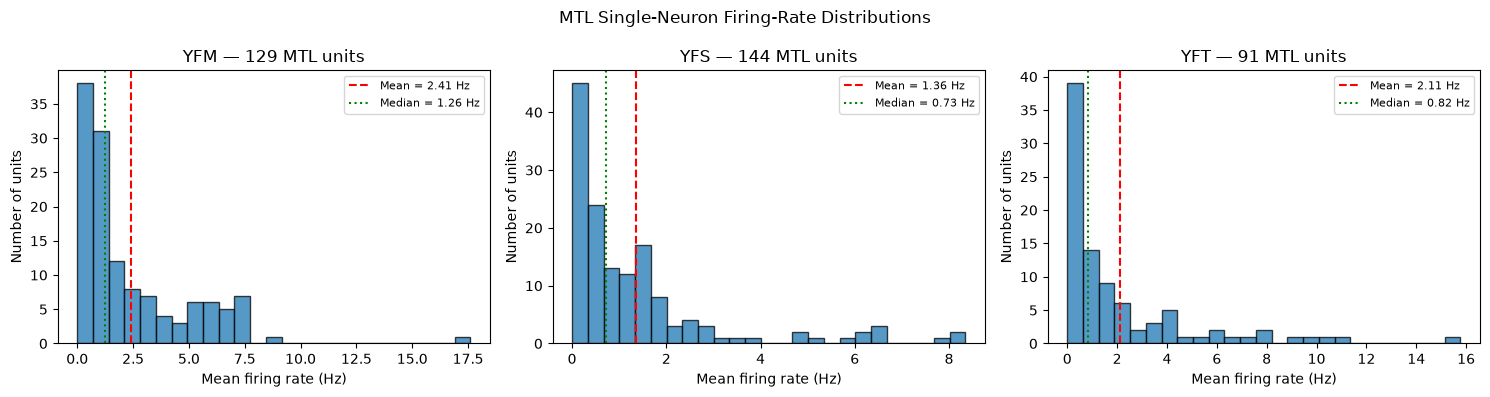

In [85]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, subject in zip(axes, subjects):

    summary = single_neuron_summary[subject]
    rates = summary["mean_firing_rate_hz"]

    ax.hist(
        rates,
        bins=25,
        edgecolor="black",
        alpha=0.75
    )

    ax.axvline(
        rates.mean(),
        color="red",
        linestyle="--",
        label=f"Mean = {rates.mean():.2f} Hz"
    )

    ax.axvline(
        rates.median(),
        color="green",
        linestyle=":",
        label=f"Median = {rates.median():.2f} Hz"
    )

    ax.set_title(f"{subject} — {len(rates)} MTL units")
    ax.set_xlabel("Mean firing rate (Hz)")
    ax.set_ylabel("Number of units")
    ax.legend(fontsize=8)

plt.suptitle("MTL Single-Neuron Firing-Rate Distributions")
plt.tight_layout()
plt.show()

In [86]:
number_tuning = {}

for subject in subjects:

    df = pd.read_csv(
        TABLES / f"{subject}_arithmetic_MTL_all_units.csv"
    )

    unit_cols = [c for c in df.columns if c.startswith("unit_")]

    # Firing rates in Hz
    rates = df[unit_cols].div(0.9)

    # Mean firing rate for each number and neuron
    tuning = rates.groupby(df["number"]).mean()
    tuning = tuning.reindex(range(1, 10))

    number_tuning[subject] = tuning

    print(f"\n{'='*45}")
    print("SUBJECT:", subject)
    print("Tuning matrix shape:", tuning.shape)
    print("Missing values:", tuning.isna().sum().sum())

    display(tuning.iloc[:, :5].round(2))


SUBJECT: YFM
Tuning matrix shape: (9, 129)
Missing values: 0


,unit_1,unit_2,unit_3,unit_4,unit_5
number,,,,,
1,2.51,0.18,0.94,0.00,1.17
2,2.68,0.13,0.92,0.00,1.18
3,3.02,0.16,0.71,0.08,1.11
4,2.78,0.83,0.28,0.00,1.67
5,2.86,0.24,0.48,0.00,0.56
6,3.12,0.49,3.26,0.00,0.90
7,3.78,0.11,0.33,0.00,0.44
8,2.13,0.09,0.83,0.00,0.28
9,2.64,0.42,0.42,0.00,0.83



SUBJECT: YFS
Tuning matrix shape: (9, 144)
Missing values: 0


,unit_67,unit_68,unit_69,unit_70,unit_71
number,,,,,
1,1.74,1.35,2.19,1.84,3.54
2,1.92,1.11,1.78,2.22,2.66
3,1.11,1.39,2.08,2.31,3.75
4,1.62,1.31,2.05,1.95,2.73
5,1.74,1.56,2.57,2.15,2.60
6,1.53,0.93,1.30,1.99,3.94
7,1.69,1.36,2.59,2.63,2.39
8,1.30,1.44,2.04,2.15,3.00
9,1.07,0.96,0.77,2.11,2.26



SUBJECT: YFT
Tuning matrix shape: (9, 91)
Missing values: 0


,unit_17,unit_18,unit_19,unit_20,unit_21
number,,,,,
1,0.25,0.04,0.43,1.09,1.18
2,0.39,0.02,0.56,1.37,1.25
3,0.24,0.06,0.30,1.05,1.15
4,0.45,0.04,0.68,1.21,1.35
5,0.34,0.00,0.38,1.47,1.13
6,0.28,0.08,0.30,1.23,1.13
7,0.41,0.03,0.57,1.27,1.32
8,0.22,0.11,0.40,0.96,1.36
9,0.22,0.00,0.38,1.15,1.41


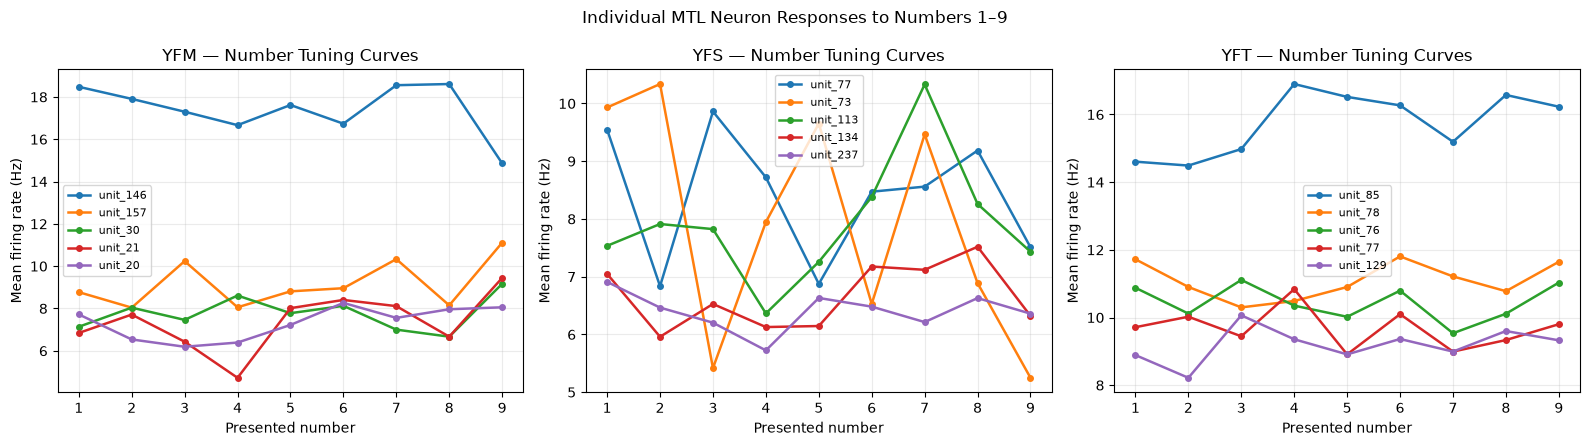

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    tuning = number_tuning[subject]
    summary = single_neuron_summary[subject]

    # Select five neurons with highest overall firing rates
    selected_units = (
        summary.nlargest(5, "mean_firing_rate_hz")["unit"]
        .tolist()
    )

    for unit in selected_units:
        ax.plot(
            tuning.index,
            tuning[unit],
            marker="o",
            linewidth=1.8,
            markersize=4,
            label=unit
        )

    ax.set_title(f"{subject} — Number Tuning Curves")
    ax.set_xlabel("Presented number")
    ax.set_ylabel("Mean firing rate (Hz)")
    ax.set_xticks(range(1, 10))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

plt.suptitle("Individual MTL Neuron Responses to Numbers 1–9")
plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_number_tuning_top5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_number_tuning_top5.pdf",
    bbox_inches="tight"
)

plt.show()

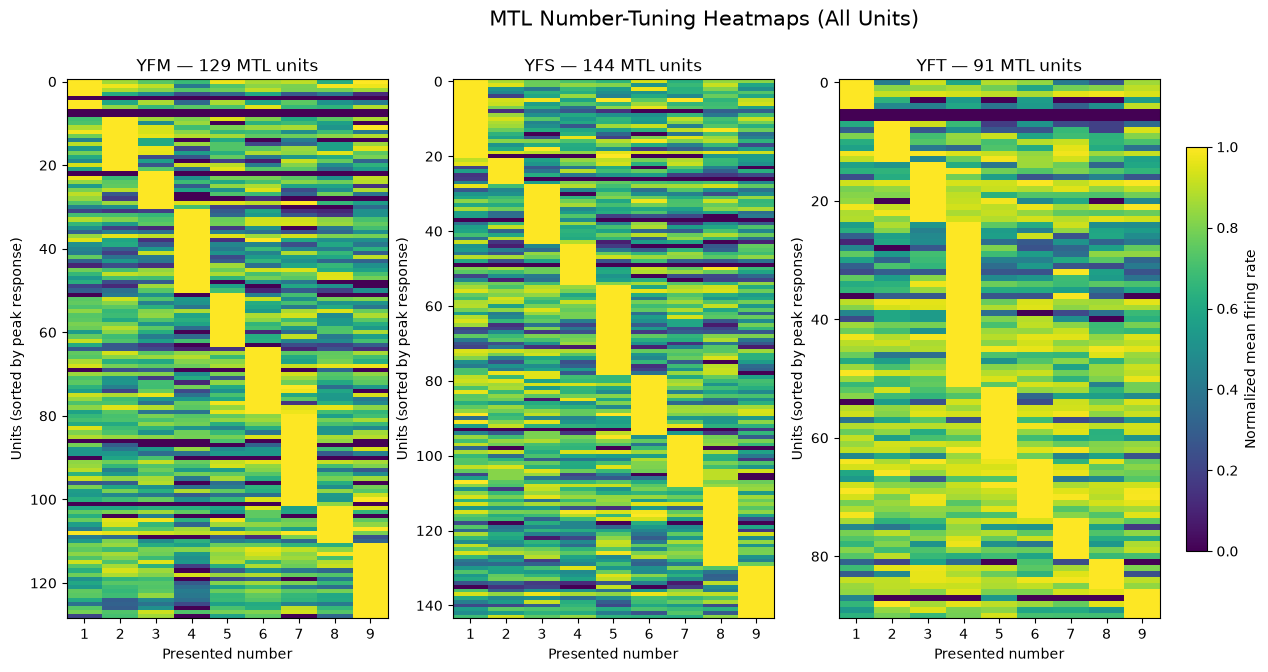

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(17, 7))

for ax, subject in zip(axes, subjects):

    tuning = number_tuning[subject]

    # Rows = neurons, columns = numbers
    matrix = tuning.to_numpy().T

    # Normalize each neuron's tuning curve by its maximum
    max_rates = matrix.max(axis=1, keepdims=True)

    normalized = np.divide(
        matrix,
        max_rates,
        out=np.zeros_like(matrix),
        where=max_rates > 0
    )

    # Sort neurons by their estimated preferred number
    preferred_number = np.argmax(normalized, axis=1)
    order = np.argsort(preferred_number, kind="stable")

    normalized = normalized[order]

    im = ax.imshow(
        normalized,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"{subject} — {matrix.shape[0]} MTL units")
    ax.set_xlabel("Presented number")
    ax.set_ylabel("Units (sorted by peak response)")
    ax.set_xticks(range(9))
    ax.set_xticklabels(range(1, 10))

fig.colorbar(
    im,
    ax=axes,
    label="Normalized mean firing rate",
    shrink=0.75,
    pad=0.02
)

fig.suptitle(
    "MTL Number-Tuning Heatmaps (All Units)",
    fontsize=15
)

plt.savefig(
    FIGURES / "arithmetic_number_tuning_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_number_tuning_heatmaps.pdf",
    bbox_inches="tight"
)

plt.show()


YFM
Valid neuron-number pairs: 1052
Mean Fano: 1.514
Median Fano: 1.201
Undefined Fano values: 109

YFS
Valid neuron-number pairs: 1233
Mean Fano: 1.892
Median Fano: 1.438
Undefined Fano values: 63

YFT
Valid neuron-number pairs: 781
Mean Fano: 1.382
Median Fano: 1.075
Undefined Fano values: 38


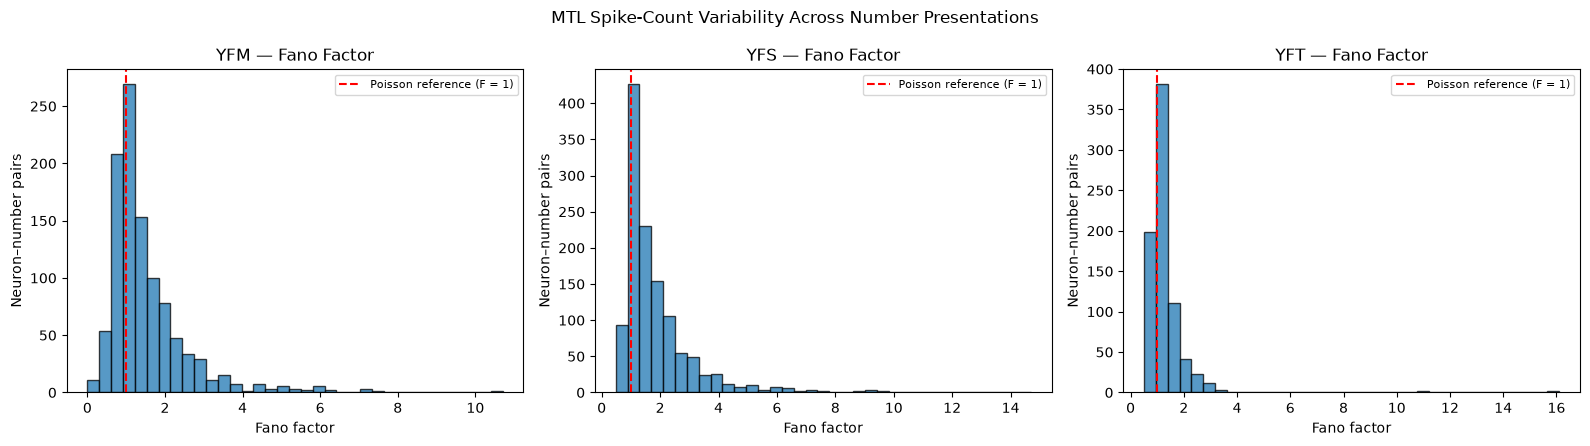

In [89]:
fano_results = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    df = pd.read_csv(
        TABLES / f"{subject}_arithmetic_MTL_all_units.csv"
    )

    unit_cols = [
        c for c in df.columns
        if c.startswith("unit_")
    ]

    fano_rows = []

    for number in range(1, 10):

        X = df.loc[
            df["number"] == number,
            unit_cols
        ].to_numpy(dtype=float)

        mean_counts = X.mean(axis=0)
        var_counts = X.var(axis=0, ddof=1)

        fano = np.divide(
            var_counts,
            mean_counts,
            out=np.full_like(mean_counts, np.nan),
            where=mean_counts > 0
        )

        for unit, value in zip(unit_cols, fano):
            fano_rows.append({
                "number": number,
                "unit": unit,
                "fano": value,
                "n_presentations": len(X)
            })

    result = pd.DataFrame(fano_rows)
    fano_results[subject] = result

    valid_fano = result["fano"].dropna()

    ax.hist(
        valid_fano,
        bins=35,
        edgecolor="black",
        alpha=0.75
    )

    ax.axvline(
        1,
        color="red",
        linestyle="--",
        label="Poisson reference (F = 1)"
    )

    ax.set_title(f"{subject} — Fano Factor")
    ax.set_xlabel("Fano factor")
    ax.set_ylabel("Neuron–number pairs")
    ax.legend(fontsize=8)

    print(f"\n{subject}")
    print("Valid neuron-number pairs:", len(valid_fano))
    print("Mean Fano:", round(valid_fano.mean(), 3))
    print("Median Fano:", round(valid_fano.median(), 3))
    print("Undefined Fano values:", result["fano"].isna().sum())

plt.suptitle("MTL Spike-Count Variability Across Number Presentations")
plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_fano_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_fano_distributions.pdf",
    bbox_inches="tight"
)

plt.show()

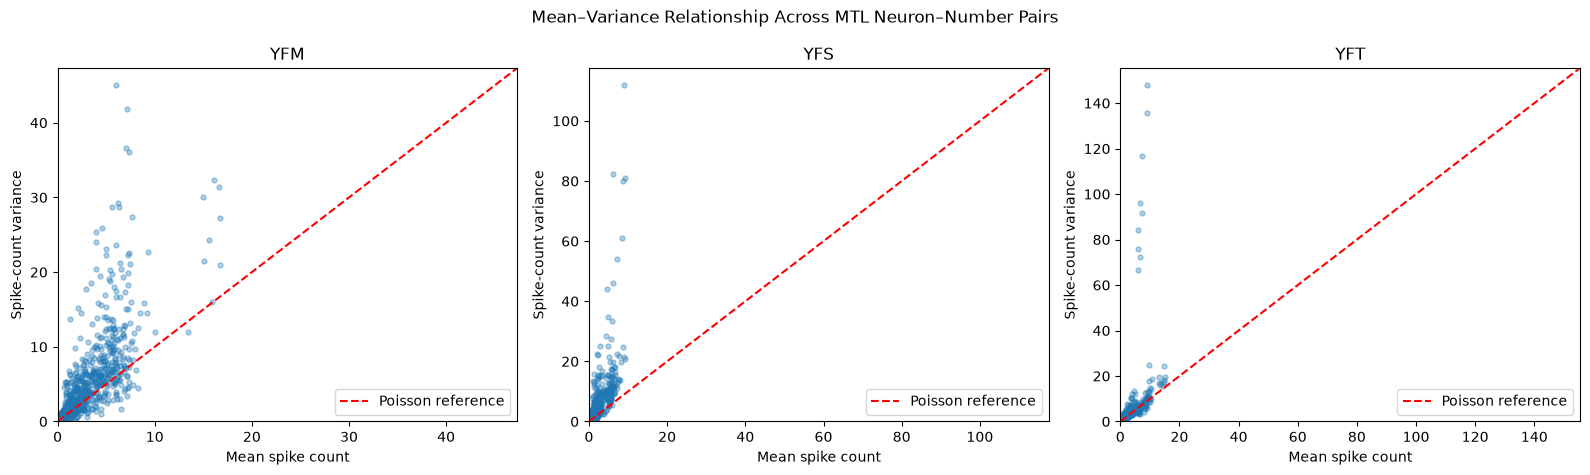

In [90]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, subject in zip(axes, subjects):

    df = pd.read_csv(
        TABLES / f"{subject}_arithmetic_MTL_all_units.csv"
    )

    unit_cols = [c for c in df.columns if c.startswith("unit_")]
    records = []

    for number in range(1, 10):
        X = df.loc[df["number"] == number, unit_cols].to_numpy(float)

        means = X.mean(axis=0)
        variances = X.var(axis=0, ddof=1)

        for unit, mean, variance in zip(unit_cols, means, variances):
            records.append({
                "number": number,
                "unit": unit,
                "mean_count": mean,
                "variance": variance,
                "n_presentations": len(X)
            })

    stats = pd.DataFrame(records)
    stats.to_csv(
        TABLES / f"{subject}_arithmetic_mean_variance.csv",
        index=False
    )

    ax.scatter(
        stats["mean_count"],
        stats["variance"],
        alpha=0.35,
        s=13
    )

    limit = max(stats["mean_count"].max(), stats["variance"].max()) * 1.05

    ax.plot(
        [0, limit], [0, limit],
        "r--", linewidth=1.5,
        label="Poisson reference"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_title(subject)
    ax.set_xlabel("Mean spike count")
    ax.set_ylabel("Spike-count variance")
    ax.legend()

plt.suptitle("Mean–Variance Relationship Across MTL Neuron–Number Pairs")
plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_mean_variance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES / "arithmetic_mean_variance.pdf",
    bbox_inches="tight"
)

plt.show()


YFM
Valid units: 126
Mean η²: 0.0648
Median η²: 0.0603
Maximum η²: 0.1379
Undefined η²: 3

YFS
Valid units: 144
Mean η²: 0.0286
Median η²: 0.0269
Maximum η²: 0.0855
Undefined η²: 0

YFT
Valid units: 89
Mean η²: 0.0182
Median η²: 0.0163
Maximum η²: 0.0549
Undefined η²: 2


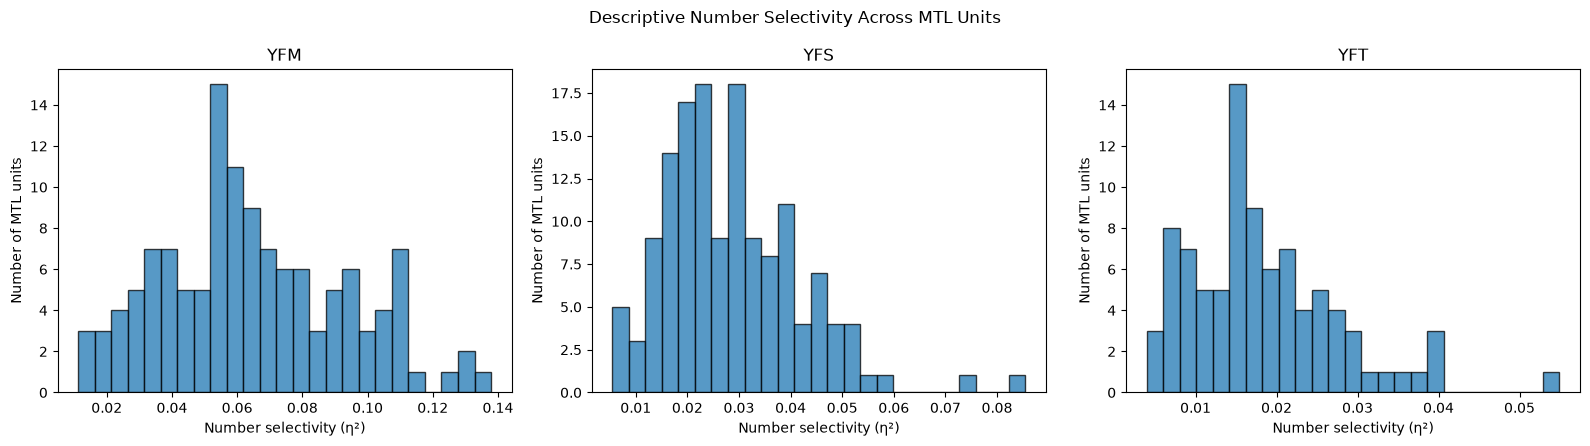

In [91]:
number_selectivity = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    df = pd.read_csv(
        TABLES / f"{subject}_arithmetic_MTL_all_units.csv"
    )

    unit_cols = [c for c in df.columns if c.startswith("unit_")]

    X = df[unit_cols].to_numpy(dtype=float)
    y = df["number"].to_numpy()

    grand_mean = X.mean(axis=0)

    ss_total = ((X - grand_mean) ** 2).sum(axis=0)

    ss_between = np.zeros(len(unit_cols))

    for number in range(1, 10):
        group = X[y == number]

        group_mean = group.mean(axis=0)

        ss_between += len(group) * (
            group_mean - grand_mean
        ) ** 2

    eta_squared = np.divide(
        ss_between,
        ss_total,
        out=np.full(len(unit_cols), np.nan),
        where=ss_total > 0
    )

    result = pd.DataFrame({
        "unit": unit_cols,
        "eta_squared": eta_squared
    })

    number_selectivity[subject] = result

    result.to_csv(
        TABLES / f"{subject}_arithmetic_number_selectivity_eta2.csv",
        index=False
    )

    valid = result["eta_squared"].dropna()

    ax.hist(
        valid,
        bins=25,
        edgecolor="black",
        alpha=0.75
    )

    ax.set_title(subject)
    ax.set_xlabel("Number selectivity (η²)")
    ax.set_ylabel("Number of MTL units")

    print(f"\n{subject}")
    print("Valid units:", len(valid))
    print("Mean η²:", round(valid.mean(), 4))
    print("Median η²:", round(valid.median(), 4))
    print("Maximum η²:", round(valid.max(), 4))
    print("Undefined η²:", result["eta_squared"].isna().sum())

plt.suptitle("Descriptive Number Selectivity Across MTL Units")
plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_number_selectivity_eta2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_number_selectivity_eta2.pdf",
    bbox_inches="tight"
)

plt.show()


YFM
Mean adjusted selectivity: -0.0065
Median adjusted selectivity: -0.0113
Units with positive ε²: 47
Undefined: 3

YFS
Mean adjusted selectivity: -0.0019
Median adjusted selectivity: -0.0037
Units with positive ε²: 54
Undefined: 0

YFT
Mean adjusted selectivity: 0.0015
Median adjusted selectivity: -0.0005
Units with positive ε²: 43
Undefined: 2


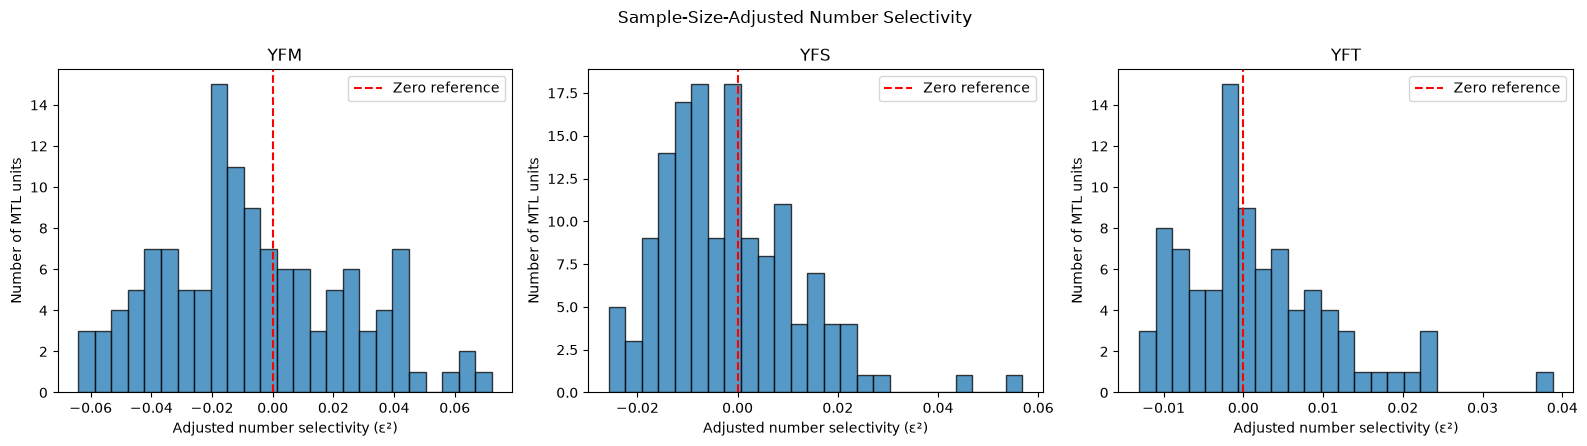

In [92]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

adjusted_selectivity = {}

for ax, subject in zip(axes, subjects):

    df = pd.read_csv(
        TABLES / f"{subject}_arithmetic_MTL_all_units.csv"
    )

    unit_cols = [c for c in df.columns if c.startswith("unit_")]

    X = df[unit_cols].to_numpy(dtype=float)
    y = df["number"].to_numpy()

    N = len(y)
    k = len(np.unique(y))

    grand_mean = X.mean(axis=0)

    ss_total = ((X - grand_mean) ** 2).sum(axis=0)

    ss_between = np.zeros(len(unit_cols))

    for number in np.unique(y):
        group = X[y == number]
        ss_between += len(group) * (
            group.mean(axis=0) - grand_mean
        ) ** 2

    ss_within = ss_total - ss_between
    ms_within = ss_within / (N - k)

    epsilon_squared = np.divide(
        ss_between - (k - 1) * ms_within,
        ss_total,
        out=np.full(len(unit_cols), np.nan),
        where=ss_total > 0
    )

    result = pd.DataFrame({
        "unit": unit_cols,
        "epsilon_squared": epsilon_squared
    })

    adjusted_selectivity[subject] = result

    result.to_csv(
        TABLES / f"{subject}_arithmetic_number_selectivity_adjusted.csv",
        index=False
    )

    valid = result["epsilon_squared"].dropna()

    ax.hist(valid, bins=25, edgecolor="black", alpha=0.75)
    ax.axvline(0, color="red", linestyle="--", label="Zero reference")

    ax.set_title(subject)
    ax.set_xlabel("Adjusted number selectivity (ε²)")
    ax.set_ylabel("Number of MTL units")
    ax.legend()

    print(f"\n{subject}")
    print("Mean adjusted selectivity:", round(valid.mean(), 4))
    print("Median adjusted selectivity:", round(valid.median(), 4))
    print("Units with positive ε²:", int((valid > 0).sum()))
    print("Undefined:", result["epsilon_squared"].isna().sum())

plt.suptitle("Sample-Size-Adjusted Number Selectivity")
plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_number_selectivity_adjusted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES / "arithmetic_number_selectivity_adjusted.pdf",
    bbox_inches="tight"
)

plt.show()

In [93]:
for subject in subjects:

    df = pd.read_csv(
        TABLES / f"{subject}_arithmetic_MTL_all_units.csv"
    )

    print(f"\n{'='*50}")
    print("SUBJECT:", subject)

    print("Available metadata columns:")
    print([
        c for c in df.columns
        if not c.startswith("unit_")
    ])

    print("\nPresentations:", len(df))
    print("Unique trials:", df["trial"].nunique())

    print("\nOperand distribution:")
    print(df["operand"].value_counts().sort_index())

    print("\nPresentations per trial:")
    print(
        df.groupby("trial").size()
        .value_counts()
        .sort_index()
    )

    print("\nNumber × operand position:")
    display(
        pd.crosstab(
            df["number"],
            df["operand"]
        )
    )


SUBJECT: YFM
Available metadata columns:
['trial', 'number', 'onset', 'operand']

Presentations: 114
Unique trials: 78

Operand distribution:
operand
1    58
2    56
Name: count, dtype: int64

Presentations per trial:
1    42
2    36
Name: count, dtype: int64

Number × operand position:


operand,1,2
number,,
1,11,8
2,10,7
3,8,6
4,3,1
5,4,10
6,8,8
7,4,6
8,8,4
9,2,6



SUBJECT: YFS
Available metadata columns:
['trial', 'number', 'onset', 'operand']

Presentations: 264
Unique trials: 156

Operand distribution:
operand
1    127
2    137
Name: count, dtype: int64

Presentations per trial:
1     48
2    108
Name: count, dtype: int64

Number × operand position:


operand,1,2
number,,
1,18,14
2,14,19
3,8,16
4,16,17
5,13,19
6,11,13
7,17,10
8,15,15
9,15,14



SUBJECT: YFT
Available metadata columns:
['trial', 'number', 'onset', 'operand']

Presentations: 477
Unique trials: 290

Operand distribution:
operand
1    240
2    237
Name: count, dtype: int64

Presentations per trial:
1    103
2    187
Name: count, dtype: int64

Number × operand position:


operand,1,2
number,,
1,34,28
2,24,24
3,23,29
4,25,32
5,33,20
6,29,27
7,22,21
8,21,29
9,29,27


# 1. Raw population representation


YFM
Centroid matrix shape: (9, 129)
Mean centroid firing rate: 2.391 Hz

YFS
Centroid matrix shape: (9, 144)
Mean centroid firing rate: 1.357 Hz

YFT
Centroid matrix shape: (9, 91)
Mean centroid firing rate: 2.109 Hz


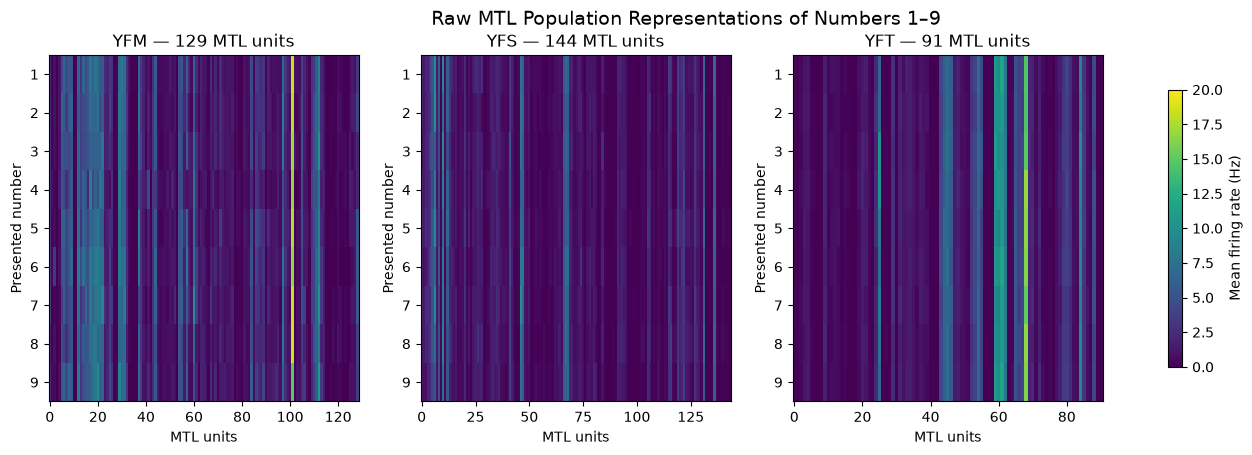

In [94]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

population_centroids = {}

for ax, subject in zip(axes, subjects):

    centroids = number_tuning[subject].copy()
    population_centroids[subject] = centroids

    # Rows = numbers, columns = neurons
    matrix = centroids.to_numpy()

    im = ax.imshow(
        matrix,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis",
        vmin=0,
        vmax=20
    )

    ax.set_title(f"{subject} — {matrix.shape[1]} MTL units")
    ax.set_xlabel("MTL units")
    ax.set_ylabel("Presented number")
    ax.set_yticks(range(9))
    ax.set_yticklabels(range(1, 10))

    print(f"\n{subject}")
    print("Centroid matrix shape:", matrix.shape)
    print("Mean centroid firing rate:", round(matrix.mean(), 3), "Hz")

fig.colorbar(
    im,
    ax=axes,
    label="Mean firing rate (Hz)",
    shrink=0.8
)

fig.suptitle(
    "Raw MTL Population Representations of Numbers 1–9",
    fontsize=14
)

plt.savefig(
    FIGURES / "arithmetic_raw_population_centroids.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_raw_population_centroids.pdf",
    bbox_inches="tight"
)

plt.show()


YFM
Mean pairwise distance: 9.806
Minimum distance: 6.71
Maximum distance: 15.154

YFS
Mean pairwise distance: 6.011
Minimum distance: 4.193
Maximum distance: 7.805

YFT
Mean pairwise distance: 3.746
Minimum distance: 2.342
Maximum distance: 5.068


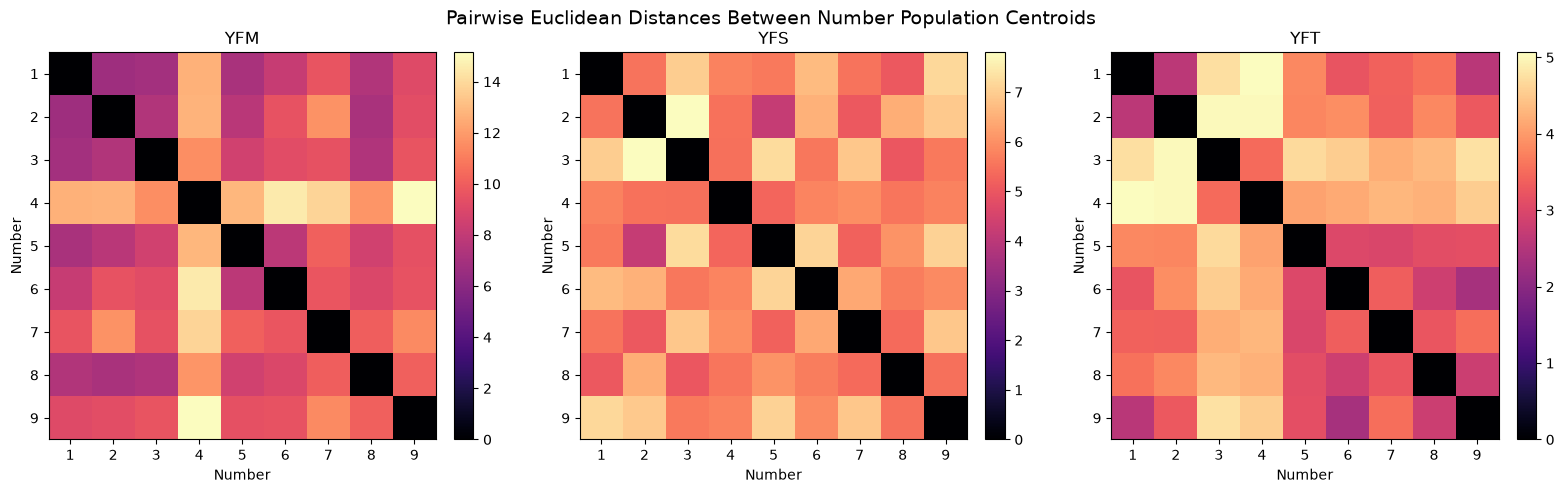

In [95]:
from scipy.spatial.distance import pdist, squareform

population_distances = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, subject in zip(axes, subjects):

    centroids = population_centroids[subject].to_numpy()

    # Euclidean distances between the nine population vectors
    distances = squareform(
        pdist(centroids, metric="euclidean")
    )

    population_distances[subject] = distances

    # Save numerical results
    pd.DataFrame(
        distances,
        index=range(1, 10),
        columns=range(1, 10)
    ).to_csv(
        TABLES / f"{subject}_arithmetic_population_distances.csv"
    )

    im = ax.imshow(
        distances,
        cmap="magma",
        vmin=0
    )

    ax.set_title(subject)
    ax.set_xlabel("Number")
    ax.set_ylabel("Number")
    ax.set_xticks(range(9))
    ax.set_xticklabels(range(1, 10))
    ax.set_yticks(range(9))
    ax.set_yticklabels(range(1, 10))

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    upper = distances[np.triu_indices(9, k=1)]

    print(f"\n{subject}")
    print("Mean pairwise distance:", round(upper.mean(), 3))
    print("Minimum distance:", round(upper.min(), 3))
    print("Maximum distance:", round(upper.max(), 3))

fig.suptitle(
    "Pairwise Euclidean Distances Between Number Population Centroids",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_population_distances.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_population_distances.pdf",
    bbox_inches="tight"
)

plt.show()

YFM Mean split-half r: 0.789 Median: 0.792
YFS Mean split-half r: -0.082 Median: -0.098
YFT Mean split-half r: -0.034 Median: -0.045


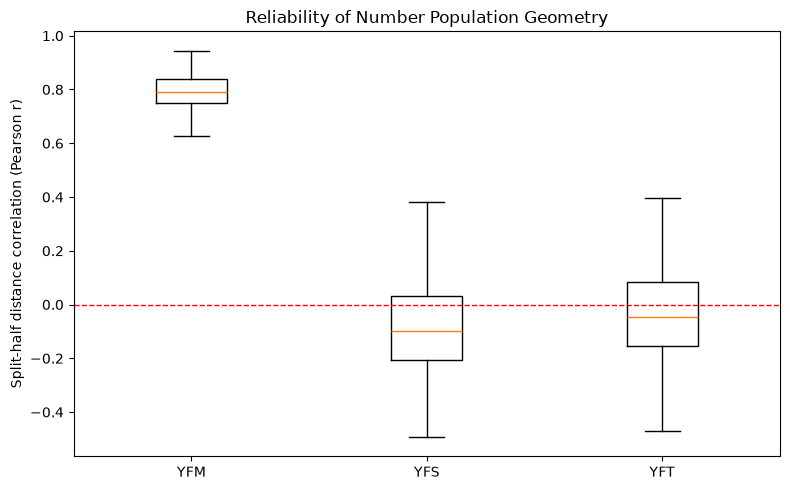

In [96]:
from scipy.stats import pearsonr
from scipy.spatial.distance import pdist

rng = np.random.default_rng(42)
n_repeats = 500

split_half_results = {}

for subject in subjects:

    X = arithmetic_mtl_counts[subject] / 0.9
    y = arithmetic_presentations[subject]["number"].to_numpy()

    correlations = []

    for repeat in range(n_repeats):

        means_a = []
        means_b = []

        for number in range(1, 10):

            idx = np.where(y == number)[0]
            idx = rng.permutation(idx)

            half = len(idx) // 2

            means_a.append(X[idx[:half]].mean(axis=0))
            means_b.append(X[idx[half:]].mean(axis=0))

        means_a = np.vstack(means_a)
        means_b = np.vstack(means_b)

        dist_a = pdist(means_a, metric="euclidean")
        dist_b = pdist(means_b, metric="euclidean")

        if np.std(dist_a) > 0 and np.std(dist_b) > 0:
            r = pearsonr(dist_a, dist_b).statistic
            correlations.append(r)

    split_half_results[subject] = np.array(correlations)

    print(
        subject,
        "Mean split-half r:",
        round(np.mean(correlations), 3),
        "Median:",
        round(np.median(correlations), 3)
    )

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [split_half_results[s] for s in subjects],
    tick_labels=list(subjects),
    showfliers=False
)

ax.axhline(0, color="red", linestyle="--", linewidth=1)

ax.set_ylabel("Split-half distance correlation (Pearson r)")
ax.set_title("Reliability of Number Population Geometry")

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_population_split_half_reliability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_population_split_half_reliability.pdf",
    bbox_inches="tight"
)

plt.show()


YFM
Explained variance (%): [34.02 19.27 12.42]
Cumulative first 3 PCs (%): 65.71

YFS
Explained variance (%): [34.11 15.52 12.89]
Cumulative first 3 PCs (%): 62.52

YFT
Explained variance (%): [37.78 18.28 13.1 ]
Cumulative first 3 PCs (%): 69.15


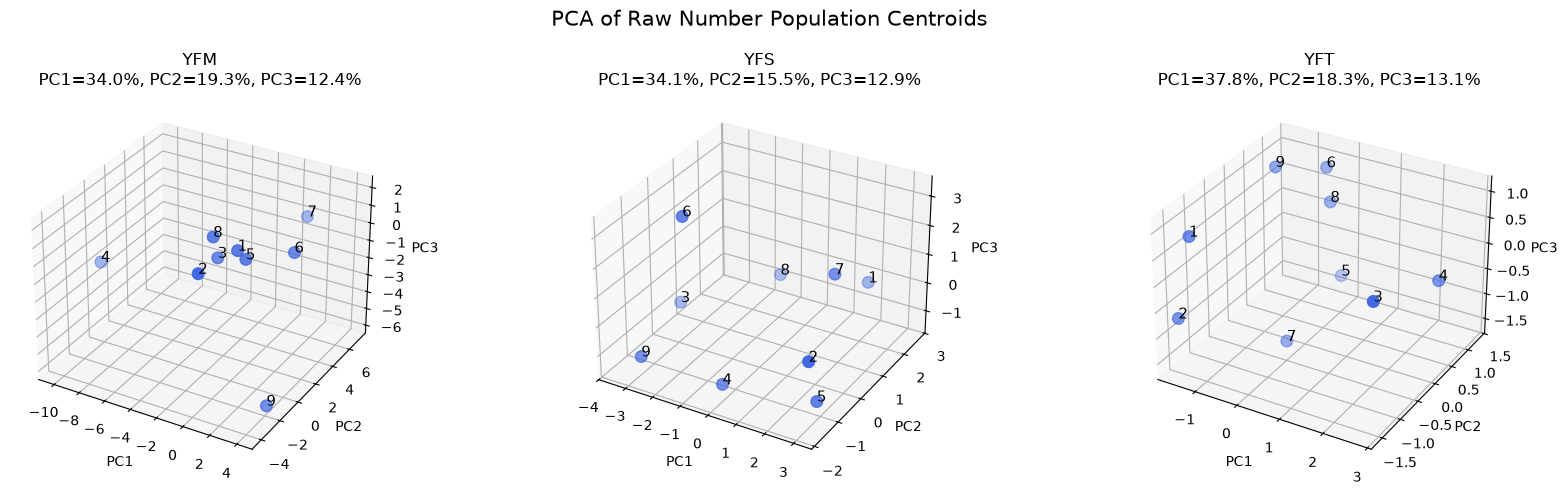

In [97]:
from sklearn.decomposition import PCA

population_pca = {}

fig = plt.figure(figsize=(17, 5))

for i, subject in enumerate(subjects):

    M = population_centroids[subject].to_numpy()

    pca = PCA(n_components=3)
    Z = pca.fit_transform(M)

    population_pca[subject] = {
        "model": pca,
        "coordinates": Z,
        "explained_variance_ratio": pca.explained_variance_ratio_
    }

    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    ax.scatter(
        Z[:, 0],
        Z[:, 1],
        Z[:, 2],
        s=70,
        color="royalblue"
    )

    for number, point in enumerate(Z, start=1):
        ax.text(
            point[0],
            point[1],
            point[2],
            str(number),
            fontsize=11
        )

    variance = pca.explained_variance_ratio_ * 100

    ax.set_title(
        f"{subject}\n"
        f"PC1={variance[0]:.1f}%, "
        f"PC2={variance[1]:.1f}%, "
        f"PC3={variance[2]:.1f}%"
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")

    pd.DataFrame(
        Z,
        index=range(1, 10),
        columns=["PC1", "PC2", "PC3"]
    ).to_csv(
        TABLES / f"{subject}_arithmetic_population_PCA.csv"
    )

    print(f"\n{subject}")
    print("Explained variance (%):", np.round(variance, 2))
    print("Cumulative first 3 PCs (%):", round(variance.sum(), 2))

fig.suptitle(
    "PCA of Raw Number Population Centroids",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_population_PCA_3D.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_population_PCA_3D.pdf",
    bbox_inches="tight"
)

plt.show()


YFM
Eigenvalues: [17.174  9.727  6.272  5.609  3.954  3.221  2.466  2.057]
Participation ratio: 5.13

YFS
Eigenvalues: [6.271 2.853 2.37  2.099 1.871 1.235 0.92  0.764]
Participation ratio: 5.285

YFT
Eigenvalues: [2.756 1.333 0.956 0.783 0.525 0.428 0.285 0.23 ]
Participation ratio: 4.631


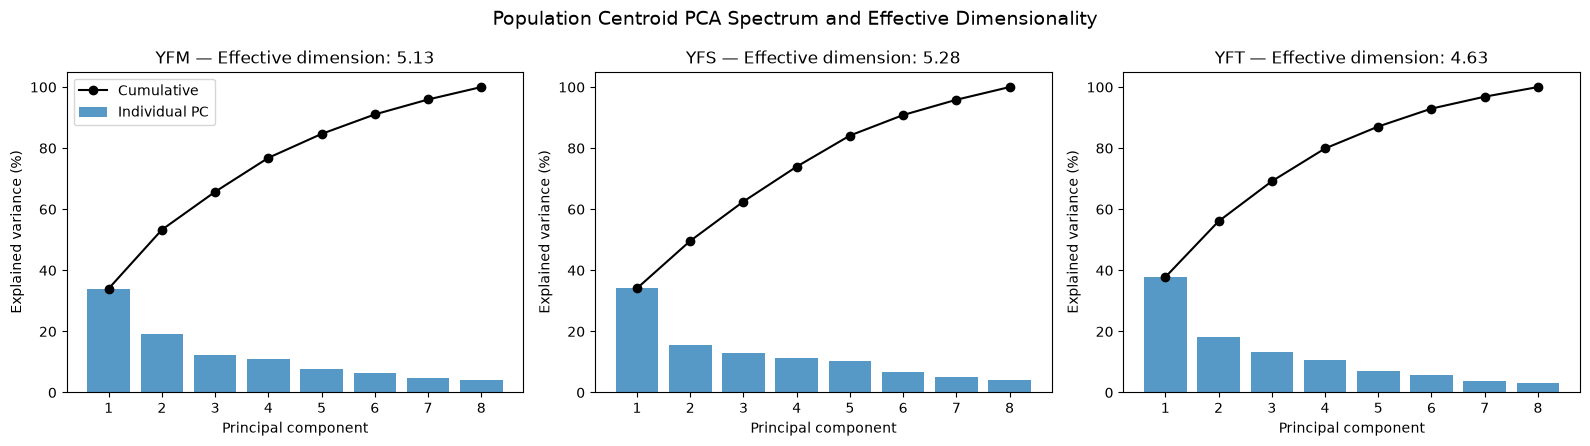

In [98]:
from sklearn.decomposition import PCA

pca_spectrum = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    M = population_centroids[subject].to_numpy()

    pca = PCA(n_components=8)
    pca.fit(M)

    eigenvalues = pca.explained_variance_
    explained = pca.explained_variance_ratio_
    cumulative = np.cumsum(explained)

    participation_ratio = (
        eigenvalues.sum() ** 2
        / np.sum(eigenvalues ** 2)
    )

    pca_spectrum[subject] = {
        "eigenvalues": eigenvalues,
        "explained_variance_ratio": explained,
        "participation_ratio": participation_ratio
    }

    pd.DataFrame({
        "PC": np.arange(1, 9),
        "eigenvalue": eigenvalues,
        "explained_variance_ratio": explained,
        "cumulative_variance": cumulative
    }).to_csv(
        TABLES / f"{subject}_arithmetic_PCA_spectrum.csv",
        index=False
    )

    ax.bar(
        np.arange(1, 9),
        explained * 100,
        alpha=0.75,
        label="Individual PC"
    )

    ax.plot(
        np.arange(1, 9),
        cumulative * 100,
        marker="o",
        color="black",
        label="Cumulative"
    )

    ax.set_title(
        f"{subject} — Effective dimension: "
        f"{participation_ratio:.2f}"
    )

    ax.set_xlabel("Principal component")
    ax.set_ylabel("Explained variance (%)")
    ax.set_xticks(np.arange(1, 9))
    ax.set_ylim(0, 105)

    print(f"\n{subject}")
    print("Eigenvalues:", np.round(eigenvalues, 3))
    print("Participation ratio:", round(participation_ratio, 3))

axes[0].legend()

fig.suptitle(
    "Population Centroid PCA Spectrum and Effective Dimensionality",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_population_PCA_spectrum.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_population_PCA_spectrum.pdf",
    bbox_inches="tight"
)

plt.show()

In [99]:
from numpy.linalg import svd, matrix_rank

affine_rank_results = {}

for subject in subjects:

    M = population_centroids[subject].to_numpy()

    # Center the nine number centroids
    M_centered = M - M.mean(axis=0, keepdims=True)

    singular_values = svd(
        M_centered,
        compute_uv=False
    )

    rank = matrix_rank(M_centered)

    affine_rank_results[subject] = {
        "singular_values": singular_values,
        "affine_rank": rank
    }

    print(f"\n{subject}")
    print("Centered matrix shape:", M_centered.shape)
    print("Affine rank:", rank)
    print("Singular values:", np.round(singular_values, 4))

    pd.DataFrame({
        "component": np.arange(1, len(singular_values) + 1),
        "singular_value": singular_values
    }).to_csv(
        TABLES / f"{subject}_arithmetic_affine_rank.csv",
        index=False
    )


YFM
Centered matrix shape: (9, 129)
Affine rank: 8
Singular values: [11.7214  8.8213  7.0833  6.6985  5.624   5.0761  4.4416  4.057   0.    ]

YFS
Centered matrix shape: (9, 144)
Affine rank: 8
Singular values: [7.083  4.7778 4.354  4.0983 3.8686 3.1435 2.7127 2.4724 0.    ]

YFT
Centered matrix shape: (9, 91)
Affine rank: 8
Singular values: [4.6954 3.266  2.7652 2.5031 2.0484 1.8501 1.5089 1.3569 0.    ]


Poisson noise baseline

In [100]:
# Poisson noise baseline

xample: Three neurons and three numbers
Neuron	Number 1	Number 2	Number 3
Neuron A	\(\lambda=2\)	\(\lambda=2\)	\(\lambda=2\)
Neuron B	\(\lambda=5\)	\(\lambda=5\)	\(\lambda=5\)
Neuron C	\(\lambda=10\)	\(\lambda=10\)	\(\lambda=10\)

We are choosing different \(\lambda\) values for different neurons, but keeping the same \(\lambda\) for a given neuron across all nine numbers.


YFM
Observed PR: 5.13
Null mean PR: 5.56
Null 95% interval: [4.542 6.434]

YFS
Observed PR: 5.285
Null mean PR: 6.844
Null 95% interval: [6.29  7.274]

YFT
Observed PR: 4.631
Null mean PR: 6.251
Null 95% interval: [5.492 6.873]


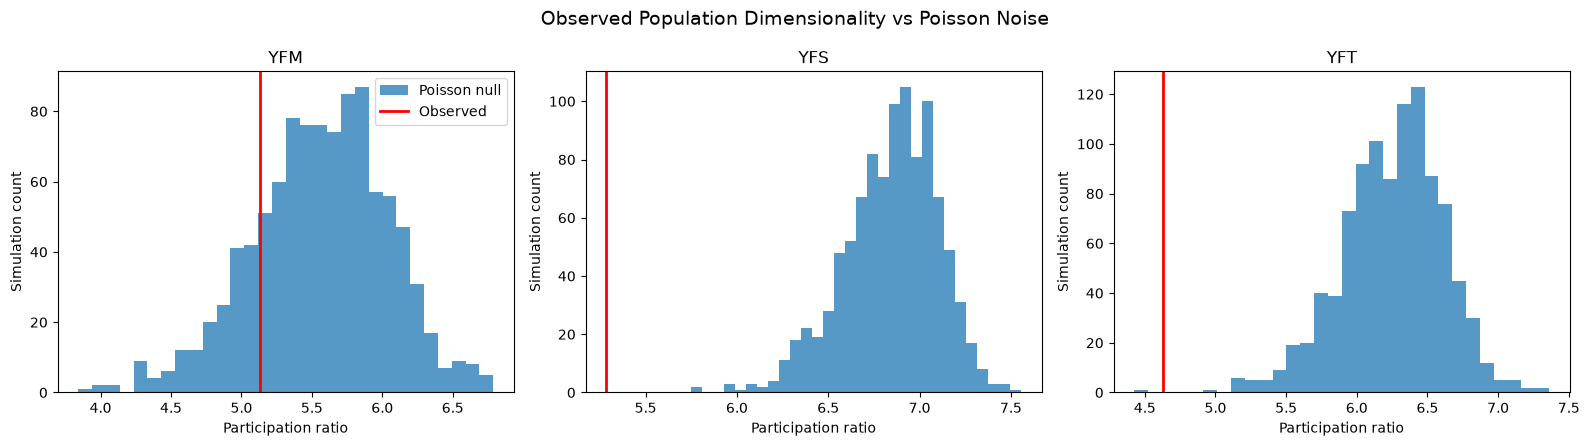

In [101]:
from sklearn.decomposition import PCA

rng = np.random.default_rng(42)
n_simulations = 1000

poisson_null_results = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    X = arithmetic_mtl_counts[subject]
    y = arithmetic_presentations[subject]["number"].to_numpy()

    # Mean spike count of each neuron, independent of number
    mean_counts = X.mean(axis=0)

    observed_pr = pca_spectrum[subject]["participation_ratio"]

    null_pr = []

    for _ in range(n_simulations):

        # Independent Poisson responses with no number tuning
        X_null = rng.poisson(
            lam=mean_counts,
            size=X.shape
        )

        # Nine synthetic number centroids
        M_null = np.vstack([
            X_null[y == number].mean(axis=0) / 0.9
            for number in range(1, 10)
        ])

        eigenvalues = PCA(n_components=8).fit(
            M_null
        ).explained_variance_

        pr = (
            eigenvalues.sum() ** 2
            / np.sum(eigenvalues ** 2)
        )

        null_pr.append(pr)

    null_pr = np.asarray(null_pr)

    poisson_null_results[subject] = null_pr

    pd.DataFrame({
        "null_participation_ratio": null_pr
    }).to_csv(
        TABLES / f"{subject}_arithmetic_poisson_null_PR.csv",
        index=False
    )

    ax.hist(
        null_pr,
        bins=30,
        alpha=0.75,
        label="Poisson null"
    )

    ax.axvline(
        observed_pr,
        color="red",
        linewidth=2,
        label="Observed"
    )

    ax.set_title(subject)
    ax.set_xlabel("Participation ratio")
    ax.set_ylabel("Simulation count")

    print(f"\n{subject}")
    print("Observed PR:", round(observed_pr, 3))
    print("Null mean PR:", round(null_pr.mean(), 3))
    print(
        "Null 95% interval:",
        np.round(np.quantile(null_pr, [0.025, 0.975]), 3)
    )

axes[0].legend()

fig.suptitle(
    "Observed Population Dimensionality vs Poisson Noise",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_population_poisson_null_PR.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_population_poisson_null_PR.pdf",
    bbox_inches="tight"
)

plt.show()

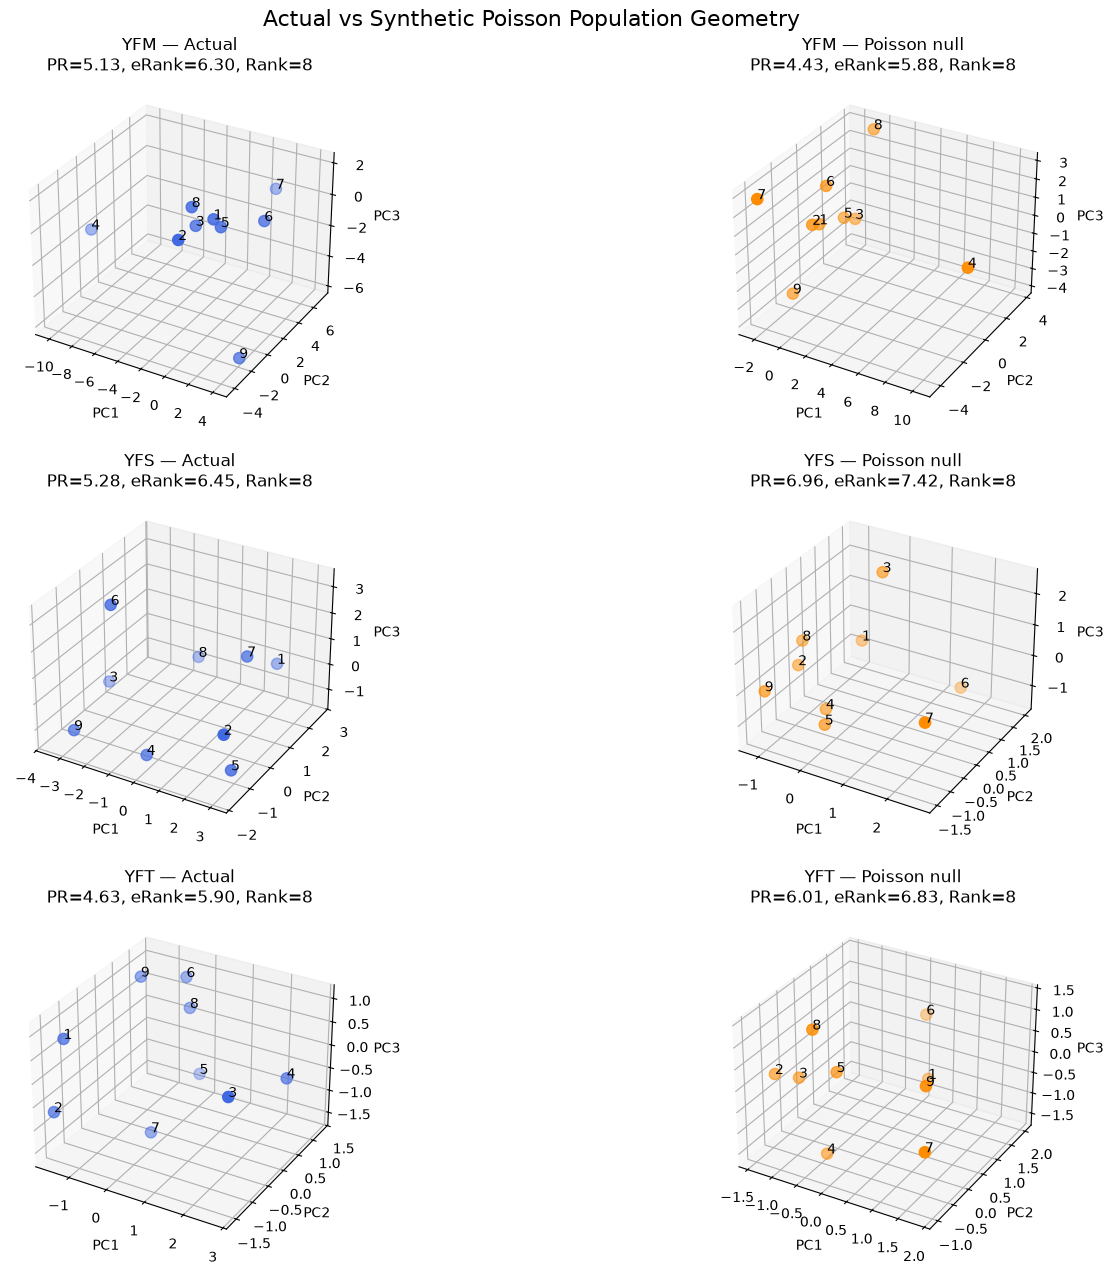

,subject,dataset,PR,effective_rank,affine_rank,mean_distance_hz,distance_CV,PC1_percent,PC2_percent,PC3_percent
0,YFM,Actual,5.130,6.299,8,9.806,0.223,34.022,19.269,12.424
1,YFM,Poisson null,4.426,5.882,8,8.319,0.292,40.718,15.149,12.229
2,YFS,Actual,5.285,6.449,8,6.011,0.133,34.112,15.522,12.890
3,YFS,Poisson null,6.956,7.418,8,4.057,0.103,20.219,17.399,16.697
4,YFT,Actual,4.631,5.903,8,3.746,0.200,37.776,18.277,13.102
5,YFT,Poisson null,6.007,6.829,8,3.015,0.121,26.382,20.719,14.394


In [102]:
from sklearn.decomposition import PCA
from scipy.spatial.distance import pdist
from numpy.linalg import matrix_rank

rng = np.random.default_rng(2026)

geometry_comparison = []
synthetic_population_centroids = {}

def geometry_metrics(M):
    """Geometric statistics for a 9 × neurons centroid matrix."""

    M = np.asarray(M, dtype=float)
    centered = M - M.mean(axis=0, keepdims=True)

    pca = PCA(n_components=8)
    Z = pca.fit_transform(M)

    eig = pca.explained_variance_
    p = eig / eig.sum()

    pr = eig.sum()**2 / np.sum(eig**2)
    erank = np.exp(-np.sum(p[p > 0] * np.log(p[p > 0])))
    rank = matrix_rank(centered)

    distances = pdist(M)
    distance_cv = distances.std() / distances.mean()

    return {
        "pca": pca,
        "Z": Z,
        "PR": pr,
        "effective_rank": erank,
        "affine_rank": rank,
        "distance_mean": distances.mean(),
        "distance_cv": distance_cv,
        "PC1": p[0],
        "PC2": p[1],
        "PC3": p[2],
    }

fig = plt.figure(figsize=(17, 13))

for row, subject in enumerate(subjects):

    X = arithmetic_mtl_counts[subject]
    y = arithmetic_presentations[subject]["number"].to_numpy()

    # Actual nine number centroids (Hz)
    M_real = population_centroids[subject].to_numpy()

    # One Poisson simulation: same neurons and presentation counts
    mean_counts = X.mean(axis=0)
    X_null = rng.poisson(mean_counts, size=X.shape)

    M_null = np.vstack([
        X_null[y == number].mean(axis=0) / 0.9
        for number in range(1, 10)
    ])

    synthetic_population_centroids[subject] = M_null

    for col, (kind, M) in enumerate([
        ("Actual", M_real),
        ("Poisson null", M_null)
    ]):

        result = geometry_metrics(M)

        geometry_comparison.append({
            "subject": subject,
            "dataset": kind,
            "PR": result["PR"],
            "effective_rank": result["effective_rank"],
            "affine_rank": result["affine_rank"],
            "mean_distance_hz": result["distance_mean"],
            "distance_CV": result["distance_cv"],
            "PC1_percent": 100 * result["PC1"],
            "PC2_percent": 100 * result["PC2"],
            "PC3_percent": 100 * result["PC3"],
        })

        Z = result["Z"]

        ax = fig.add_subplot(
            3, 2, row * 2 + col + 1,
            projection="3d"
        )

        ax.scatter(
            Z[:, 0], Z[:, 1], Z[:, 2],
            s=65,
            color="royalblue" if kind == "Actual" else "darkorange"
        )

        for number, point in enumerate(Z, start=1):
            ax.text(*point[:3], str(number), fontsize=10)

        ax.set_title(
            f"{subject} — {kind}\n"
            f"PR={result['PR']:.2f}, "
            f"eRank={result['effective_rank']:.2f}, "
            f"Rank={result['affine_rank']}"
        )

        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_zlabel("PC3")

plt.suptitle(
    "Actual vs Synthetic Poisson Population Geometry",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_actual_vs_poisson_PCA.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES / "arithmetic_actual_vs_poisson_PCA.pdf",
    bbox_inches="tight"
)

plt.show()

geometry_comparison_df = pd.DataFrame(geometry_comparison)

geometry_comparison_df.to_csv(
    TABLES / "arithmetic_actual_vs_poisson_geometry.csv",
    index=False
)

display(geometry_comparison_df.round(3))

In [103]:
rng = np.random.default_rng(2027)
n_simulations = 1000

null_geometry_rows = []
observed_geometry_rows = []

metrics = [
    "PR",
    "effective_rank",
    "affine_rank",
    "distance_mean",
    "distance_cv"
]

for subject in subjects:

    X = arithmetic_mtl_counts[subject]
    y = arithmetic_presentations[subject]["number"].to_numpy()

    M_real = population_centroids[subject].to_numpy()
    observed = geometry_metrics(M_real)

    observed_geometry_rows.append({
        "subject": subject,
        **{m: observed[m] for m in metrics}
    })

    mean_counts = X.mean(axis=0)

    for sim in range(n_simulations):

        X_null = rng.poisson(mean_counts, size=X.shape)

        M_null = np.vstack([
            X_null[y == number].mean(axis=0) / 0.9
            for number in range(1, 10)
        ])

        result = geometry_metrics(M_null)

        null_geometry_rows.append({
            "subject": subject,
            "simulation": sim + 1,
            **{m: result[m] for m in metrics}
        })

null_geometry_df = pd.DataFrame(null_geometry_rows)
observed_geometry_df = pd.DataFrame(observed_geometry_rows)

null_geometry_df.to_csv(
    TABLES / "arithmetic_poisson_null_geometry_1000.csv",
    index=False
)

observed_geometry_df.to_csv(
    TABLES / "arithmetic_observed_geometry_metrics.csv",
    index=False
)

summary_rows = []

for subject in subjects:

    real = observed_geometry_df.query(
        "subject == @subject"
    ).iloc[0]

    null = null_geometry_df.query(
        "subject == @subject"
    )

    for metric in metrics:

        values = null[metric].to_numpy()
        obs = real[metric]

        p_lower = (
            1 + np.sum(values <= obs)
        ) / (len(values) + 1)

        p_upper = (
            1 + np.sum(values >= obs)
        ) / (len(values) + 1)

        summary_rows.append({
            "subject": subject,
            "metric": metric,
            "observed": obs,
            "null_mean": values.mean(),
            "null_2.5%": np.quantile(values, 0.025),
            "null_97.5%": np.quantile(values, 0.975),
            "p_lower": p_lower,
            "p_upper": p_upper
        })

null_summary_df = pd.DataFrame(summary_rows)

null_summary_df.to_csv(
    TABLES / "arithmetic_poisson_null_geometry_summary.csv",
    index=False
)

display(null_summary_df.round(4))

,subject,metric,observed,null_mean,null_2.5%,null_97.5%,p_lower,p_upper
0,YFM,PR,5.1305,5.5441,4.5287,6.4581,0.1868,0.8142
1,YFM,effective_rank,6.2987,6.6024,5.9660,7.1466,0.1469,0.8541
2,YFM,affine_rank,8.0000,8.0000,8.0000,8.0000,1.0000,1.0000
3,YFM,distance_mean,9.8062,8.0299,7.4997,8.5890,1.0000,0.0010
4,YFM,distance_cv,0.2234,0.2043,0.1464,0.2692,0.7363,0.2647
5,YFS,PR,5.2849,6.8220,6.2634,7.2837,0.0010,1.0000
6,YFS,effective_rank,6.4491,7.3524,7.0269,7.6173,0.0010,1.0000
7,YFS,affine_rank,8.0000,8.0000,8.0000,8.0000,1.0000,1.0000
8,YFS,distance_mean,6.0108,3.8565,3.6142,4.1192,1.0000,0.0010
9,YFS,distance_cv,0.1328,0.0973,0.0677,0.1339,0.9720,0.0290


We deliberately constructed a population with identical expected number centroids. Yet its estimated centroids still produced affine rank 8 and nontrivial PCA geometry. This demonstrates why observing an eight-dimensional simplex in the actual data is not, by itself, sufficient evidence of a genuine neural number-simplex representation.

We construct the expected response to number \(n\) as:
\[
\boxed{
\boldsymbol{\lambda}(n)
=
\boldsymbol{\lambda}_0+
a(n-5)\mathbf v
}
\]

where:
- \(n=1,\ldots,9\).
- \(\boldsymbol{\lambda}_0\) is the baseline population spike-count vector.
- \(\mathbf v\) is one fixed direction in neural population space.
- \(a\) controls the strength of number-dependent modulation

We construct the expected response to number \(n\) as:
\[
\boxed{
\boldsymbol{\lambda}(n)
=
\boldsymbol{\lambda}_0+
a(n-5)\mathbf v
}
\]

where:

We construct the expected response to number \(n\) as:
\[
\boxed{
\boldsymbol{\lambda}(n)
=
\boldsymbol{\lambda}_0+
a(n-5)\mathbf v
}
\]

where:


YFM
Ground-truth lambda shape: (9, 129)
Number 1 gain: 0.7
Number 9 gain: 1.3

YFS
Ground-truth lambda shape: (9, 144)
Number 1 gain: 0.7
Number 9 gain: 1.3

YFT
Ground-truth lambda shape: (9, 91)
Number 1 gain: 0.7
Number 9 gain: 1.3


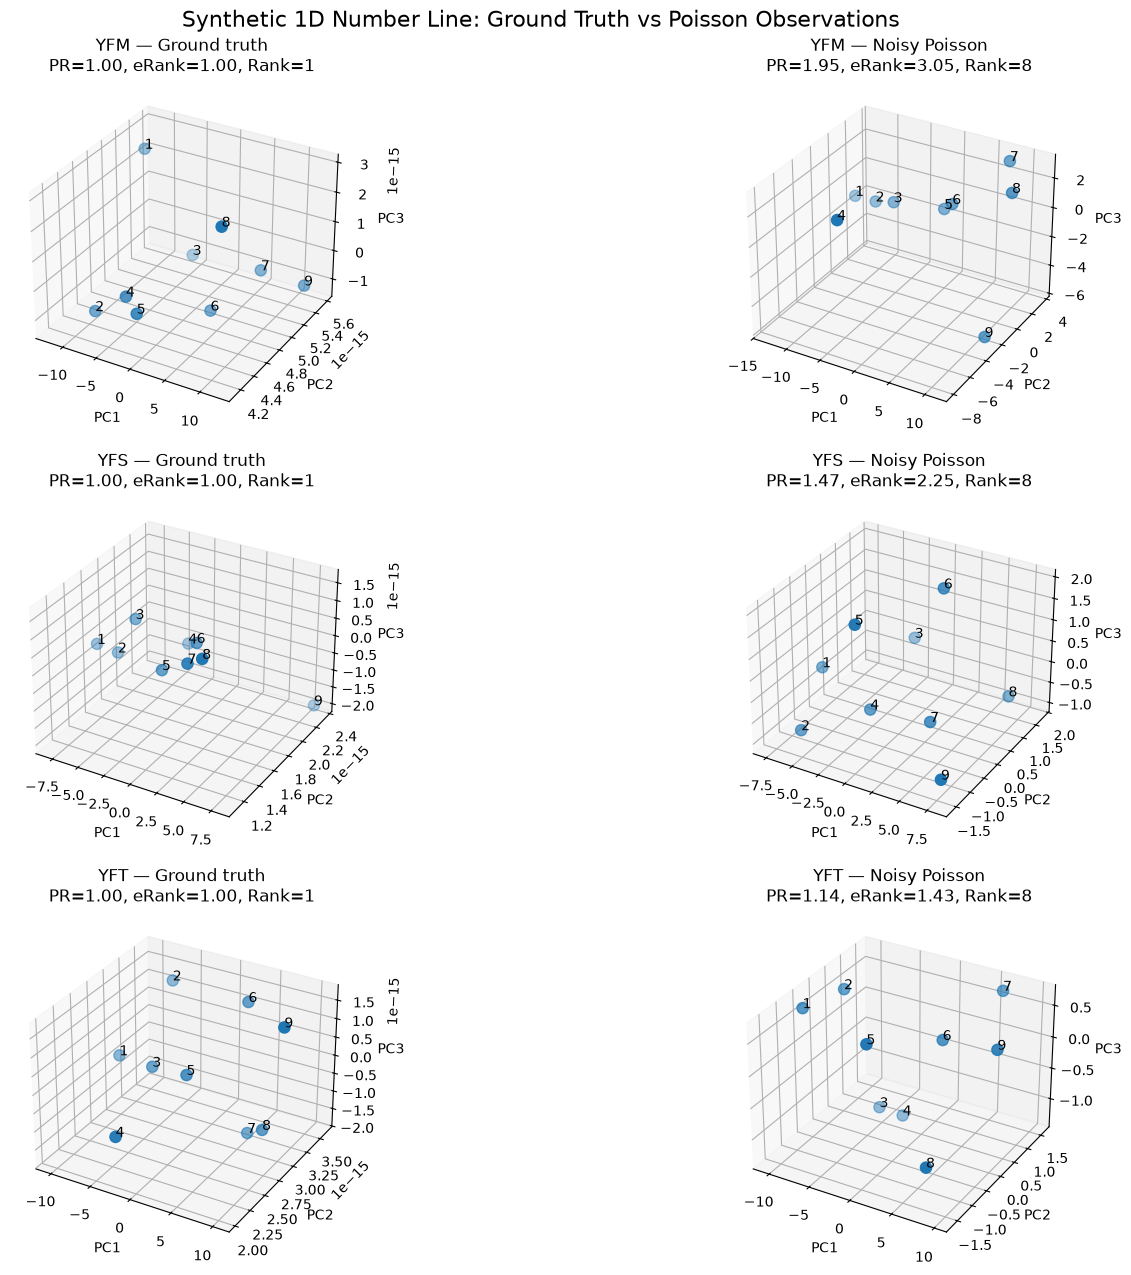

,subject,dataset,PR,effective_rank,affine_rank,mean_distance_hz,distance_CV
0,YFM,Ground truth,1.0000,1.0000,1,10.2391,0.5916
1,YFM,Noisy Poisson,1.9509,3.0517,8,13.8705,0.3501
2,YFS,Ground truth,1.0000,1.0000,1,6.6425,0.5916
3,YFS,Noisy Poisson,1.4732,2.2452,8,7.8510,0.4191
4,YFT,Ground truth,1.0000,1.0000,1,8.6879,0.5916
5,YFT,Noisy Poisson,1.1405,1.4279,8,9.5130,0.5169


In [104]:
rng = np.random.default_rng(2028)

line_strength = 0.30

line_population_centroids = {}
line_geometry_rows = []

fig = plt.figure(figsize=(17, 13))

for row, subject in enumerate(subjects):

    X = arithmetic_mtl_counts[subject]
    y = arithmetic_presentations[subject]["number"].to_numpy()

    # Baseline expected spike count per neuron
    lambda0 = X.mean(axis=0)

    # Expected spike counts for numbers 1–9
    # All nine expected centroids lie on one straight line
    numbers = np.arange(1, 10)

    gains = 1 + line_strength * (numbers - 5) / 4

    lambda_line = gains[:, None] * lambda0[None, :]

    # Generate synthetic Poisson spike counts
    X_line = np.empty(X.shape, dtype=int)

    for number in numbers:

        mask = y == number

        X_line[mask] = rng.poisson(
            lam=lambda_line[number - 1],
            size=(mask.sum(), X.shape[1])
        )

    # Estimated number centroids, converted to Hz
    M_line = np.vstack([
        X_line[y == number].mean(axis=0) / 0.9
        for number in numbers
    ])

    # Ground-truth number centroids, converted to Hz
    M_true = lambda_line / 0.9

    line_population_centroids[subject] = M_line

    for col, (kind, M) in enumerate([
        ("Ground truth", M_true),
        ("Noisy Poisson", M_line)
    ]):

        result = geometry_metrics(M)

        line_geometry_rows.append({
            "subject": subject,
            "dataset": kind,
            "PR": result["PR"],
            "effective_rank": result["effective_rank"],
            "affine_rank": result["affine_rank"],
            "mean_distance_hz": result["distance_mean"],
            "distance_CV": result["distance_cv"]
        })

        Z = result["Z"]

        ax = fig.add_subplot(
            3, 2, row * 2 + col + 1,
            projection="3d"
        )

        ax.scatter(
            Z[:, 0], Z[:, 1], Z[:, 2],
            s=65
        )

        for number, point in enumerate(Z, start=1):
            ax.text(*point[:3], str(number), fontsize=10)

        ax.set_title(
            f"{subject} — {kind}\n"
            f"PR={result['PR']:.2f}, "
            f"eRank={result['effective_rank']:.2f}, "
            f"Rank={result['affine_rank']}"
        )

        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.set_zlabel("PC3")

    print(f"\n{subject}")
    print("Ground-truth lambda shape:", lambda_line.shape)
    print("Number 1 gain:", gains[0])
    print("Number 9 gain:", gains[-1])

plt.suptitle(
    "Synthetic 1D Number Line: Ground Truth vs Poisson Observations",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_synthetic_number_line_PCA.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_synthetic_number_line_PCA.pdf",
    bbox_inches="tight"
)

plt.show()

line_geometry_df = pd.DataFrame(line_geometry_rows)

line_geometry_df.to_csv(
    TABLES / "arithmetic_synthetic_number_line_geometry.csv",
    index=False
)

display(line_geometry_df.round(4))

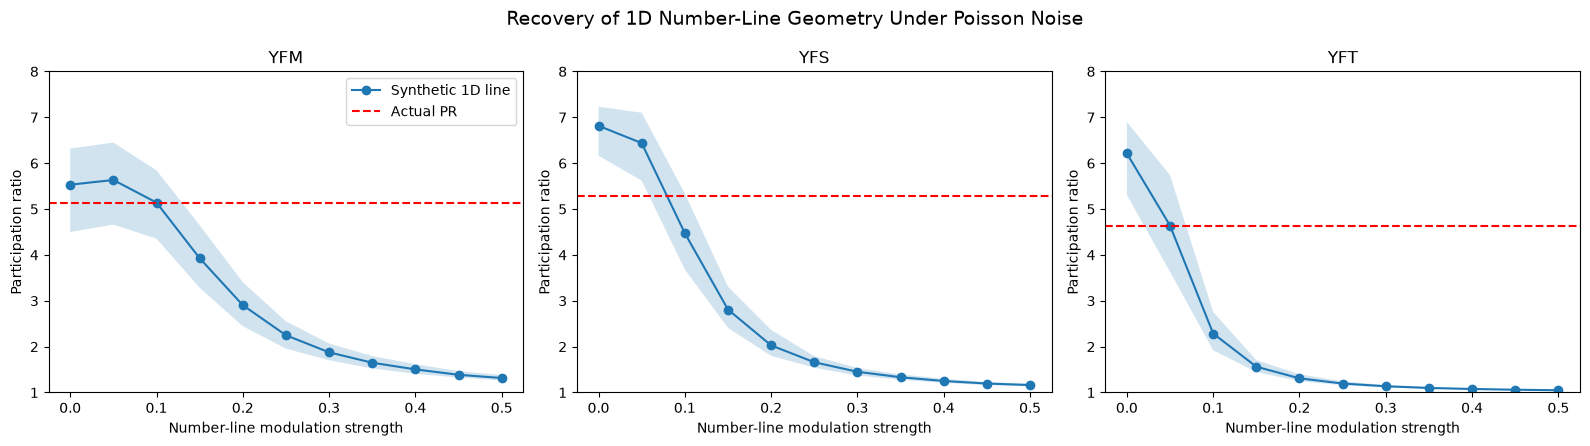

In [105]:
rng = np.random.default_rng(2029)

strengths = np.linspace(0, 0.5, 11)
n_repeats = 200

recovery_rows = []

for subject in subjects:

    X = arithmetic_mtl_counts[subject]
    y = arithmetic_presentations[subject]["number"].to_numpy()

    lambda0 = X.mean(axis=0)
    numbers = np.arange(1, 10)

    for strength in strengths:

        gains = 1 + strength * (numbers - 5) / 4

        lambda_line = gains[:, None] * lambda0[None, :]

        for repeat in range(n_repeats):

            X_sim = np.empty(X.shape, dtype=int)

            for number in numbers:
                mask = y == number

                X_sim[mask] = rng.poisson(
                    lam=lambda_line[number - 1],
                    size=(mask.sum(), X.shape[1])
                )

            M_sim = np.vstack([
                X_sim[y == number].mean(axis=0) / 0.9
                for number in numbers
            ])

            result = geometry_metrics(M_sim)

            recovery_rows.append({
                "subject": subject,
                "strength": strength,
                "repeat": repeat + 1,
                "PR": result["PR"],
                "effective_rank": result["effective_rank"],
                "affine_rank": result["affine_rank"],
                "PC1_fraction": result["PC1"]
            })

recovery_df = pd.DataFrame(recovery_rows)

recovery_df.to_csv(
    TABLES / "arithmetic_number_line_strength_recovery.csv",
    index=False
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    subset = recovery_df[
        recovery_df["subject"] == subject
    ]

    grouped = subset.groupby("strength")["PR"]

    mean_pr = grouped.mean()
    lower = grouped.quantile(0.025)
    upper = grouped.quantile(0.975)

    ax.plot(
        mean_pr.index,
        mean_pr.values,
        marker="o",
        label="Synthetic 1D line"
    )

    ax.fill_between(
        mean_pr.index,
        lower.values,
        upper.values,
        alpha=0.2
    )

    ax.axhline(
        pca_spectrum[subject]["participation_ratio"],
        color="red",
        linestyle="--",
        label="Actual PR"
    )

    ax.set_title(subject)
    ax.set_xlabel("Number-line modulation strength")
    ax.set_ylabel("Participation ratio")
    ax.set_ylim(1, 8)

axes[0].legend()

fig.suptitle(
    "Recovery of 1D Number-Line Geometry Under Poisson Noise",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_number_line_strength_recovery.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_number_line_strength_recovery.pdf",
    bbox_inches="tight"
)

plt.show()

Blue line: Mean PR across 200 synthetic Poisson simulations.



Shaded region: 95% simulation interval.



Red dashed line: PR measured from the actual neural data.

This experiment establishes an important methodological point:
\[
\boxed{
\text{True 1D geometry}+\text{Poisson noise}
\;\longrightarrow\;
\text{Apparently high-dimensional geometry}
}
\]

Recall that the score is the Pearson correlation:
\[
r=\operatorname{Corr}\left(
\|\boldsymbol{\mu}_i-\boldsymbol{\mu}_j\|_2,\ |i-j|
\right)
\]

In [106]:
from scipy.stats import pearsonr
from scipy.spatial.distance import pdist

numbers = np.arange(1, 10)
numerical_distances = pdist(numbers[:, None], metric="cityblock")

line_score_rows = []

for subject in subjects:

    M_real = population_centroids[subject].to_numpy()
    M_line = line_population_centroids[subject]

    d_real = pdist(M_real, metric="euclidean")
    d_line = pdist(M_line, metric="euclidean")

    r_real = pearsonr(numerical_distances, d_real).statistic
    r_line = pearsonr(numerical_distances, d_line).statistic

    line_score_rows.append({
        "subject": subject,
        "actual_line_score": r_real,
        "synthetic_line_score": r_line
    })

line_score_df = pd.DataFrame(line_score_rows)

display(line_score_df.round(4))

line_score_df.to_csv(
    TABLES / "arithmetic_number_line_geometry_scores.csv",
    index=False
)

,subject,actual_line_score,synthetic_line_score
0,YFM,-0.1226,0.9536
1,YFS,0.0161,0.9801
2,YFT,-0.0308,0.9914


Recall that the score is the Pearson correlation:
\[
r=\operatorname{Corr}\left(
\|\boldsymbol{\mu}_i-\boldsymbol{\mu}_j\|_2,\ |i-j|
\right)
\]

We compare all 36 pairs of numbers.
- Near +1: Numerically distant numbers tend to have more distant population representations.
- Near 0: No clear relationship between numerical distance and population distance.
- Negative: Numerically distant numbers tend to be closer in population space

r observed centroids do not exhibit the distance ordering expected from a clearly expressed, equally spaced number line.

However, we must be careful: the synthetic line scores were calculated at \(s=0.30\), whereas our previous PR comparison suggested that much weaker line signals could match the actual effective dimensionality.

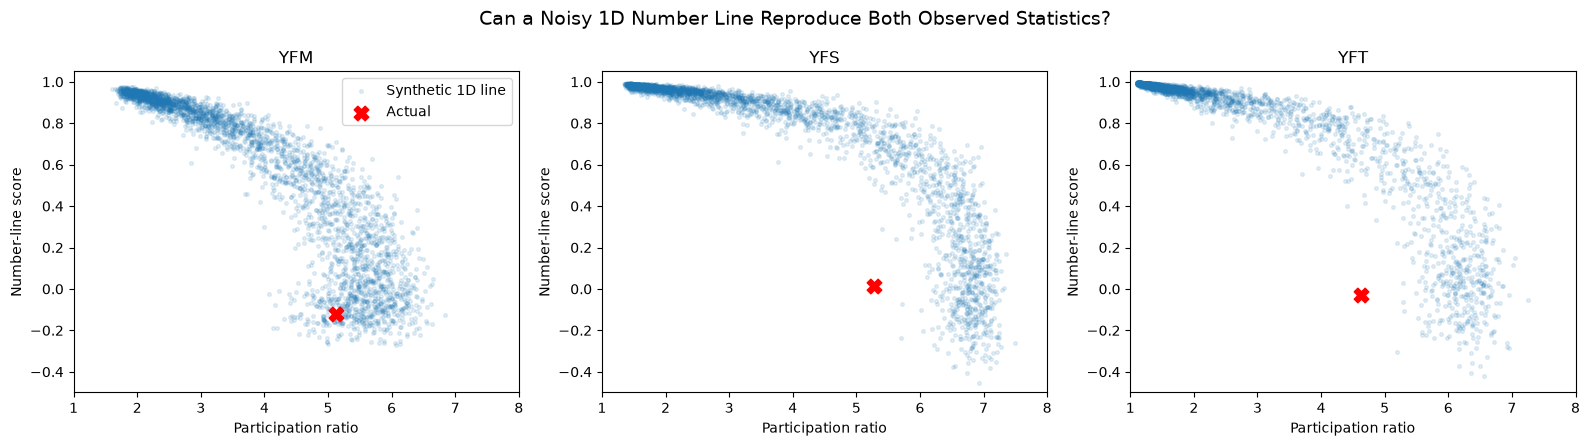

In [107]:
from scipy.stats import pearsonr
from scipy.spatial.distance import pdist

rng = np.random.default_rng(2030)

strengths = np.linspace(0, 0.30, 16)
n_repeats = 200

numbers = np.arange(1, 10)
numerical_distances = pdist(numbers[:, None])

joint_rows = []

for subject in subjects:

    X = arithmetic_mtl_counts[subject]
    y = arithmetic_presentations[subject]["number"].to_numpy()

    lambda0 = X.mean(axis=0)

    for strength in strengths:

        gains = 1 + strength * (numbers - 5) / 4
        lambda_line = gains[:, None] * lambda0[None, :]

        for repeat in range(n_repeats):

            X_sim = np.empty(X.shape, dtype=int)

            for number in numbers:
                mask = y == number

                X_sim[mask] = rng.poisson(
                    lam=lambda_line[number - 1],
                    size=(mask.sum(), X.shape[1])
                )

            M_sim = np.vstack([
                X_sim[y == number].mean(axis=0) / 0.9
                for number in numbers
            ])

            result = geometry_metrics(M_sim)

            line_score = pearsonr(
                numerical_distances,
                pdist(M_sim)
            ).statistic

            joint_rows.append({
                "subject": subject,
                "strength": strength,
                "repeat": repeat + 1,
                "PR": result["PR"],
                "line_score": line_score
            })

joint_df = pd.DataFrame(joint_rows)

joint_df.to_csv(
    TABLES / "arithmetic_number_line_joint_recovery.csv",
    index=False
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    subset = joint_df[joint_df.subject == subject]

    ax.scatter(
        subset["PR"],
        subset["line_score"],
        s=7,
        alpha=0.12,
        label="Synthetic 1D line"
    )

    observed_pr = pca_spectrum[subject]["participation_ratio"]

    observed_line_score = line_score_df.loc[
        line_score_df.subject == subject,
        "actual_line_score"
    ].iloc[0]

    ax.scatter(
        observed_pr,
        observed_line_score,
        s=110,
        color="red",
        marker="X",
        label="Actual"
    )

    ax.set_title(subject)
    ax.set_xlabel("Participation ratio")
    ax.set_ylabel("Number-line score")
    ax.set_xlim(1, 8)
    ax.set_ylim(-0.5, 1.05)

axes[0].legend()

fig.suptitle(
    "Can a Noisy 1D Number Line Reproduce Both Observed Statistics?",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_number_line_joint_recovery.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_number_line_joint_recovery.pdf",
    bbox_inches="tight"
)

plt.show()

Raw population analyses revealed eight-dimensional affine configurations of the nine numerical centroids across all three subjects. However, numerical-distance correlations were near zero (YFM: −0.123; YFS: 0.016; YFT: −0.031), whereas synthetic Poisson populations with an imposed one-dimensional number-line representation exhibited strong positive correlations (0.954–0.991) at the tested signal strength. These findings suggest that the observed population geometry is not well described by this particular equally spaced number-line model, although alternative one-dimensional representations and noise structures remain possible.

# Trial-level population representation instead of only centroids 


YFM
Within-number mean: 33.857
Between-number mean: 33.694
Between / within ratio: 0.9952

YFS
Within-number mean: 31.29
Between-number mean: 31.258
Between / within ratio: 0.999

YFT
Within-number mean: 26.162
Between-number mean: 26.171
Between / within ratio: 1.0004


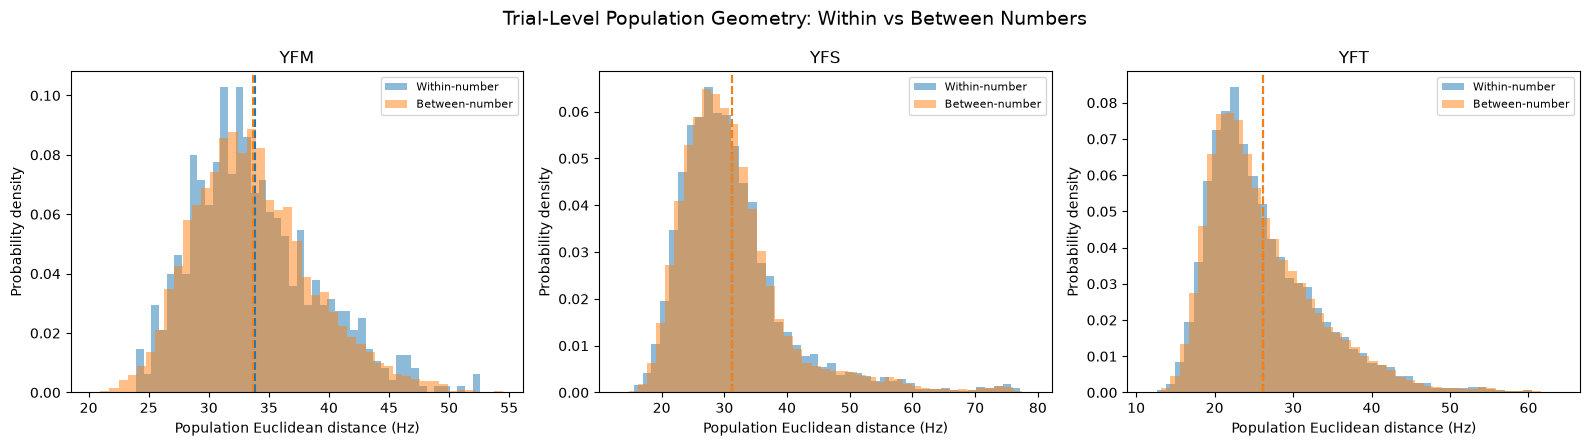

,subject,n_presentations,n_neurons,within_mean,between_mean,within_median,between_median,mean_difference,distance_ratio
0,YFM,114,129,33.8566,33.6943,33.1010,33.2035,-0.1623,0.9952
1,YFS,264,144,31.2901,31.2578,29.5125,29.5647,-0.0322,0.9990
2,YFT,477,91,26.1616,26.1713,24.3179,24.3686,0.0097,1.0004


In [108]:
from scipy.spatial.distance import pdist, squareform

trial_distance_results = {}
trial_distance_summary = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    # Individual presentation vectors in firing rates (Hz)
    X = arithmetic_mtl_counts[subject] / 0.9
    y = arithmetic_presentations[subject]["number"].to_numpy()
    trials = arithmetic_presentations[subject]["trial"].to_numpy()

    # Pairwise distances between all presentation vectors
    D = squareform(pdist(X, metric="euclidean"))

    # Use each pair only once; exclude diagonal
    i, j = np.triu_indices(len(y), k=1)

    # Exclude pairs from the same behavioral trial
    # (two operands within one trial are not independent)
    valid = trials[i] != trials[j]

    distances = D[i, j][valid]
    same_number = (y[i] == y[j])[valid]

    within = distances[same_number]
    between = distances[~same_number]

    trial_distance_results[subject] = {
        "within": within,
        "between": between
    }

    trial_distance_summary.append({
        "subject": subject,
        "n_presentations": len(y),
        "n_neurons": X.shape[1],
        "within_mean": within.mean(),
        "between_mean": between.mean(),
        "within_median": np.median(within),
        "between_median": np.median(between),
        "mean_difference": between.mean() - within.mean(),
        "distance_ratio": between.mean() / within.mean()
    })

    ax.hist(
        within,
        bins=45,
        density=True,
        alpha=0.5,
        label="Within-number"
    )

    ax.hist(
        between,
        bins=45,
        density=True,
        alpha=0.5,
        label="Between-number"
    )

    ax.axvline(
        within.mean(),
        color="tab:blue",
        linestyle="--",
        linewidth=1.5
    )

    ax.axvline(
        between.mean(),
        color="tab:orange",
        linestyle="--",
        linewidth=1.5
    )

    ax.set_title(subject)
    ax.set_xlabel("Population Euclidean distance (Hz)")
    ax.set_ylabel("Probability density")
    ax.legend(fontsize=8)

    print(f"\n{subject}")
    print("Within-number mean:", round(within.mean(), 3))
    print("Between-number mean:", round(between.mean(), 3))
    print("Between / within ratio:",
          round(between.mean() / within.mean(), 4))

fig.suptitle(
    "Trial-Level Population Geometry: Within vs Between Numbers",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_trial_within_between_distances.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_trial_within_between_distances.pdf",
    bbox_inches="tight"
)

plt.show()

trial_distance_summary_df = pd.DataFrame(trial_distance_summary)

trial_distance_summary_df.to_csv(
    TABLES / "arithmetic_trial_within_between_distances.csv",
    index=False
)

display(trial_distance_summary_df.round(4))


YFM
Population matrix: (114, 129)
First 3 PCs (%): [11.3   7.29  6.29]
Participation ratio: 26.01
Effective rank: 41.451

YFS
Population matrix: (264, 144)
First 3 PCs (%): [24.58  7.65  6.03]
Participation ratio: 12.366
Effective rank: 32.499

YFT
Population matrix: (477, 91)
First 3 PCs (%): [34.62  6.45  5.24]
Participation ratio: 7.359
Effective rank: 21.049


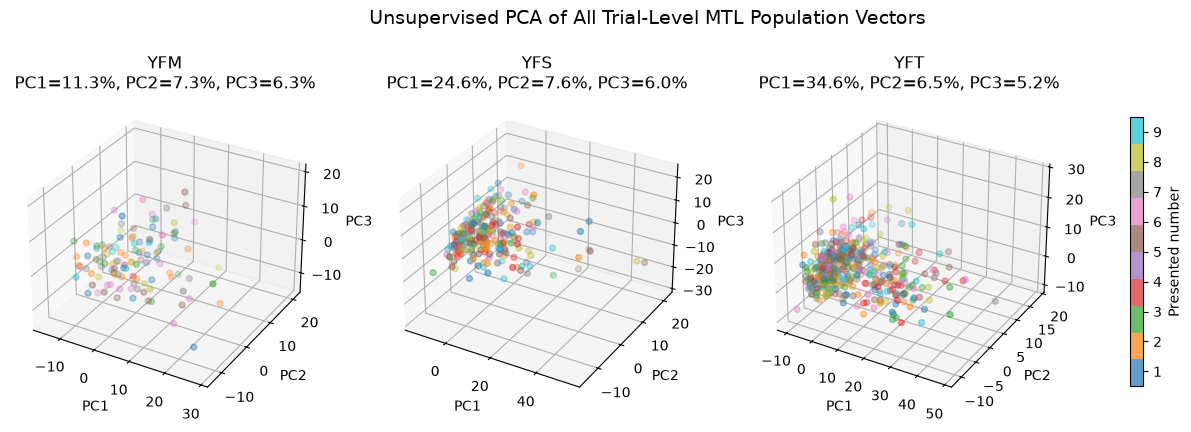

In [109]:
from sklearn.decomposition import PCA

trial_pca_results = {}

fig = plt.figure(figsize=(17, 5))

for i, subject in enumerate(subjects):

    X = arithmetic_mtl_counts[subject] / 0.9
    y = arithmetic_presentations[subject]["number"].to_numpy()

    # Unsupervised PCA on all individual population vectors
    pca = PCA(n_components=min(X.shape))
    Z = pca.fit_transform(X)

    eigenvalues = pca.explained_variance_
    explained = pca.explained_variance_ratio_

    pr = eigenvalues.sum()**2 / np.sum(eigenvalues**2)

    positive = explained[explained > 0]
    erank = np.exp(-np.sum(positive * np.log(positive)))

    trial_pca_results[subject] = {
        "pca": pca,
        "coordinates": Z,
        "explained_variance_ratio": explained,
        "participation_ratio": pr,
        "effective_rank": erank
    }

    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    scatter = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        Z[:, 2],
        c=y,
        cmap="tab10",
        vmin=0.5,
        vmax=9.5,
        s=18,
        alpha=0.7
    )

    variance = explained[:3] * 100

    ax.set_title(
        f"{subject}\n"
        f"PC1={variance[0]:.1f}%, "
        f"PC2={variance[1]:.1f}%, "
        f"PC3={variance[2]:.1f}%"
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")

    print(f"\n{subject}")
    print("Population matrix:", X.shape)
    print("First 3 PCs (%):", np.round(variance, 2))
    print("Participation ratio:", round(pr, 3))
    print("Effective rank:", round(erank, 3))

    pd.DataFrame({
        "number": y,
        "PC1": Z[:, 0],
        "PC2": Z[:, 1],
        "PC3": Z[:, 2]
    }).to_csv(
        TABLES / f"{subject}_arithmetic_trial_PCA_coordinates.csv",
        index=False
    )

    pd.DataFrame({
        "PC": np.arange(1, len(explained) + 1),
        "eigenvalue": eigenvalues,
        "explained_variance_ratio": explained
    }).to_csv(
        TABLES / f"{subject}_arithmetic_trial_PCA_spectrum.csv",
        index=False
    )

fig.suptitle(
    "Unsupervised PCA of All Trial-Level MTL Population Vectors",
    fontsize=14
)

fig.colorbar(
    scatter,
    ax=fig.axes,
    label="Presented number",
    shrink=0.7,
    ticks=range(1, 10)
)

plt.savefig(
    FIGURES / "arithmetic_trial_PCA_3D.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_trial_PCA_3D.pdf",
    bbox_inches="tight"
)

plt.show()


YFM
PCs for 80% variance: 28
PCs for 90% variance: 40
PCs for 95% variance: 52

YFS
PCs for 80% variance: 26
PCs for 90% variance: 45
PCs for 95% variance: 63

YFT
PCs for 80% variance: 19
PCs for 90% variance: 32
PCs for 95% variance: 43


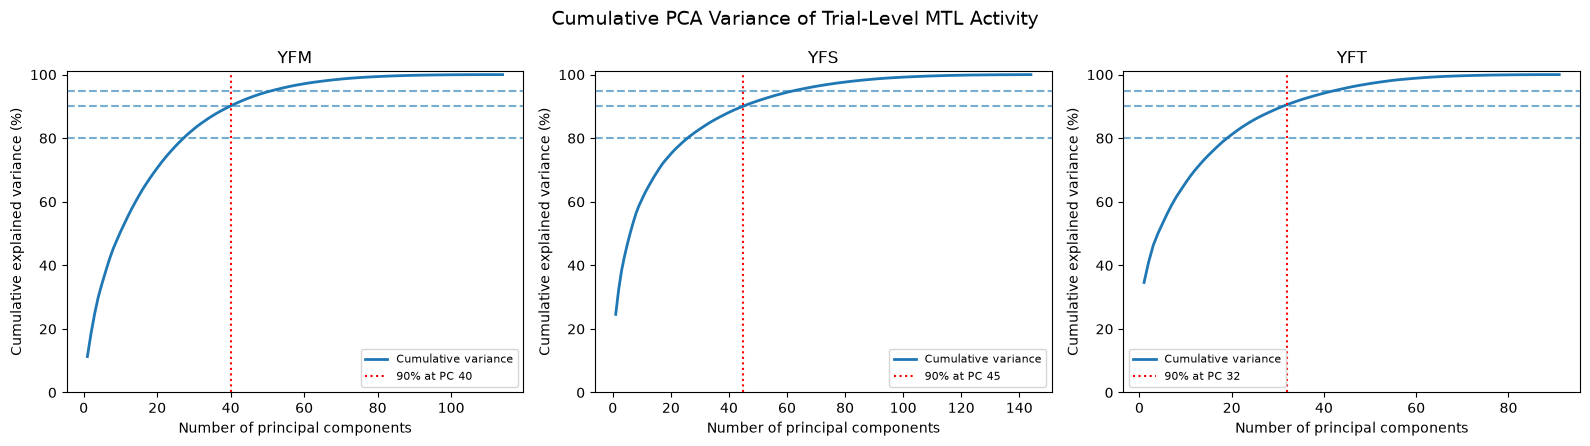

,subject,PR,effective_rank,PCs_for_80_percent,PCs_for_90_percent,PCs_for_95_percent
0,YFM,26.010,41.451,28,40,52
1,YFS,12.366,32.499,26,45,63
2,YFT,7.359,21.049,19,32,43


In [110]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

spectrum_summary = []

for ax, subject in zip(axes, subjects):

    result = trial_pca_results[subject]

    explained = result["explained_variance_ratio"]
    cumulative = np.cumsum(explained)

    n80 = np.searchsorted(cumulative, 0.80) + 1
    n90 = np.searchsorted(cumulative, 0.90) + 1
    n95 = np.searchsorted(cumulative, 0.95) + 1

    spectrum_summary.append({
        "subject": subject,
        "PR": result["participation_ratio"],
        "effective_rank": result["effective_rank"],
        "PCs_for_80_percent": n80,
        "PCs_for_90_percent": n90,
        "PCs_for_95_percent": n95
    })

    components = np.arange(1, len(explained) + 1)

    ax.plot(
        components,
        cumulative * 100,
        linewidth=2,
        label="Cumulative variance"
    )

    ax.axhline(80, linestyle="--", alpha=0.6)
    ax.axhline(90, linestyle="--", alpha=0.6)
    ax.axhline(95, linestyle="--", alpha=0.6)

    ax.axvline(
        n90,
        color="red",
        linestyle=":",
        label=f"90% at PC {n90}"
    )

    ax.set_title(subject)
    ax.set_xlabel("Number of principal components")
    ax.set_ylabel("Cumulative explained variance (%)")
    ax.set_ylim(0, 101)
    ax.legend(fontsize=8)

    print(f"\n{subject}")
    print("PCs for 80% variance:", n80)
    print("PCs for 90% variance:", n90)
    print("PCs for 95% variance:", n95)

fig.suptitle(
    "Cumulative PCA Variance of Trial-Level MTL Activity",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_trial_PCA_cumulative_variance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_trial_PCA_cumulative_variance.pdf",
    bbox_inches="tight"
)

plt.show()

spectrum_summary_df = pd.DataFrame(spectrum_summary)

spectrum_summary_df.to_csv(
    TABLES / "arithmetic_trial_PCA_dimensionality_summary.csv",
    index=False
)

display(spectrum_summary_df.round(3))

In [111]:
population_variance_results = []

for subject in subjects:

    X = arithmetic_mtl_counts[subject] / 0.9
    y = arithmetic_presentations[subject]["number"].to_numpy()

    grand_mean = X.mean(axis=0)

    SS_total = np.sum((X - grand_mean) ** 2)

    SS_between = 0.0
    SS_within = 0.0

    for number in range(1, 10):

        X_n = X[y == number]
        centroid = X_n.mean(axis=0)

        SS_between += len(X_n) * np.sum(
            (centroid - grand_mean) ** 2
        )

        SS_within += np.sum(
            (X_n - centroid) ** 2
        )

    eta_squared = SS_between / SS_total

    population_variance_results.append({
        "subject": subject,
        "SS_total": SS_total,
        "SS_between": SS_between,
        "SS_within": SS_within,
        "population_eta_squared": eta_squared,
        "number_variance_percent": 100 * eta_squared,
        "within_variance_percent": 100 * SS_within / SS_total
    })

population_variance_df = pd.DataFrame(
    population_variance_results
)

population_variance_df.to_csv(
    TABLES / "arithmetic_population_variance_decomposition.csv",
    index=False
)

display(population_variance_df.round(4))

,subject,SS_total,SS_between,SS_within,population_eta_squared,number_variance_percent,within_variance_percent
0,YFM,65510.5480,4095.4309,61415.1170,0.0625,6.2516,93.7484
1,YFS,138578.8627,4255.5657,134323.2970,0.0307,3.0709,96.9291
2,YFT,175252.7422,3100.7086,172152.0336,0.0177,1.7693,98.2307


# Next notebook cell — PCA reconstruction error

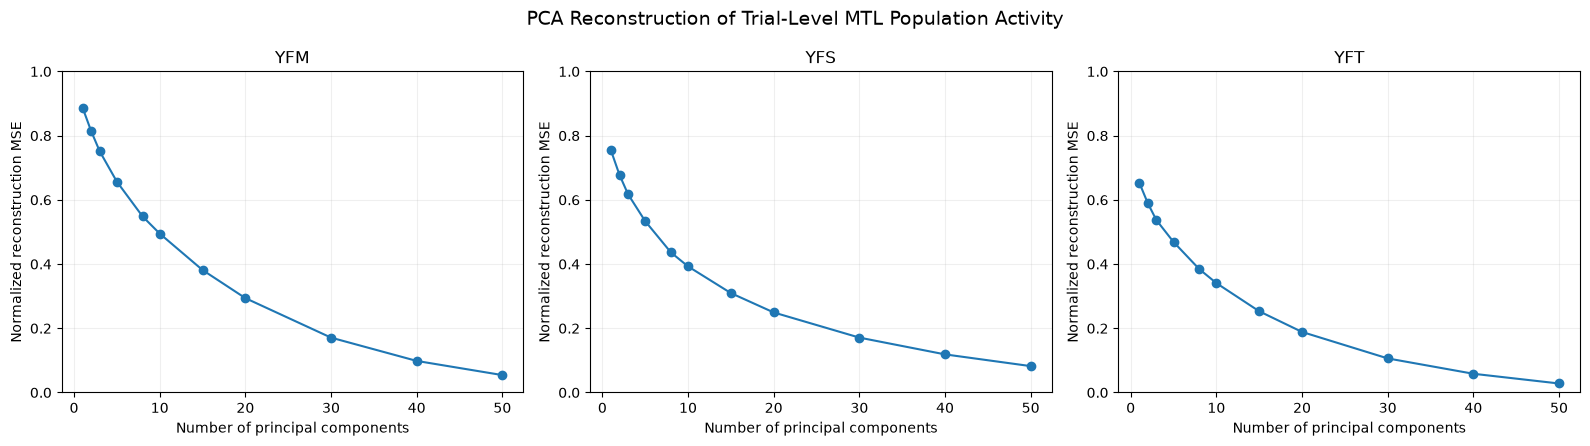

,subject,latent_dimension,MSE,normalized_MSE,variance_explained
0,YFM,1,3.9511,0.8870,0.1130
1,YFM,2,3.6265,0.8141,0.1859
2,YFM,3,3.3461,0.7511,0.2489
3,YFM,5,2.9254,0.6567,0.3433
4,YFM,8,2.4432,0.5485,0.4515
5,YFM,10,2.2050,0.4950,0.5050
6,YFM,15,1.6995,0.3815,0.6185
7,YFM,20,1.3094,0.2939,0.7061
8,YFM,30,0.7614,0.1709,0.8291
9,YFM,40,0.4381,0.0983,0.9017


In [112]:
pca_reconstruction_rows = []

dimensions = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 50]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    X = arithmetic_mtl_counts[subject] / 0.9

    pca = trial_pca_results[subject]["pca"]
    Z = trial_pca_results[subject]["coordinates"]

    valid_dimensions = [
        d for d in dimensions if d <= Z.shape[1]
    ]

    for d in valid_dimensions:

        # Reconstruct using first d principal components
        X_reconstructed = (
            Z[:, :d] @ pca.components_[:d, :]
            + pca.mean_
        )

        mse = np.mean((X - X_reconstructed) ** 2)

        normalized_mse = (
            np.sum((X - X_reconstructed) ** 2)
            / np.sum((X - X.mean(axis=0)) ** 2)
        )

        pca_reconstruction_rows.append({
            "subject": subject,
            "latent_dimension": d,
            "MSE": mse,
            "normalized_MSE": normalized_mse,
            "variance_explained": 1 - normalized_mse
        })

    subset = pd.DataFrame([
        row for row in pca_reconstruction_rows
        if row["subject"] == subject
    ])

    ax.plot(
        subset["latent_dimension"],
        subset["normalized_MSE"],
        marker="o"
    )

    ax.set_title(subject)
    ax.set_xlabel("Number of principal components")
    ax.set_ylabel("Normalized reconstruction MSE")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)

fig.suptitle(
    "PCA Reconstruction of Trial-Level MTL Population Activity",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_trial_PCA_reconstruction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_trial_PCA_reconstruction.pdf",
    bbox_inches="tight"
)

plt.show()

pca_reconstruction_df = pd.DataFrame(
    pca_reconstruction_rows
)

pca_reconstruction_df.to_csv(
    TABLES / "arithmetic_trial_PCA_reconstruction.csv",
    index=False
)

display(pca_reconstruction_df.round(4))

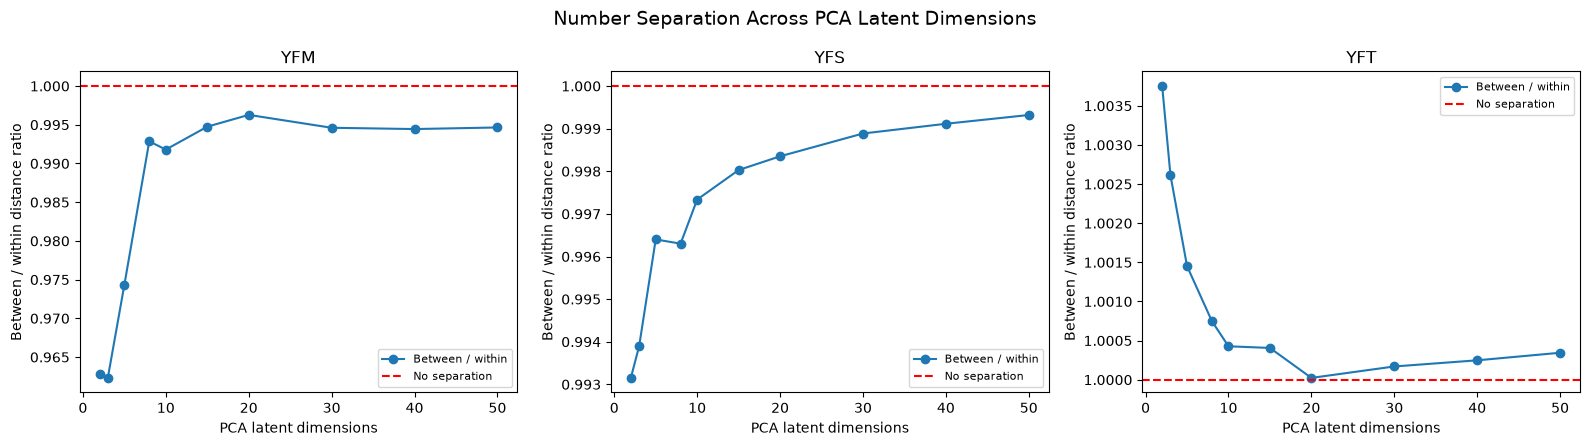

,subject,dimensions,distance_ratio,number_line_score
0,YFM,2,0.9628,-0.2071
1,YFM,3,0.9623,-0.1806
2,YFM,5,0.9743,-0.3199
3,YFM,8,0.9929,-0.2228
4,YFM,10,0.9918,-0.2220
5,YFM,15,0.9948,-0.1371
6,YFM,20,0.9963,-0.1644
7,YFM,30,0.9946,-0.1629
8,YFM,40,0.9944,-0.1258
9,YFM,50,0.9947,-0.1279


In [113]:
from scipy.spatial.distance import pdist

dimensions = [2, 3, 5, 8, 10, 15, 20, 30, 40, 50]

pca_geometry_rows = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    Z = trial_pca_results[subject]["coordinates"]
    y = arithmetic_presentations[subject]["number"].to_numpy()
    trials = arithmetic_presentations[subject]["trial"].to_numpy()

    i, j = np.triu_indices(len(y), k=1)

    valid = trials[i] != trials[j]
    same_number = y[i] == y[j]

    numerical_distances = pdist(
        np.arange(1, 10)[:, None]
    )

    for d in dimensions:

        if d > Z.shape[1]:
            continue

        Z_d = Z[:, :d]

        distances = pdist(Z_d)

        within = distances[valid & same_number]
        between = distances[valid & ~same_number]

        ratio = between.mean() / within.mean()

        centroids = np.vstack([
            Z_d[y == number].mean(axis=0)
            for number in range(1, 10)
        ])

        line_score = np.corrcoef(
            numerical_distances,
            pdist(centroids)
        )[0, 1]

        pca_geometry_rows.append({
            "subject": subject,
            "dimensions": d,
            "distance_ratio": ratio,
            "number_line_score": line_score
        })

    subset = pd.DataFrame([
        row for row in pca_geometry_rows
        if row["subject"] == subject
    ])

    ax.plot(
        subset["dimensions"],
        subset["distance_ratio"],
        marker="o",
        label="Between / within"
    )

    ax.axhline(
        1.0,
        color="red",
        linestyle="--",
        label="No separation"
    )

    ax.set_title(subject)
    ax.set_xlabel("PCA latent dimensions")
    ax.set_ylabel("Between / within distance ratio")
    ax.legend(fontsize=8)

fig.suptitle(
    "Number Separation Across PCA Latent Dimensions",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_PCA_latent_number_separation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_PCA_latent_number_separation.pdf",
    bbox_inches="tight"
)

plt.show()

pca_geometry_df = pd.DataFrame(pca_geometry_rows)

pca_geometry_df.to_csv(
    TABLES / "arithmetic_PCA_latent_number_geometry.csv",
    index=False
)

display(pca_geometry_df.round(4))

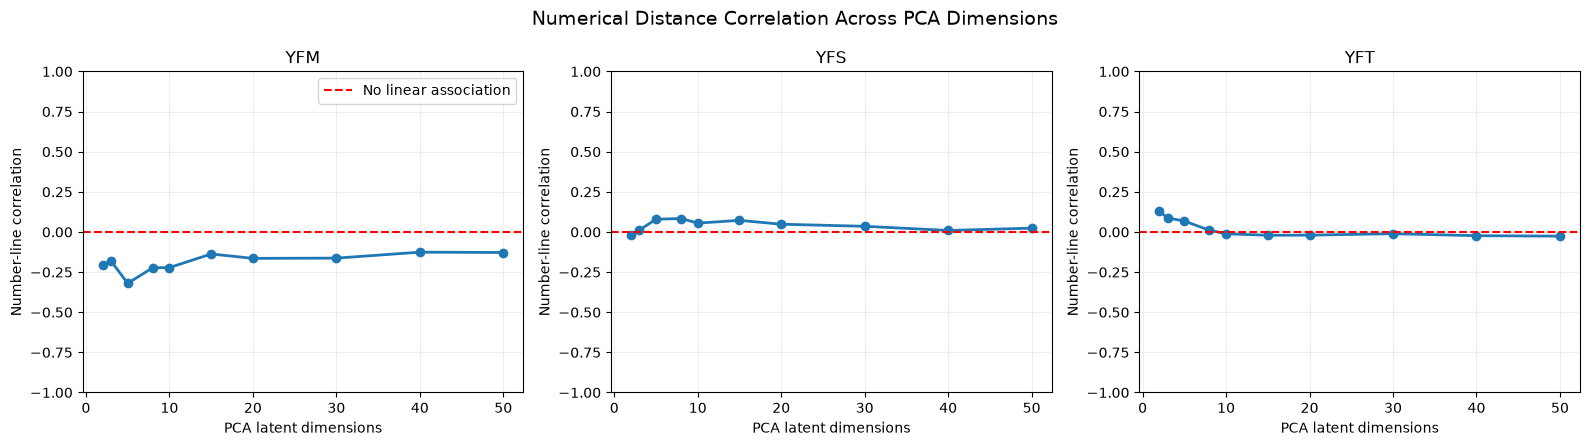

,subject,dimensions,number_line_score
0,YFM,2,-0.2071
1,YFM,3,-0.1806
2,YFM,5,-0.3199
3,YFM,8,-0.2228
4,YFM,10,-0.2220
5,YFM,15,-0.1371
6,YFM,20,-0.1644
7,YFM,30,-0.1629
8,YFM,40,-0.1258
9,YFM,50,-0.1279


In [114]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, subject in zip(axes, subjects):

    subset = pca_geometry_df[
        pca_geometry_df["subject"] == subject
    ].sort_values("dimensions")

    ax.plot(
        subset["dimensions"],
        subset["number_line_score"],
        marker="o",
        linewidth=2
    )

    ax.axhline(
        0,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="No linear association"
    )

    ax.set_title(subject)
    ax.set_xlabel("PCA latent dimensions")
    ax.set_ylabel("Number-line correlation")
    ax.set_ylim(-1, 1)
    ax.grid(alpha=0.2)

axes[0].legend()

fig.suptitle(
    "Numerical Distance Correlation Across PCA Dimensions",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_PCA_number_line_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_PCA_number_line_correlation.pdf",
    bbox_inches="tight"
)

plt.show()

display(
    pca_geometry_df[
        ["subject", "dimensions", "number_line_score"]
    ].round(4)
)

Analysis	Question	Finding
PCA visualization	Do numbers occupy different regions?	Extensive overlap
PCA variance spectrum	How many PCs describe the neural cloud?	32–45 PCs for 90% variance
PCA reconstruction	How much neural activity can PCA reconstruct?	Error decreases with more PCs
Within/between distances	Are same-number presentations more similar?	Ratios approximately 1
Numerical-distance correlation	Are neural distances related to numerical distances?	Correlations near zero or weakly negative

# World of autoencoders


In [115]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

ae_data = {}

for subject in subjects:

    # Full trial-level population firing rates
    X = np.asarray(
        arithmetic_mtl_counts[subject] / 0.9,
        dtype=np.float32
    )

    y = arithmetic_presentations[subject]["number"].to_numpy()
    trials = arithmetic_presentations[subject]["trial"].to_numpy()

    # Keep entire behavioral trials together
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=42
    )

    train_idx, val_idx = next(
        splitter.split(X, y, groups=trials)
    )

    # Fit scaling parameters on training data only
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X[train_idx])
    X_val = scaler.transform(X[val_idx])

    ae_data[subject] = {
        "X_train": X_train,
        "X_val": X_val,
        "y_train": y[train_idx],
        "y_val": y[val_idx],
        "train_idx": train_idx,
        "val_idx": val_idx,
        "scaler": scaler
    }

    print(f"\n{subject}")
    print("Training matrix:", X_train.shape)
    print("Validation matrix:", X_val.shape)
    print(
        "Training mean:",
        round(float(X_train.mean()), 4)
    )
    print(
        "Training std:",
        round(float(X_train.std()), 4)
    )


YFM
Training matrix: (93, 129)
Validation matrix: (21, 129)
Training mean: -0.0
Training std: 0.9844

YFS
Training matrix: (208, 144)
Validation matrix: (56, 144)
Training mean: -0.0
Training std: 1.0

YFT
Training matrix: (378, 91)
Validation matrix: (99, 91)
Training mean: -0.0
Training std: 0.9889


In [116]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [117]:
import torch
import torch.nn as nn

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
CUDA available: False


In [118]:
import torch
import torch.nn as nn

class LinearAutoencoder(nn.Module):

    def __init__(self, input_dim, latent_dim=3):
        super().__init__()

        self.encoder = nn.Linear(input_dim, latent_dim)
        self.decoder = nn.Linear(latent_dim, input_dim)

    def forward(self, x):
        z = self.encoder(x)
        x_reconstructed = self.decoder(z)
        return x_reconstructed

    def encode(self, x):
        return self.encoder(x)


# Initialize one autoencoder per subject
linear_ae_models = {}

torch.manual_seed(42)

for subject in subjects:

    input_dim = ae_data[subject]["X_train"].shape[1]

    model = LinearAutoencoder(
        input_dim=input_dim,
        latent_dim=3
    )

    linear_ae_models[subject] = model

    print(f"\n{subject}")
    print(model)
    print(
        "Trainable parameters:",
        sum(p.numel() for p in model.parameters())
    )
    


YFM
LinearAutoencoder(
  (encoder): Linear(in_features=129, out_features=3, bias=True)
  (decoder): Linear(in_features=3, out_features=129, bias=True)
)
Trainable parameters: 906

YFS
LinearAutoencoder(
  (encoder): Linear(in_features=144, out_features=3, bias=True)
  (decoder): Linear(in_features=3, out_features=144, bias=True)
)
Trainable parameters: 1011

YFT
LinearAutoencoder(
  (encoder): Linear(in_features=91, out_features=3, bias=True)
  (decoder): Linear(in_features=3, out_features=91, bias=True)
)
Trainable parameters: 640


Loss: Mean squared error (MSE)



Optimizer: Adam



Learning rate: 0.01



Epochs: 1,000



Latent dimension: 3



Training: Only training presentations; no number labels

In [119]:
from sklearn.decomposition import PCA
import torch.optim as optim

torch.manual_seed(42)

linear_ae_results = {}
linear_ae_history = {}

for subject in subjects:

    X_train = torch.tensor(
        ae_data[subject]["X_train"], dtype=torch.float32
    )
    X_val = torch.tensor(
        ae_data[subject]["X_val"], dtype=torch.float32
    )

    model = linear_ae_models[subject]
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    for epoch in range(1000):

        model.train()
        optimizer.zero_grad()

        reconstruction = model(X_train)
        loss = criterion(reconstruction, X_train)

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_reconstruction = model(X_val)
            val_loss = criterion(val_reconstruction, X_val)

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

    # PCA baseline using the same standardized training data
    pca = PCA(n_components=3)
    pca.fit(ae_data[subject]["X_train"])

    pca_train_recon = pca.inverse_transform(
        pca.transform(ae_data[subject]["X_train"])
    )
    pca_val_recon = pca.inverse_transform(
        pca.transform(ae_data[subject]["X_val"])
    )

    pca_train_mse = np.mean(
        (ae_data[subject]["X_train"] - pca_train_recon) ** 2
    )
    pca_val_mse = np.mean(
        (ae_data[subject]["X_val"] - pca_val_recon) ** 2
    )

    linear_ae_results[subject] = {
        "ae_train_mse": train_losses[-1],
        "ae_val_mse": val_losses[-1],
        "pca_train_mse": float(pca_train_mse),
        "pca_val_mse": float(pca_val_mse),
        "model": model,
        "pca": pca
    }

    linear_ae_history[subject] = {
        "train_loss": train_losses,
        "val_loss": val_losses
    }

    print(f"\n{subject}")
    print(f"AE train MSE: {train_losses[-1]:.6f}")
    print(f"AE val MSE:   {val_losses[-1]:.6f}")
    print(f"PCA train MSE: {pca_train_mse:.6f}")
    print(f"PCA val MSE:   {pca_val_mse:.6f}")


YFM
AE train MSE: 0.819511
AE val MSE:   1.119167
PCA train MSE: 0.819511
PCA val MSE:   1.082790

YFS
AE train MSE: 0.821894
AE val MSE:   0.870458
PCA train MSE: 0.821894
PCA val MSE:   0.870456

YFT
AE train MSE: 0.877051
AE val MSE:   0.999552
PCA train MSE: 0.877050
PCA val MSE:   0.999553


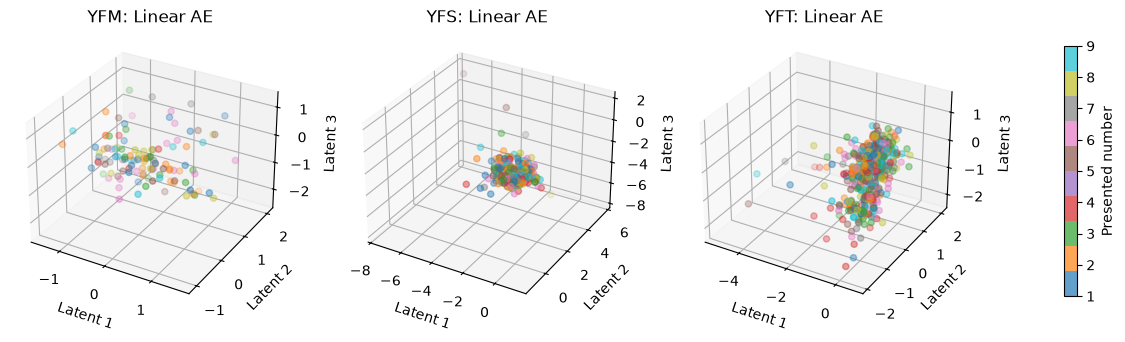

In [120]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(16, 5))

for i, subject in enumerate(subjects):

    model = linear_ae_results[subject]["model"]
    model.eval()

    # Encode all presentations using the training-fitted scaler
    X_all = arithmetic_mtl_counts[subject] / 0.9
    scaler = ae_data[subject]["scaler"]
    X_scaled = scaler.transform(X_all).astype(np.float32)

    with torch.no_grad():
        Z = model.encode(
            torch.tensor(X_scaled)
        ).numpy()

    y = arithmetic_presentations[subject]["number"].to_numpy()

    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    scatter = ax.scatter(
        Z[:, 0], Z[:, 1], Z[:, 2],
        c=y, cmap="tab10", s=20, alpha=0.7
    )

    ax.set_title(f"{subject}: Linear AE")
    ax.set_xlabel("Latent 1")
    ax.set_ylabel("Latent 2")
    ax.set_zlabel("Latent 3")

fig.colorbar(
    scatter, ax=fig.axes,
    label="Presented number",
    shrink=0.65,
    pad=0.08
)

plt.savefig(
    FIGURES / "arithmetic_linear_AE_3D.png",
    dpi=300, bbox_inches="tight"
)
plt.savefig(
    FIGURES / "arithmetic_linear_AE_3D.pdf",
    bbox_inches="tight"
)

plt.show()

The above looks like PCA< so stop >

NOn linear autoencoder

ReLU is the acticvation function here


Which has one hidden layer 

In [121]:
import torch
import torch.nn as nn

class NonlinearAutoencoder(nn.Module):

    def __init__(self, input_dim, latent_dim=3, hidden_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_reconstructed = self.decoder(z)
        return x_reconstructed

    def encode(self, x):
        return self.encoder(x)


# Initialize one nonlinear autoencoder per subject
nonlinear_ae_models = {}

torch.manual_seed(42)

for subject in subjects:

    input_dim = ae_data[subject]["X_train"].shape[1]

    model = NonlinearAutoencoder(
        input_dim=input_dim,
        latent_dim=3,
        hidden_dim=32
    )

    nonlinear_ae_models[subject] = model

    print(f"\n{subject}")
    print(
        "Architecture:",
        f"{input_dim} → 32 → 3 → 32 → {input_dim}"
    )
    print(
        "Trainable parameters:",
        sum(p.numel() for p in model.parameters())
    )


YFM
Architecture: 129 → 32 → 3 → 32 → 129
Trainable parameters: 8644

YFS
Architecture: 144 → 32 → 3 → 32 → 144
Trainable parameters: 9619

YFT
Architecture: 91 → 32 → 3 → 32 → 91
Trainable parameters: 6174


raining configuration:
- Loss: Mean squared error (MSE)
- Optimizer: Adam, learning rate 0.001
- Maximum epochs: 1,000
- Early stopping patience: 60 epochs
- Latent dimensions: 3

In [122]:
import copy
import torch.optim as optim

torch.manual_seed(42)

nonlinear_ae_results = {}
nonlinear_ae_history = {}

for subject in subjects:

    X_train = torch.tensor(
        ae_data[subject]["X_train"],
        dtype=torch.float32
    )
    X_val = torch.tensor(
        ae_data[subject]["X_val"],
        dtype=torch.float32
    )

    model = nonlinear_ae_models[subject]
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    patience = 60
    epochs_without_improvement = 0

    for epoch in range(1000):

        # Training
        model.train()
        optimizer.zero_grad()

        reconstruction = model(X_train)
        train_loss = criterion(reconstruction, X_train)

        train_loss.backward()
        optimizer.step()

        # Validation
        model.eval()

        with torch.no_grad():
            val_reconstruction = model(X_val)
            val_loss = criterion(val_reconstruction, X_val)

        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

        # Early stopping
        if val_loss.item() < best_val_loss - 1e-6:
            best_val_loss = val_loss.item()
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    # Restore best validation model
    model.load_state_dict(best_weights)
    model.eval()

    nonlinear_ae_results[subject] = {
        "model": model,
        "best_epoch": best_epoch,
        "train_mse": train_losses[best_epoch - 1],
        "val_mse": best_val_loss
    }

    nonlinear_ae_history[subject] = {
        "train_loss": train_losses,
        "val_loss": val_losses
    }

    print(f"\n{subject}")
    print(f"Best epoch: {best_epoch}")
    print(f"Nonlinear AE train MSE: {train_losses[best_epoch - 1]:.6f}")
    print(f"Nonlinear AE val MSE:   {best_val_loss:.6f}")
    print(f"PCA val MSE:            {linear_ae_results[subject]['pca_val_mse']:.6f}")
    print(f"Linear AE val MSE:      {linear_ae_results[subject]['ae_val_mse']:.6f}")


YFM
Best epoch: 129
Nonlinear AE train MSE: 0.756247
Nonlinear AE val MSE:   1.112024
PCA val MSE:            1.082790
Linear AE val MSE:      1.119167

YFS
Best epoch: 154
Nonlinear AE train MSE: 0.774068
Nonlinear AE val MSE:   0.857790
PCA val MSE:            0.870456
Linear AE val MSE:      0.870458

YFT
Best epoch: 320
Nonlinear AE train MSE: 0.781697
Nonlinear AE val MSE:   0.966371
PCA val MSE:            0.999553
Linear AE val MSE:      0.999552


or YFS and YFT, the nonlinear autoencoder may be capturing some structure that a three-dimensional linear projection cannot reconstruct as efficiently.

For YFM, PCA remains better on validation data, suggesting that the additional nonlinear flexibility has not helped on this split.

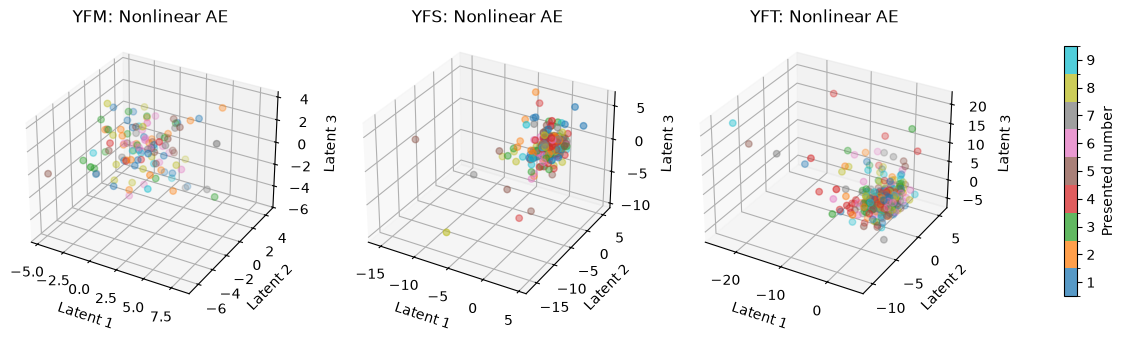

In [123]:
from matplotlib.colors import BoundaryNorm

fig = plt.figure(figsize=(16, 5))

cmap = plt.get_cmap("tab10", 9)
norm = BoundaryNorm(np.arange(0.5, 10.5, 1), cmap.N)

for i, subject in enumerate(subjects):

    model = nonlinear_ae_results[subject]["model"]
    model.eval()

    # Use the same training-fitted scaler
    X_all = (
        arithmetic_mtl_counts[subject] / 0.9
    ).astype(np.float32)

    X_scaled = ae_data[subject]["scaler"].transform(
        X_all
    ).astype(np.float32)

    with torch.no_grad():
        Z = model.encode(
            torch.from_numpy(X_scaled)
        ).cpu().numpy()

    y = arithmetic_presentations[subject][
        "number"
    ].to_numpy()

    ax = fig.add_subplot(
        1, 3, i + 1, projection="3d"
    )

    scatter = ax.scatter(
        Z[:, 0], Z[:, 1], Z[:, 2],
        c=y,
        cmap=cmap,
        norm=norm,
        s=22,
        alpha=0.75
    )

    ax.set_title(f"{subject}: Nonlinear AE")
    ax.set_xlabel("Latent 1")
    ax.set_ylabel("Latent 2")
    ax.set_zlabel("Latent 3")

cbar = fig.colorbar(
    scatter,
    ax=fig.axes,
    ticks=np.arange(1, 10),
    shrink=0.65,
    pad=0.08
)
cbar.set_label("Presented number")

plt.savefig(
    FIGURES / "arithmetic_nonlinear_AE_3D.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES / "arithmetic_nonlinear_AE_3D.pdf",
    bbox_inches="tight"
)

plt.show()

2. Comparison with the linear autoencoder
Property	Linear AE	Nonlinear AE
Reconstruction	Approximately equivalent to PCA	Better validation MSE for YFS and YFT
Latent geometry	Linear transformation	Nonlinear transformation
Number clusters	No obvious separation	No obvious separation
Numerical ordering	Not yet quantified	Not yet quantified

In [124]:
from scipy.spatial.distance import pdist, squareform
from scipy.stats import pearsonr

nonlinear_ae_geometry = []

for subject in subjects:

    model = nonlinear_ae_results[subject]["model"]
    model.eval()

    X_all = (
        arithmetic_mtl_counts[subject] / 0.9
    ).astype(np.float32)

    X_scaled = ae_data[subject]["scaler"].transform(
        X_all
    ).astype(np.float32)

    with torch.no_grad():
        Z = model.encode(
            torch.from_numpy(X_scaled)
        ).cpu().numpy()

    y = arithmetic_presentations[subject]["number"].to_numpy()
    trials = arithmetic_presentations[subject]["trial"].to_numpy()

    # Pairwise distances between presentations
    D = squareform(pdist(Z, metric="euclidean"))

    upper = np.triu(np.ones(D.shape, dtype=bool), k=1)

    # Exclude pairs from the same behavioral trial
    eligible = upper & (trials[:, None] != trials[None, :])

    within = D[eligible & (y[:, None] == y[None, :])]
    between = D[eligible & (y[:, None] != y[None, :])]

    separation_ratio = between.mean() / within.mean()

    # Nine number centroids in latent space
    centroids = np.array([
        Z[y == number].mean(axis=0)
        for number in range(1, 10)
    ])

    neural_distances = pdist(centroids)

    numerical_distances = pdist(
        np.arange(1, 10).reshape(-1, 1),
        metric="cityblock"
    )

    number_line_score, _ = pearsonr(
        numerical_distances,
        neural_distances
    )

    nonlinear_ae_geometry.append({
        "subject": subject,
        "latent_dimensions": 3,
        "within_distance": within.mean(),
        "between_distance": between.mean(),
        "separation_ratio": separation_ratio,
        "number_line_score": number_line_score
    })

nonlinear_ae_geometry_df = pd.DataFrame(nonlinear_ae_geometry)

display(nonlinear_ae_geometry_df.round(4))

nonlinear_ae_geometry_df.to_csv(
    TABLES / "arithmetic_nonlinear_AE_geometry.csv",
    index=False
)

,subject,latent_dimensions,within_distance,between_distance,separation_ratio,number_line_score
0,YFM,3,4.3063,4.2986,0.9982,-0.1885
1,YFS,3,3.5834,3.5291,0.9848,0.0945
2,YFT,3,4.6128,4.6207,1.0017,-0.2106


All three ratios are approximately 1.

This means that, in the learned latent space, presentations of different numbers are approximately as far apart as presentations of the same number.

	No clear separation or ordering

# SPArse autoencoder

A sparse autoencoder restricts how many latent features are active for each input


A sparse autoencoder can instead use:
\[
\boxed{129\rightarrow64\rightarrow129}
\]

Here, we have 64 latent features, but we encourage only a few to be active for any individual presentation.

Our previous autoencoders minimized reconstruction error:
\[
\mathcal L_{\mathrm{reconstruction}}
=\frac{1}{Np}\sum_{i=1}^N
\|\mathbf x_i-\hat{\mathbf x}_i\|_2^2
\]

For a sparse autoencoder, we add a sparsity penalty:
\[
\boxed{
\mathcal L_{\mathrm{total}}
=
\mathcal L_{\mathrm{reconstruction}}
+
\lambda\mathcal L_{\mathrm{sparsity}}
}
\]

A common choice is an L1 penalty on the latent activations:

A sparse autoencoder might learn latent features such as:
- A pattern involving a particular subset of neurons.
- A pattern associated with unusually high population activity.
- A pattern associated with operand position or arithmetic context.
- Potentially, a pattern associated with certain numbers.

In [125]:
import torch
import torch.nn as nn

class SparseAutoencoder(nn.Module):

    def __init__(self, input_dim, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, latent_dim),
            nn.ReLU()
        )

        self.decoder = nn.Linear(
            latent_dim,
            input_dim,
            bias=True
        )

        # Normalize decoder columns at initialization
        self.normalize_decoder()

    def forward(self, x):
        z = self.encoder(x)
        x_reconstructed = self.decoder(z)
        return x_reconstructed, z

    def encode(self, x):
        return self.encoder(x)

    @torch.no_grad()
    def normalize_decoder(self):
        # Decoder weight shape: input_dim × latent_dim
        W = self.decoder.weight

        norms = torch.linalg.vector_norm(
            W, dim=0, keepdim=True
        ).clamp_min(1e-8)

        W.div_(norms)


# Initialize sparse autoencoders
torch.manual_seed(42)

sparse_ae_models = {}

for subject in subjects:

    input_dim = ae_data[subject]["X_train"].shape[1]

    model = SparseAutoencoder(
        input_dim=input_dim,
        latent_dim=64
    )

    sparse_ae_models[subject] = model

    print(f"\n{subject}")
    print(f"Architecture: {input_dim} → 64 → {input_dim}")

    print(
        "Trainable parameters:",
        sum(p.numel() for p in model.parameters())
    )

    print(
        "Decoder column norms:",
        torch.linalg.vector_norm(
            model.decoder.weight, dim=0
        ).min().item(),
        "to",
        torch.linalg.vector_norm(
            model.decoder.weight, dim=0
        ).max().item()
    )


YFM
Architecture: 129 → 64 → 129
Trainable parameters: 16705
Decoder column norms: 0.9999995827674866 to 1.000000238418579

YFS
Architecture: 144 → 64 → 144
Trainable parameters: 18640
Decoder column norms: 0.9999997019767761 to 1.000000238418579

YFT
Architecture: 91 → 64 → 91
Trainable parameters: 11803
Decoder column norms: 0.9999997019767761 to 1.000000238418579


In [126]:
import copy
import torch.optim as optim

torch.manual_seed(42)

sparse_ae_results = {}
sparse_ae_history = {}

lambda_sparse = 0.01
max_epochs = 1500
patience = 100

for subject in subjects:

    X_train = torch.tensor(
        ae_data[subject]["X_train"],
        dtype=torch.float32
    )
    X_val = torch.tensor(
        ae_data[subject]["X_val"],
        dtype=torch.float32
    )

    model = sparse_ae_models[subject]
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_mse": [],
        "val_mse": [],
        "train_l1": []
    }

    best_val = float("inf")
    best_epoch = 0
    best_weights = None
    epochs_without_improvement = 0

    for epoch in range(max_epochs):

        # Training
        model.train()
        optimizer.zero_grad()

        reconstruction, z = model(X_train)

        mse = nn.functional.mse_loss(
            reconstruction, X_train
        )

        # Mean L1 norm per presentation
        l1 = z.abs().sum(dim=1).mean()

        loss = mse + lambda_sparse * l1

        loss.backward()
        optimizer.step()

        # Enforce unit-norm decoder columns
        model.normalize_decoder()

        # Validation
        model.eval()

        with torch.no_grad():
            val_reconstruction, val_z = model(X_val)

            val_mse = nn.functional.mse_loss(
                val_reconstruction, X_val
            ).item()

        history["train_mse"].append(mse.item())
        history["val_mse"].append(val_mse)
        history["train_l1"].append(l1.item())

        if val_mse < best_val - 1e-6:
            best_val = val_mse
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_weights)
    model.eval()

    # Evaluate restored model
    with torch.no_grad():
        train_reconstruction, train_z = model(X_train)
        val_reconstruction, val_z = model(X_val)

        train_mse = nn.functional.mse_loss(
            train_reconstruction, X_train
        ).item()

        val_mse = nn.functional.mse_loss(
            val_reconstruction, X_val
        ).item()

        # ReLU produces exact zeros
        train_active = (train_z > 1e-6).sum(dim=1).float()
        val_active = (val_z > 1e-6).sum(dim=1).float()

    sparse_ae_results[subject] = {
        "model": model,
        "best_epoch": best_epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "train_active": train_active.mean().item(),
        "val_active": val_active.mean().item()
    }

    sparse_ae_history[subject] = history

    print(f"\n{subject}")
    print(f"Best epoch: {best_epoch}")
    print(f"Training MSE:   {train_mse:.6f}")
    print(f"Validation MSE: {val_mse:.6f}")
    print(
        f"Active features (train): "
        f"{train_active.mean().item():.2f}/64"
    )
    print(
        f"Active features (val):   "
        f"{val_active.mean().item():.2f}/64"
    )


YFM
Best epoch: 476
Training MSE:   0.158078
Validation MSE: 0.817686
Active features (train): 11.22/64
Active features (val):   29.76/64

YFS
Best epoch: 472
Training MSE:   0.319152
Validation MSE: 0.637780
Active features (train): 14.75/64
Active features (val):   26.07/64

YFT
Best epoch: 736
Training MSE:   0.306330
Validation MSE: 0.546339
Active features (train): 22.50/64
Active features (val):   27.41/64


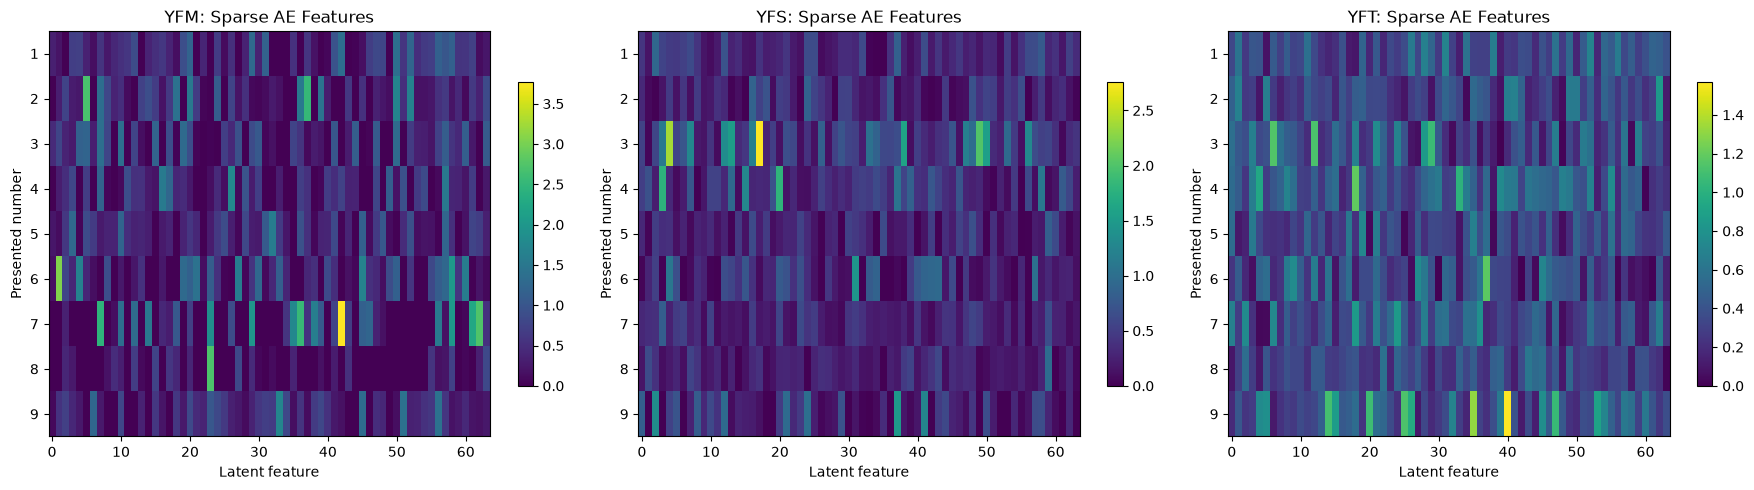

In [127]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sparse_feature_tables = {}

for ax, subject in zip(axes, subjects):

    model = sparse_ae_results[subject]["model"]
    model.eval()

    X_val = torch.tensor(
        ae_data[subject]["X_val"],
        dtype=torch.float32
    )

    y_val = ae_data[subject]["y_val"]

    with torch.no_grad():
        Z_val = model.encode(X_val).cpu().numpy()

    mean_activations = np.full((9, 64), np.nan)

    for number in range(1, 10):
        mask = y_val == number

        if mask.any():
            mean_activations[number - 1] = Z_val[mask].mean(axis=0)

    sparse_feature_tables[subject] = mean_activations

    im = ax.imshow(
        mean_activations,
        aspect="auto",
        interpolation="nearest",
        cmap="viridis"
    )

    ax.set_title(f"{subject}: Sparse AE Features")
    ax.set_xlabel("Latent feature")
    ax.set_ylabel("Presented number")
    ax.set_yticks(range(9))
    ax.set_yticklabels(range(1, 10))

    fig.colorbar(im, ax=ax, shrink=0.75)

    pd.DataFrame(
        mean_activations,
        index=range(1, 10),
        columns=[f"Feature_{i+1}" for i in range(64)]
    ).to_csv(
        TABLES / f"{subject}_sparse_AE_number_activations.csv"
    )

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_sparse_AE_number_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES / "arithmetic_sparse_AE_number_heatmaps.pdf",
    bbox_inches="tight"
)

plt.show()


YFM
Valid features: 64/64
Mean correlation:   -0.0314
Median correlation: -0.0726
Fraction r > 0.5:   0.0625

YFS
Valid features: 64/64
Mean correlation:   -0.0569
Median correlation: -0.0828
Fraction r > 0.5:   0.0469

YFT
Valid features: 64/64
Mean correlation:   0.0423
Median correlation: 0.1073
Fraction r > 0.5:   0.1250


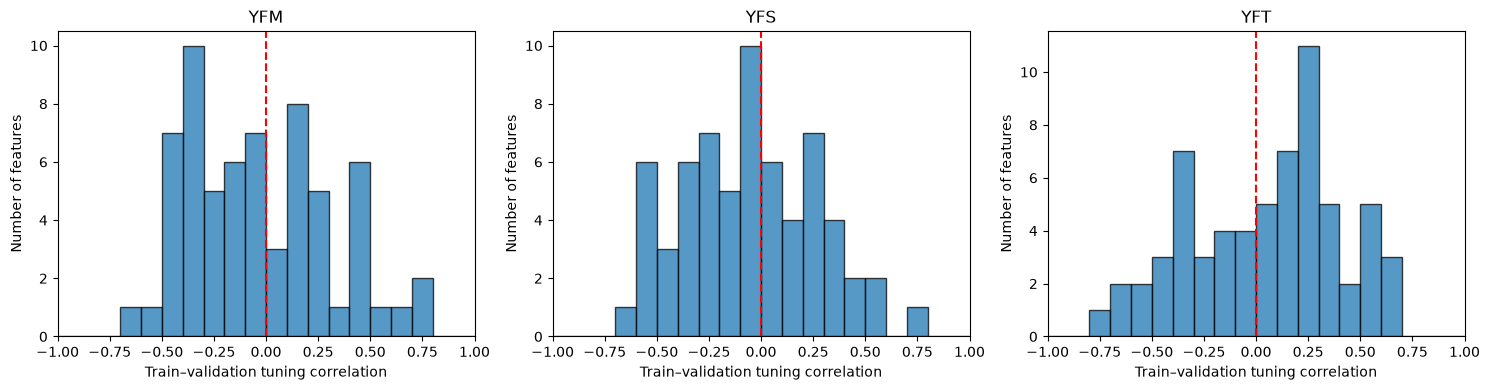

In [128]:
from scipy.stats import pearsonr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sparse_reliability_rows = []

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, subject in zip(axes, subjects):

    model = sparse_ae_results[subject]["model"]
    model.eval()

    X_train = torch.tensor(
        ae_data[subject]["X_train"], dtype=torch.float32
    )
    X_val = torch.tensor(
        ae_data[subject]["X_val"], dtype=torch.float32
    )

    y_train = ae_data[subject]["y_train"]
    y_val = ae_data[subject]["y_val"]

    with torch.no_grad():
        Z_train = model.encode(X_train).cpu().numpy()
        Z_val = model.encode(X_val).cpu().numpy()

    correlations = []

    for j in range(Z_train.shape[1]):

        train_means = []
        val_means = []

        for number in range(1, 10):

            train_mask = y_train == number
            val_mask = y_val == number

            if train_mask.any() and val_mask.any():
                train_means.append(
                    Z_train[train_mask, j].mean()
                )
                val_means.append(
                    Z_val[val_mask, j].mean()
                )

        train_means = np.asarray(train_means)
        val_means = np.asarray(val_means)

        if (
            len(train_means) >= 3
            and np.std(train_means) > 1e-8
            and np.std(val_means) > 1e-8
        ):
            r, _ = pearsonr(train_means, val_means)
        else:
            r = np.nan

        correlations.append(r)

        sparse_reliability_rows.append({
            "subject": subject,
            "feature": j + 1,
            "train_val_correlation": r,
            "numbers_compared": len(train_means)
        })

    correlations = np.asarray(correlations)

    valid = correlations[np.isfinite(correlations)]

    ax.hist(
        valid,
        bins=np.linspace(-1, 1, 21),
        edgecolor="black",
        alpha=0.75
    )

    ax.axvline(0, color="red", linestyle="--")
    ax.set_xlim(-1, 1)
    ax.set_xlabel("Train–validation tuning correlation")
    ax.set_ylabel("Number of features")
    ax.set_title(subject)

    print(f"\n{subject}")
    print(f"Valid features: {len(valid)}/64")

    if len(valid):
        print(f"Mean correlation:   {valid.mean():.4f}")
        print(f"Median correlation: {np.median(valid):.4f}")
        print(f"Fraction r > 0.5:   {np.mean(valid > 0.5):.4f}")

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_sparse_AE_feature_reliability.png",
    dpi=300, bbox_inches="tight"
)
plt.savefig(
    FIGURES / "arithmetic_sparse_AE_feature_reliability.pdf",
    bbox_inches="tight"
)

plt.show()

sparse_reliability_df = pd.DataFrame(sparse_reliability_rows)

sparse_reliability_df.to_csv(
    TABLES / "arithmetic_sparse_AE_feature_reliability.csv",
    index=False
)

One limitation is that the validation sets are smal

The important distinction is that our sparse autoencoder is not necessarily unreliable. Its number-related features are unreliable across training and validation data.

The sparse autoencoder learned to reconstruct neural population activity using a relatively small number of active latent features.

For example, YFM:
- Training reconstruction MSE: 0.158
- Validation reconstruction MSE: 0.818
- Average active features: 11.22/64 during training and 29.76/64 during validation.

,Subject,Model,Latent dimensions,Train MSE,Validation MSE
0,YFM,Linear AE,3,0.8195,1.1192
1,YFM,Nonlinear AE,3,0.7562,1.1120
2,YFM,Sparse AE,64,0.1581,0.8177
3,YFS,Linear AE,3,0.8219,0.8705
4,YFS,Nonlinear AE,3,0.7741,0.8578
5,YFS,Sparse AE,64,0.3192,0.6378
6,YFT,Linear AE,3,0.8771,0.9996
7,YFT,Nonlinear AE,3,0.7817,0.9664
8,YFT,Sparse AE,64,0.3063,0.5463


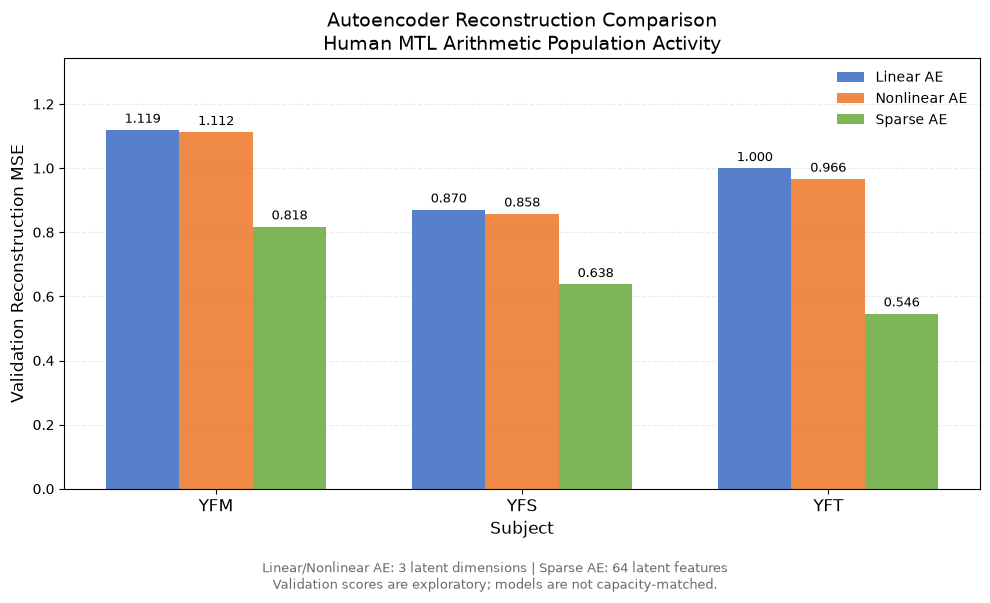


Comparison saved successfully.


In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Collect results from trained autoencoders
# --------------------------------------------------

comparison_rows = []

for subject in subjects:

    comparison_rows.extend([
        {
            "Subject": subject,
            "Model": "Linear AE",
            "Latent dimensions": 3,
            "Train MSE": linear_ae_results[subject]["ae_train_mse"],
            "Validation MSE": linear_ae_results[subject]["ae_val_mse"]
        },
        {
            "Subject": subject,
            "Model": "Nonlinear AE",
            "Latent dimensions": 3,
            "Train MSE": nonlinear_ae_results[subject]["train_mse"],
            "Validation MSE": nonlinear_ae_results[subject]["val_mse"]
        },
        {
            "Subject": subject,
            "Model": "Sparse AE",
            "Latent dimensions": 64,
            "Train MSE": sparse_ae_results[subject]["train_mse"],
            "Validation MSE": sparse_ae_results[subject]["val_mse"]
        }
    ])

ae_comparison_df = pd.DataFrame(comparison_rows)

display(ae_comparison_df.round(4))

# --------------------------------------------------
# 2. Plot validation reconstruction MSE
# --------------------------------------------------

subject_names = list(subjects)
models = ["Linear AE", "Nonlinear AE", "Sparse AE"]

colors = ["#4472C4", "#ED7D31", "#70AD47"]

x = np.arange(len(subject_names))
width = 0.24

fig, ax = plt.subplots(figsize=(10, 6))

for i, model_name in enumerate(models):

    values = [
        ae_comparison_df.loc[
            (ae_comparison_df["Subject"] == subject) &
            (ae_comparison_df["Model"] == model_name),
            "Validation MSE"
        ].iloc[0]
        for subject in subject_names
    ]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=model_name,
        color=colors[i],
        alpha=0.9
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(subject_names, fontsize=12)

ax.set_ylabel("Validation Reconstruction MSE", fontsize=12)
ax.set_xlabel("Subject", fontsize=12)

ax.set_title(
    "Autoencoder Reconstruction Comparison\n"
    "Human MTL Arithmetic Population Activity",
    fontsize=14
)

ax.legend(frameon=False)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.set_ylim(
    0,
    ae_comparison_df["Validation MSE"].max() * 1.2
)

fig.text(
    0.5, 0.01,
    "Linear/Nonlinear AE: 3 latent dimensions | "
    "Sparse AE: 64 latent features\n"
    "Validation scores are exploratory; "
    "models are not capacity-matched.",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

# --------------------------------------------------
# 3. Save figure
# --------------------------------------------------

plt.savefig(
    FIGURES / "arithmetic_autoencoder_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_autoencoder_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 4. Save comparison table
# --------------------------------------------------

ae_comparison_df.to_csv(
    TABLES / "arithmetic_autoencoder_comparison.csv",
    index=False
)

print("\nComparison saved successfully.")

,subject,model,latent_dimensions,affine_rank,participation_ratio,effective_rank,mean_centroid_distance,number_line_correlation
0,YFM,Linear AE,3,3,2.0750,2.2454,0.3569,-0.2125
1,YFM,Nonlinear AE,3,3,2.3400,2.5365,1.3086,-0.1885
2,YFM,Sparse AE,64,8,6.7065,7.3053,3.3790,0.0018
3,YFS,Linear AE,3,3,2.1642,2.4237,0.2942,-0.0405
4,YFS,Nonlinear AE,3,3,1.8483,2.2222,0.5993,0.0945
5,YFS,Sparse AE,64,8,7.1198,7.5154,1.9198,-0.0143
6,YFT,Linear AE,3,3,1.4341,1.7256,0.2441,-0.2527
7,YFT,Nonlinear AE,3,3,1.3498,1.6520,0.8039,-0.2106
8,YFT,Sparse AE,64,8,6.8906,7.3930,1.2387,-0.2883


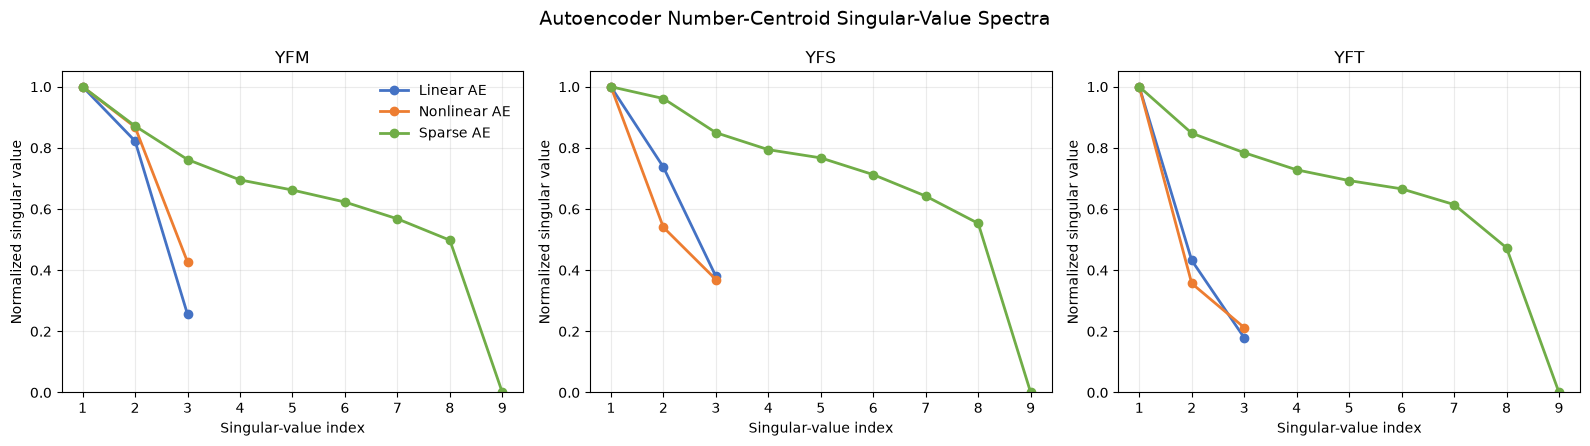

In [130]:
from scipy.spatial.distance import pdist
from scipy.stats import pearsonr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

geometry_rows = []
singular_rows = []

model_configs = {
    "Linear AE": linear_ae_results,
    "Nonlinear AE": nonlinear_ae_results,
    "Sparse AE": sparse_ae_results
}

for subject in subjects:

    # Original firing-rate population vectors
    X = (
        arithmetic_mtl_counts[subject] / 0.9
    ).astype(np.float32)

    y = arithmetic_presentations[subject]["number"].to_numpy()

    # Apply training-fitted standardization
    X_scaled = ae_data[subject]["scaler"].transform(
        X
    ).astype(np.float32)

    X_tensor = torch.from_numpy(X_scaled)

    for model_name, results in model_configs.items():

        model = results[subject]["model"]
        model.eval()

        # Extract latent representations
        with torch.no_grad():
            Z = model.encode(X_tensor).cpu().numpy()

        # Nine number centroids
        centroids = np.array([
            Z[y == number].mean(axis=0)
            for number in range(1, 10)
        ])

        # Center the centroid matrix
        C = centroids - centroids.mean(axis=0)

        # Singular value decomposition
        singular_values = np.linalg.svd(
            C, compute_uv=False
        )

        # Numerical affine rank
        rank = np.linalg.matrix_rank(C)

        # Eigenvalue-like variance contributions
        eigenvalues = singular_values ** 2

        if eigenvalues.sum() > 0:
            probabilities = eigenvalues / eigenvalues.sum()

            participation_ratio = (
                eigenvalues.sum() ** 2
                / np.sum(eigenvalues ** 2)
            )

            positive = probabilities[probabilities > 0]

            effective_rank = np.exp(
                -np.sum(positive * np.log(positive))
            )
        else:
            participation_ratio = np.nan
            effective_rank = np.nan

        # Distances between the nine centroids
        neural_distances = pdist(
            centroids, metric="euclidean"
        )

        numerical_distances = pdist(
            np.arange(1, 10).reshape(-1, 1),
            metric="cityblock"
        )

        mean_distance = neural_distances.mean()

        number_line_r, _ = pearsonr(
            numerical_distances,
            neural_distances
        )

        geometry_rows.append({
            "subject": subject,
            "model": model_name,
            "latent_dimensions": Z.shape[1],
            "affine_rank": rank,
            "participation_ratio": participation_ratio,
            "effective_rank": effective_rank,
            "mean_centroid_distance": mean_distance,
            "number_line_correlation": number_line_r
        })

        for k, value in enumerate(singular_values, start=1):
            singular_rows.append({
                "subject": subject,
                "model": model_name,
                "component": k,
                "singular_value": value
            })

# --------------------------------------------------
# Save summary tables
# --------------------------------------------------

ae_centroid_geometry_df = pd.DataFrame(geometry_rows)
ae_singular_values_df = pd.DataFrame(singular_rows)

display(ae_centroid_geometry_df.round(4))

ae_centroid_geometry_df.to_csv(
    TABLES / "arithmetic_AE_centroid_geometry.csv",
    index=False
)

ae_singular_values_df.to_csv(
    TABLES / "arithmetic_AE_centroid_singular_values.csv",
    index=False
)

# --------------------------------------------------
# Plot normalized singular-value spectra
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

colors = {
    "Linear AE": "#4472C4",
    "Nonlinear AE": "#ED7D31",
    "Sparse AE": "#70AD47"
}

for ax, subject in zip(axes, subjects):

    for model_name in model_configs:

        subset = ae_singular_values_df[
            (ae_singular_values_df["subject"] == subject)
            & (ae_singular_values_df["model"] == model_name)
        ].sort_values("component")

        values = subset["singular_value"].to_numpy()

        # Normalize to compare spectral shapes
        if values[0] > 0:
            values = values / values[0]

        ax.plot(
            subset["component"],
            values,
            marker="o",
            linewidth=2,
            label=model_name,
            color=colors[model_name]
        )

    ax.set_title(subject)
    ax.set_xlabel("Singular-value index")
    ax.set_ylabel("Normalized singular value")
    ax.set_xticks(range(1, 10))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)

axes[0].legend(frameon=False)

fig.suptitle(
    "Autoencoder Number-Centroid Singular-Value Spectra",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "arithmetic_AE_centroid_singular_spectra.png",
    dpi=300, bbox_inches="tight"
)

plt.savefig(
    FIGURES / "arithmetic_AE_centroid_singular_spectra.pdf",
    bbox_inches="tight"
)

plt.show()

The autoencoder models successfully reconstructed neural population activity with different levels of complexity. However, the dimensionality and geometry of their latent representations were strongly constrained by the chosen architectures. Although the sparse autoencoder produced higher-dimensional centroid configurations, none of the tested models demonstrated a clear numerical-distance relationship. These findings do not establish either a number-line or simplex representation.

----


# LDA

In [131]:
# LDA 

#LDA 


In [132]:
# LDA main analysis  

In [133]:

import numpy as np
import pandas as pd

print("ARITHMETIC DATA CHECK")
print("=" * 75)

for subject in ["YFM", "YFS", "YFT"]:
    counts = np.asarray(arithmetic_mtl_counts[subject])
    events = arithmetic_presentations[subject]

    print(f"\nSubject: {subject}")
    print(f"  Presentations: {len(events)}")
    print(f"  Neurons:       {counts.shape[1]}")
    print(f"  Count matrix:  {counts.shape}")
    print(f"  Event columns: {list(events.columns)}")
    print(f"  Numbers:       {sorted(events['number'].dropna().unique())}")
    print(f"  Unique trials: {events['trial'].nunique()}")
    print(f"  Onset missing: {events['onset'].isna().sum()}")

    assert counts.shape[0] == len(events), (
        f"{subject}: count/event mismatch"
    )
    assert events["number"].between(1, 9).all(), (
        f"{subject}: invalid number labels"
    )

print("\nData check completed.")


ARITHMETIC DATA CHECK

Subject: YFM
  Presentations: 114
  Neurons:       129
  Count matrix:  (114, 129)
  Event columns: ['trial', 'number', 'onset', 'operand']
  Numbers:       [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
  Unique trials: 78
  Onset missing: 0

Subject: YFS
  Presentations: 264
  Neurons:       144
  Count matrix:  (264, 144)
  Event columns: ['trial', 'number', 'onset', 'operand']
  Numbers:       [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
  Unique trials: 156
  Onset missing: 0

Subject: YFT
  Presentations: 477
  Neurons:       91
  Count matrix:  (477, 91)
  Event columns: ['trial', 'number', 'onset', 'operand']
  Numbers:       [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
  Unique trials: 290
  Onset missing: 0

Data check completed.


In [134]:

import h5py
from pathlib import Path

print("ORIGINAL SPIKE FILE INSPECTION")
print("=" * 75)

for subject, (filename, dataset_name) in subjects.items():

    print(f"\nSubject: {subject}")
    print(f"  File: {filename}")
    print(f"  Expected dataset: {dataset_name}")

    # Locate the original file within the repository
    matches = [
        p for p in Path(".").rglob(filename)
        if subject in str(p)
        and ".git" not in p.parts
    ]

    if not matches:
        print("  File not found from current directory.")
        continue

    path = matches[0]
    print(f"  Path: {path}")

    with h5py.File(path, "r") as f:

        def inspect(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(
                    f"  Dataset: {name} | "
                    f"shape={obj.shape} | "
                    f"dtype={obj.dtype}"
                )

        f.visititems(inspect)

print("\nInspection complete.")


ORIGINAL SPIKE FILE INSPECTION

Subject: YFM
  File: spikesArithmetic.mat
  Expected dataset: spikesArithmetic
  File not found from current directory.

Subject: YFS
  File: spikes.mat
  Expected dataset: spikes
  File not found from current directory.

Subject: YFT
  File: spikes.mat
  Expected dataset: spikes
  File not found from current directory.

Inspection complete.


In [135]:

from pathlib import Path
import os

print("CURRENT WORKING DIRECTORY")
print(Path.cwd())

print("\nSEARCHING FOR SPIKE FILES")
print("=" * 70)

cwd = Path.cwd()

search_roots = [
    cwd,
    cwd.parent,
    cwd.parent.parent,
    Path.home() / "Downloads",
    Path.home() / "Documents",
    Path.home() / "Desktop"
]

# Remove duplicate locations
search_roots = list(dict.fromkeys(
    p.resolve() for p in search_roots if p.exists()
))

found_files = []

for root in search_roots:
    print(f"\nChecking: {root}")

    for folder, dirs, files in os.walk(root):
        # Skip large/unrelated folders
        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git", ".venv", "venv",
                "node_modules", "__pycache__"
            }
        ]

        for filename in files:
            if filename in {"spikesArithmetic.mat", "spikes.mat"}:
                path = Path(folder) / filename
                found_files.append(path)
                print(f"  FOUND: {path}")

print("\n" + "=" * 70)
print(f"Total matching files: {len(found_files)}")

if not found_files:
    print("No matching files found in the searched locations.")


CURRENT WORKING DIRECTORY
c:\Users\shafi\number-simplex-reproduction\notebooks2

SEARCHING FOR SPIKE FILES

Checking: C:\Users\shafi\number-simplex-reproduction\notebooks2

Checking: C:\Users\shafi\number-simplex-reproduction
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\YFF\arithmetic\spikes.mat
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\YFI\arithmetic\spikes.mat
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\YFI\dot\spikes.mat
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\YFJ\arithmetic\spikes.mat
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\YFJ\dot\spikes.mat
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\YFK\arithmetic\spikesArithmetic.mat
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\YFL\arithmetic\spikesArithmetic.mat
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\YFM\arithmetic\spikesArithmetic.mat
  FOUND: C:\Users\shafi\number-simplex-reproduction\data\raw\Y

In [136]:

import h5py
from pathlib import Path

ROOT = Path.cwd().parent
DATA = ROOT / "data" / "sorted_data"

spike_paths = {
    "YFM": DATA / "YFM" / "arithmetic" / "spikesArithmetic.mat",
    "YFS": DATA / "YFS" / "arithmetic" / "spikes.mat",
    "YFT": DATA / "YFT" / "arithmetic" / "spikes.mat"
}

print("SORTED SPIKE MATRIX INSPECTION")
print("=" * 75)

for subject, path in spike_paths.items():
    print(f"\n{subject}")
    print(f"File exists: {path.exists()}")
    print(f"Path: {path}")

    with h5py.File(path, "r") as f:
        def inspect(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(
                    f"  {name}: "
                    f"shape={obj.shape}, "
                    f"dtype={obj.dtype}"
                )

        f.visititems(inspect)

print("\nInspection complete.")


SORTED SPIKE MATRIX INSPECTION

YFM
File exists: True
Path: c:\Users\shafi\number-simplex-reproduction\data\sorted_data\YFM\arithmetic\spikesArithmetic.mat
  #refs#/0: shape=(3, 1), dtype=uint16
  #refs#/0b: shape=(3, 1), dtype=uint16
  #refs#/0c: shape=(3, 1), dtype=uint16
  #refs#/0d: shape=(14, 1), dtype=uint16
  #refs#/0e: shape=(15, 1), dtype=uint16
  #refs#/0f: shape=(16, 1), dtype=uint16
  #refs#/1: shape=(4, 1), dtype=uint16
  #refs#/1b: shape=(3, 1), dtype=uint16
  #refs#/1c: shape=(3, 1), dtype=uint16
  #refs#/1d: shape=(15, 1), dtype=uint16
  #refs#/1e: shape=(15, 1), dtype=uint16
  #refs#/1f: shape=(16, 1), dtype=uint16
  #refs#/2: shape=(4, 1), dtype=uint16
  #refs#/2b: shape=(3, 1), dtype=uint16
  #refs#/2c: shape=(3, 1), dtype=uint16
  #refs#/2d: shape=(15, 1), dtype=uint16
  #refs#/2e: shape=(15, 1), dtype=uint16
  #refs#/2f: shape=(16, 1), dtype=uint16
  #refs#/3: shape=(4, 1), dtype=uint16
  #refs#/3b: shape=(3, 1), dtype=uint16
  #refs#/3c: shape=(3, 1), dtype=uint16

In [137]:

import h5py
import numpy as np

print("MAIN SPIKE MATRIX STRUCTURE")
print("=" * 75)

for subject, path in spike_paths.items():

    print(f"\n{subject}")
    print("-" * 50)

    with h5py.File(path, "r") as f:

        # Show top-level objects, excluding MATLAB references
        print("Top-level keys:",
              [k for k in f.keys() if k != "#refs#"])

        for name in [k for k in f.keys() if k != "#refs#"]:
            obj = f[name]

            print(f"\n  Object: {name}")
            print(f"  Type: {type(obj).__name__}")

            if isinstance(obj, h5py.Group):

                print("  Members:", list(obj.keys()))
                print("  Attributes:", dict(obj.attrs))

                if all(k in obj for k in ["data", "ir", "jc"]):

                    n_nonzero = len(obj["data"])
                    n_columns = len(obj["jc"]) - 1

                    ir = obj["ir"][:]
                    n_rows_min = (
                        int(ir.max()) + 1 if len(ir) else 0
                    )

                    print(f"  Nonzero entries: {n_nonzero:,}")
                    print(f"  Columns:         {n_columns:,}")
                    print(f"  Minimum rows:    {n_rows_min}")

            elif isinstance(obj, h5py.Dataset):
                print("  Shape:", obj.shape)
                print("  Dtype:", obj.dtype)
                print("  Attributes:", dict(obj.attrs))

    print(
        f"\n  Expected neurons: "
        f"{arithmetic_mtl_counts[subject].shape[1]}"
    )

print("\nInspection complete.")


MAIN SPIKE MATRIX STRUCTURE

YFM
--------------------------------------------------
Top-level keys: ['electrodesVect', 'exportInfo', 'isSingleUnit', 'isiIntervalCount', 'isiViolationCount3ms', 'isiViolationPct3ms', 'regionsVect', 'sourceUnitIndex', 'spikesArithmetic']

  Object: electrodesVect
  Type: Dataset
  Shape: (1, 198)
  Dtype: object
  Attributes: {'MATLAB_class': np.bytes_(b'cell')}

  Object: exportInfo
  Type: Group
  Members: ['appendedZeroBins', 'behaviorTiming', 'binSizeMs', 'clock', 'createdDate', 'isiScope', 'nBins', 'nUnits', 'schemaVersion', 'singleUnitDefinition', 'sorting', 'sourceColumnFirst', 'sourceColumnLast', 'sourceColumnMapping', 'sourceColumnOffsetMs', 'sourceFilename', 'sourceSHA256', 'spikeVariable', 'subject', 'task', 'unitIdentity', 'unitSelection']
  Attributes: {'MATLAB_class': np.bytes_(b'struct'), 'MATLAB_fields': array([array([b's', b'c', b'h', b'e', b'm', b'a', b'V', b'e', b'r', b's', b'i',
              b'o', b'n'], dtype='|S1')                  

  Nonzero entries: 368,177
  Columns:         808,864
  Minimum rows:    198

  Expected neurons: 129

YFS
--------------------------------------------------
Top-level keys: ['electrodesVect', 'exportInfo', 'isSingleUnit', 'isiIntervalCount', 'isiViolationCount3ms', 'isiViolationPct3ms', 'regionsVect', 'sourceUnitIndex', 'spikes']

  Object: electrodesVect
  Type: Dataset
  Shape: (1, 244)
  Dtype: object
  Attributes: {'MATLAB_class': np.bytes_(b'cell')}

  Object: exportInfo
  Type: Group
  Members: ['appendedZeroBins', 'behaviorTiming', 'binSizeMs', 'clock', 'createdDate', 'isiScope', 'nBins', 'nUnits', 'schemaVersion', 'singleUnitDefinition', 'sorting', 'sourceColumnFirst', 'sourceColumnLast', 'sourceColumnMapping', 'sourceColumnOffsetMs', 'sourceFilename', 'sourceSHA256', 'spikeVariable', 'subject', 'task', 'unitIdentity', 'unitSelection']
  Attributes: {'MATLAB_class': np.bytes_(b'struct'), 'MATLAB_fields': array([array([b's', b'c', b'h', b'e', b'm', b'a', b'V', b'e', b'r', b's',

In [138]:

import h5py
import numpy as np

print("SPIKE TIMING AND NEURON METADATA")
print("=" * 75)

for subject, path in spike_paths.items():

    with h5py.File(path, "r") as f:

        spike_name = subjects[subject][1]
        spike_group = f[spike_name]
        info = f["exportInfo"]

        n_units = int(spike_group.attrs["MATLAB_sparse"])
        n_timebins = len(spike_group["jc"]) - 1

        print(f"\n{subject}")
        print("-" * 50)

        print("Total recorded units:", n_units)
        print(
            "Previously selected MTL neurons:",
            arithmetic_mtl_counts[subject].shape[1]
        )
        print("Total recording time bins:", n_timebins)

        for key in [
            "binSizeMs",
            "nBins",
            "nUnits",
            "sourceColumnOffsetMs",
            "sourceColumnFirst",
            "sourceColumnLast",
            "appendedZeroBins"
        ]:
            if key in info:
                value = np.asarray(info[key]).ravel()
                print(f"{key}: {value[:10]}")

        if "sourceUnitIndex" in f:
            indices = np.asarray(
                f["sourceUnitIndex"]
            ).ravel()

            print(
                "Source unit indices (first 15):",
                indices[:15]
            )

print("\nMetadata inspection complete.")


SPIKE TIMING AND NEURON METADATA

YFM
--------------------------------------------------
Total recorded units: 198
Previously selected MTL neurons: 129
Total recording time bins: 808864
binSizeMs: [1.]
nBins: [808864.]
nUnits: [198.]
sourceColumnOffsetMs: [0.]
sourceColumnFirst: [1.]
sourceColumnLast: [808864.]
appendedZeroBins: [0.]
Source unit indices (first 15): [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]

YFS
--------------------------------------------------
Total recorded units: 244
Previously selected MTL neurons: 144
Total recording time bins: 2215514
binSizeMs: [1.]
nBins: [2215514.]
nUnits: [244.]
sourceColumnOffsetMs: [0.]
sourceColumnFirst: [1.]
sourceColumnLast: [2215514.]
appendedZeroBins: [0.]
Source unit indices (first 15): [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]

YFT
--------------------------------------------------
Total recorded units: 174
Previously selected MTL neurons: 91
Total recording time bins: 3167227
binSizeMs: [1.]
nBins: [3167227.]
nUnits: [174.

In [139]:

import numpy as np
import h5py

print("MTL SELECTION AND ONSET ALIGNMENT")
print("=" * 75)

for subject, path in spike_paths.items():

    events = arithmetic_presentations[subject]
    onsets = events["onset"].to_numpy(dtype=float)

    with h5py.File(path, "r") as f:
        n_units = int(f[subjects[subject][1]].attrs["MATLAB_sparse"])
        n_bins = len(f[subjects[subject][1]]["jc"]) - 1

        print(f"\n{subject}")
        print("-" * 50)

        print("Recorded units:", n_units)
        print("Selected MTL units:",
              arithmetic_mtl_counts[subject].shape[1])

        print("Onset minimum:", onsets.min())
        print("Onset maximum:", onsets.max())
        print("Onset median:", np.median(onsets))

        print("Recording duration (seconds):", n_bins / 1000)

        # Compare possible timestamp units
        for scale, label in [
            (1, "milliseconds"),
            (1000, "seconds")
        ]:
            starts = np.rint(onsets * scale + 50).astype(np.int64)
            ends = starts + 900

            valid = (
                (starts >= 0) &
                (ends <= n_bins)
            )

            print(
                f"Onsets interpreted as {label}: "
                f"{valid.sum()}/{len(valid)} windows in bounds"
            )

        print("\nPotential MTL-selection variables:")

        for name in sorted(globals()):
            if any(term in name.lower() for term in [
                "mtl", "region", "mask", "unit_idx",
                "neuron_idx", "selected_neuron"
            ]) and not name.startswith("_"):
                obj = globals()[name]
                if isinstance(obj, dict):
                    if subject in obj:
                        value = obj[subject]
                        print(
                            f"  {name}[{subject}]: "
                            f"type={type(value).__name__}, "
                            f"shape={np.shape(value)}"
                        )

print("\nInspection complete.")


MTL SELECTION AND ONSET ALIGNMENT

YFM
--------------------------------------------------
Recorded units: 198
Selected MTL units: 129
Onset minimum: 137055.7
Onset maximum: 802578.366666667
Onset median: 466025.45
Recording duration (seconds): 808.864
Onsets interpreted as milliseconds: 114/114 windows in bounds
Onsets interpreted as seconds: 0/114 windows in bounds

Potential MTL-selection variables:
  arithmetic_mtl_counts[YFM]: type=ndarray, shape=(114, 129)
  mtl_indices[YFM]: type=ndarray, shape=(129,)
  mtl_single_unit_indices[YFM]: type=ndarray, shape=(118,)

YFS
--------------------------------------------------
Recorded units: 244
Selected MTL units: 144
Onset minimum: 16352.2
Onset maximum: 789906.166666667
Onset median: 396187.65
Recording duration (seconds): 2215.514
Onsets interpreted as milliseconds: 264/264 windows in bounds
Onsets interpreted as seconds: 0/264 windows in bounds

Potential MTL-selection variables:
  arithmetic_mtl_counts[YFS]: type=ndarray, shape=(264, 1

In [140]:

import numpy as np
import h5py

print("MTL SELECTION AND ONSET ALIGNMENT")
print("=" * 75)

for subject, path in spike_paths.items():

    events = arithmetic_presentations[subject]
    onsets = events["onset"].to_numpy(dtype=float)

    with h5py.File(path, "r") as f:
        n_units = int(f[subjects[subject][1]].attrs["MATLAB_sparse"])
        n_bins = len(f[subjects[subject][1]]["jc"]) - 1

        print(f"\n{subject}")
        print("-" * 50)

        print("Recorded units:", n_units)
        print("Selected MTL units:",
              arithmetic_mtl_counts[subject].shape[1])

        print("Onset minimum:", onsets.min())
        print("Onset maximum:", onsets.max())
        print("Onset median:", np.median(onsets))

        print("Recording duration (seconds):", n_bins / 1000)

        # Compare possible timestamp units
        for scale, label in [
            (1, "milliseconds"),
            (1000, "seconds")
        ]:
            starts = np.rint(onsets * scale + 50).astype(np.int64)
            ends = starts + 900

            valid = (
                (starts >= 0) &
                (ends <= n_bins)
            )

            print(
                f"Onsets interpreted as {label}: "
                f"{valid.sum()}/{len(valid)} windows in bounds"
            )

        print("\nPotential MTL-selection variables:")

        for name in sorted(globals()):
            if any(term in name.lower() for term in [
                "mtl", "region", "mask", "unit_idx",
                "neuron_idx", "selected_neuron"
            ]) and not name.startswith("_"):
                obj = globals()[name]
                if isinstance(obj, dict):
                    if subject in obj:
                        value = obj[subject]
                        print(
                            f"  {name}[{subject}]: "
                            f"type={type(value).__name__}, "
                            f"shape={np.shape(value)}"
                        )

print("\nInspection complete.")


MTL SELECTION AND ONSET ALIGNMENT

YFM
--------------------------------------------------
Recorded units: 198
Selected MTL units: 129
Onset minimum: 137055.7
Onset maximum: 802578.366666667
Onset median: 466025.45
Recording duration (seconds): 808.864
Onsets interpreted as milliseconds: 114/114 windows in bounds
Onsets interpreted as seconds: 0/114 windows in bounds

Potential MTL-selection variables:
  arithmetic_mtl_counts[YFM]: type=ndarray, shape=(114, 129)
  mtl_indices[YFM]: type=ndarray, shape=(129,)
  mtl_single_unit_indices[YFM]: type=ndarray, shape=(118,)

YFS
--------------------------------------------------
Recorded units: 244
Selected MTL units: 144
Onset minimum: 16352.2
Onset maximum: 789906.166666667
Onset median: 396187.65
Recording duration (seconds): 2215.514
Onsets interpreted as milliseconds: 264/264 windows in bounds
Onsets interpreted as seconds: 0/264 windows in bounds

Potential MTL-selection variables:
  arithmetic_mtl_counts[YFS]: type=ndarray, shape=(264, 1

In [141]:

import numpy as np

print("MTL NEURON INDEX VALIDATION")
print("=" * 70)

for subject, path in spike_paths.items():

    indices = np.asarray(mtl_indices[subject]).ravel()
    single_indices = np.asarray(
        mtl_single_unit_indices[subject]
    ).ravel()

    with h5py.File(path, "r") as f:
        n_units = int(
            f[subjects[subject][1]].attrs["MATLAB_sparse"]
        )

    print(f"\n{subject}")
    print("-" * 45)

    print("Total recorded units:", n_units)
    print("MTL neurons:", len(indices))
    print("Single-unit MTL neurons:", len(single_indices))

    print("MTL index minimum:", indices.min())
    print("MTL index maximum:", indices.max())
    print("First 15 MTL indices:", indices[:15])

    print("Unique indices:", len(np.unique(indices)))
    print("All indices valid for Python:",
          np.all((indices >= 0) & (indices < n_units)))

    print("All indices valid for MATLAB:",
          np.all((indices >= 1) & (indices <= n_units)))

    print("Indices sorted:",
          np.all(np.diff(indices) >= 0))

print("\nValidation complete.")


MTL NEURON INDEX VALIDATION

YFM
---------------------------------------------
Total recorded units: 198
MTL neurons: 129
Single-unit MTL neurons: 118
MTL index minimum: 0
MTL index maximum: 172
First 15 MTL indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Unique indices: 129
All indices valid for Python: True
All indices valid for MATLAB: False
Indices sorted: True

YFS
---------------------------------------------
Total recorded units: 244
MTL neurons: 144
Single-unit MTL neurons: 107
MTL index minimum: 66
MTL index maximum: 243
First 15 MTL indices: [66 67 68 69 70 71 72 73 74 75 76 77 78 79 80]
Unique indices: 144
All indices valid for Python: True
All indices valid for MATLAB: True
Indices sorted: True

YFT
---------------------------------------------
Total recorded units: 174
MTL neurons: 91
Single-unit MTL neurons: 78
MTL index minimum: 16
MTL index maximum: 134
First 15 MTL indices: [16 17 18 19 20 21 22 23 24 25 26 27 28 29 30]
Unique indices: 91
All indices valid for 

In [142]:

import numpy as np

print("MTL NEURON INDEX VALIDATION")
print("=" * 70)

for subject, path in spike_paths.items():

    indices = np.asarray(mtl_indices[subject]).ravel()
    single_indices = np.asarray(
        mtl_single_unit_indices[subject]
    ).ravel()

    with h5py.File(path, "r") as f:
        n_units = int(
            f[subjects[subject][1]].attrs["MATLAB_sparse"]
        )

    print(f"\n{subject}")
    print("-" * 45)

    print("Total recorded units:", n_units)
    print("MTL neurons:", len(indices))
    print("Single-unit MTL neurons:", len(single_indices))

    print("MTL index minimum:", indices.min())
    print("MTL index maximum:", indices.max())
    print("First 15 MTL indices:", indices[:15])

    print("Unique indices:", len(np.unique(indices)))
    print("All indices valid for Python:",
          np.all((indices >= 0) & (indices < n_units)))

    print("All indices valid for MATLAB:",
          np.all((indices >= 1) & (indices <= n_units)))

    print("Indices sorted:",
          np.all(np.diff(indices) >= 0))

print("\nValidation complete.")


MTL NEURON INDEX VALIDATION

YFM
---------------------------------------------
Total recorded units: 198
MTL neurons: 129
Single-unit MTL neurons: 118
MTL index minimum: 0
MTL index maximum: 172
First 15 MTL indices: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Unique indices: 129
All indices valid for Python: True
All indices valid for MATLAB: False
Indices sorted: True

YFS
---------------------------------------------
Total recorded units: 244
MTL neurons: 144
Single-unit MTL neurons: 107
MTL index minimum: 66
MTL index maximum: 243
First 15 MTL indices: [66 67 68 69 70 71 72 73 74 75 76 77 78 79 80]
Unique indices: 144
All indices valid for Python: True
All indices valid for MATLAB: True
Indices sorted: True

YFT
---------------------------------------------
Total recorded units: 174
MTL neurons: 91
Single-unit MTL neurons: 78
MTL index minimum: 16
MTL index maximum: 134
First 15 MTL indices: [16 17 18 19 20 21 22 23 24 25 26 27 28 29 30]
Unique indices: 91
All indices valid for 

In [143]:

import numpy as np
import h5py
from scipy.sparse import csc_matrix

print("SPARSE MATRIX RECONSTRUCTION AND VALIDATION")
print("=" * 75)

spike_matrices_mtl = {}

for subject, path in spike_paths.items():

    with h5py.File(path, "r") as f:
        group = f[subjects[subject][1]]

        data = group["data"][:]
        ir = group["ir"][:].astype(np.int64)
        jc = group["jc"][:].astype(np.int64)

        n_units = int(group.attrs["MATLAB_sparse"])
        n_bins = len(jc) - 1

    S = csc_matrix(
        (data, ir, jc),
        shape=(n_units, n_bins)
    )

    # Preserve original MTL neuron ordering
    indices = np.asarray(
        mtl_indices[subject], dtype=int
    )

    S_mtl = S[indices, :].tocsr()
    spike_matrices_mtl[subject] = S_mtl

    events = arithmetic_presentations[subject]
    onsets = events["onset"].to_numpy(dtype=float)

    starts = np.rint(onsets + 50).astype(int)
    ends = starts + 900

    extracted = np.stack([
        np.asarray(
            S_mtl[:, start:end].sum(axis=1)
        ).ravel()
        for start, end in zip(starts, ends)
    ])

    original = np.asarray(
        arithmetic_mtl_counts[subject]
    )

    difference = extracted - original

    print(f"\n{subject}")
    print("-" * 50)
    print("Sparse matrix shape:", S_mtl.shape)
    print("Extracted counts shape:", extracted.shape)
    print("Original counts shape:", original.shape)

    print("Extracted total spikes:", extracted.sum())
    print("Original total spikes:", original.sum())

    print("Maximum absolute difference:",
          np.max(np.abs(difference)))

    print("Mismatched entries:",
          np.count_nonzero(difference))

    print("Exact match:",
          np.array_equal(extracted, original))

print("\nValidation complete.")


SPARSE MATRIX RECONSTRUCTION AND VALIDATION

YFM
--------------------------------------------------
Sparse matrix shape: (129, 808864)
Extracted counts shape: (114, 129)
Original counts shape: (114, 129)
Extracted total spikes: 31926
Original total spikes: 31928
Maximum absolute difference: 1.0
Mismatched entries: 34
Exact match: False

YFS
--------------------------------------------------
Sparse matrix shape: (144, 2215514)
Extracted counts shape: (264, 144)
Original counts shape: (264, 144)
Extracted total spikes: 46443
Original total spikes: 46442
Maximum absolute difference: 1.0
Mismatched entries: 53
Exact match: False

YFT
--------------------------------------------------
Sparse matrix shape: (91, 3167227)
Extracted counts shape: (477, 91)
Original counts shape: (477, 91)
Extracted total spikes: 82465
Original total spikes: 82456
Maximum absolute difference: 1.0
Mismatched entries: 87
Exact match: False

Validation complete.


In [144]:
starts = np.rint(onsets + 50).astype(int)

In [145]:

import numpy as np

print("TIMESTAMP ROUNDING VALIDATION")
print("=" * 75)

rounding_methods = {
    "floor": np.floor,
    "round": np.rint,
    "ceil": np.ceil
}

for subject in ["YFM", "YFS", "YFT"]:

    S = spike_matrices_mtl[subject]
    onsets = arithmetic_presentations[subject][
        "onset"
    ].to_numpy(dtype=float)

    original = np.asarray(
        arithmetic_mtl_counts[subject]
    )

    print(f"\n{subject}")
    print("-" * 60)

    results = []

    for method_name, method in rounding_methods.items():

        for offset in [-1, 0, 1]:

            starts = method(onsets + 50).astype(int) + offset
            ends = starts + 900

            if np.any(starts < 0) or np.any(ends > S.shape[1]):
                continue

            extracted = np.stack([
                np.asarray(
                    S[:, start:end].sum(axis=1)
                ).ravel()
                for start, end in zip(starts, ends)
            ])

            difference = extracted - original

            mismatches = np.count_nonzero(difference)
            total_difference = int(difference.sum())

            results.append((
                mismatches,
                method_name,
                offset,
                total_difference
            ))

    results.sort()

    print("Best timestamp conventions:")
    print(
        f"{'Method':<12}"
        f"{'Offset':<10}"
        f"{'Mismatches':<15}"
        f"{'Spike difference'}"
    )

    for mismatches, method, offset, total_diff in results[:6]:
        print(
            f"{method:<12}"
            f"{offset:<10}"
            f"{mismatches:<15}"
            f"{total_diff}"
        )

    best = results[0]

    print(
        "\nBest exact match:",
        best[0] == 0
    )

print("\nRounding comparison complete.")


TIMESTAMP ROUNDING VALIDATION

YFM
------------------------------------------------------------
Best timestamp conventions:
Method      Offset    Mismatches     Spike difference
floor       0         0              0
ceil        -1        5              3
round       0         34             -2
round       -1        47             5
ceil        0         60             2
floor       -1        69             -1

Best exact match: True

YFS
------------------------------------------------------------
Best timestamp conventions:
Method      Offset    Mismatches     Spike difference
floor       0         0              0
ceil        -1        3              1
round       -1        52             4
round       0         53             1
ceil        0         101            3
floor       1         103            3

Best exact match: True

YFT
------------------------------------------------------------
Best timestamp conventions:
Method      Offset    Mismatches     Spike difference
floor   

In [146]:

import numpy as np

print("EXTRACTING 100 MS TEMPORAL SPIKE COUNTS")
print("=" * 75)

temporal_counts_100ms = {}

for subject in ["YFM", "YFS", "YFT"]:

    S = spike_matrices_mtl[subject]

    onsets = arithmetic_presentations[subject][
        "onset"
    ].to_numpy(dtype=float)

    starts = np.floor(onsets + 50).astype(int)

    n_presentations = len(starts)
    n_neurons = S.shape[0]
    n_bins = 9
    bin_width = 100

    X = np.zeros(
        (n_presentations, n_neurons, n_bins),
        dtype=np.int32
    )

    for i, start in enumerate(starts):

        for b in range(n_bins):

            left = start + b * bin_width
            right = left + bin_width

            X[i, :, b] = np.asarray(
                S[:, left:right].sum(axis=1)
            ).ravel()

    temporal_counts_100ms[subject] = X

    # Reconstruct original 900 ms counts
    reconstructed = X.sum(axis=2)

    original = np.asarray(
        arithmetic_mtl_counts[subject]
    )

    print(f"\n{subject}")
    print("-" * 50)

    print("Temporal matrix shape:", X.shape)
    print("Total spikes:", X.sum())

    print(
        "Maximum absolute difference:",
        np.max(np.abs(reconstructed - original))
    )

    print(
        "Exact reconstruction:",
        np.array_equal(reconstructed, original)
    )

    print(
        "Mean spikes per 100 ms bin:",
        np.round(X.mean(axis=(0, 1)), 4)
    )

print("\nTemporal extraction complete.")


EXTRACTING 100 MS TEMPORAL SPIKE COUNTS

YFM
--------------------------------------------------
Temporal matrix shape: (114, 129, 9)
Total spikes: 31928
Maximum absolute difference: 0
Exact reconstruction: True
Mean spikes per 100 ms bin: [0.2463 0.2498 0.2568 0.2391 0.2293 0.2356 0.24   0.2353 0.239 ]

YFS
--------------------------------------------------
Temporal matrix shape: (264, 144, 9)
Total spikes: 46442
Maximum absolute difference: 0
Exact reconstruction: True
Mean spikes per 100 ms bin: [0.1349 0.1336 0.1235 0.1328 0.1412 0.1398 0.1433 0.1353 0.1373]

YFT
--------------------------------------------------
Temporal matrix shape: (477, 91, 9)
Total spikes: 82456
Maximum absolute difference: 0
Exact reconstruction: True
Mean spikes per 100 ms bin: [0.2115 0.211  0.21   0.2064 0.2104 0.2111 0.2102 0.2112 0.2179]

Temporal extraction complete.


Excellent. Our temporal spike extraction is now fully validated for all three subjects.
Subject	Temporal matrix	Total spikes	Reconstruction
YFM	114 × 129 × 9	31,928	Exact
YFS	264 × 144 × 9	46,442	Exact
YFT	477 × 91 × 9	82,456	Exact

In [147]:

import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

subject = "YFM"
neuron_idx = 0

X = temporal_counts_100ms[subject][:, neuron_idx, :]
y = arithmetic_presentations[subject]["number"].to_numpy(dtype=int)

n_splits = min(10, np.bincount(y, minlength=10)[1:].min())

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

predictions = np.full(len(y), -1, dtype=int)

for train_idx, test_idx in cv.split(X, y):

    X_train = X[train_idx]
    X_test = X[test_idx]

    # Remove features with zero within-class variance
    # using training data only.
    within_variance = np.zeros(X.shape[1])

    for number in np.unique(y[train_idx]):
        class_X = X_train[y[train_idx] == number]
        within_variance += (
            class_X.var(axis=0) * len(class_X)
        )

    keep = within_variance > 0

    if not np.any(keep):
        # No usable temporal features: predict a fixed class.
        predictions[test_idx] = 1
        continue

    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage=0.5,
        priors=np.ones(9) / 9
    )

    lda.fit(X_train[:, keep], y[train_idx])

    predictions[test_idx] = lda.predict(
        X_test[:, keep]
    )

accuracy = accuracy_score(y, predictions)

print("SINGLE-NEURON TEMPORAL LDA")
print("=" * 55)
print("Subject:", subject)
print("Neuron index:", neuron_idx)
print("Feature matrix:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("CV folds:", n_splits)
print("Shrinkage:", 0.5)
print("Accuracy:", round(accuracy, 4))
print("Chance accuracy:", round(1 / 9, 4))
print("Correct predictions:", np.sum(predictions == y))
print("Total presentations:", len(y))


SINGLE-NEURON TEMPORAL LDA
Subject: YFM
Neuron index: 0
Feature matrix: (114, 9)
Number of classes: 9
CV folds: 4
Shrinkage: 0.5
Accuracy: 0.1491
Chance accuracy: 0.1111
Correct predictions: 17
Total presentations: 114


In [148]:

import numpy as np
import pandas as pd

print("CLASS BALANCE AND TRIAL DEPENDENCE")
print("=" * 70)

for subject in ["YFM", "YFS", "YFT"]:

    events = arithmetic_presentations[subject]

    print(f"\n{subject}")
    print("-" * 50)

    print("Presentations:", len(events))
    print("Unique trials:", events["trial"].nunique())

    print("\nPresentations per number:")
    print(
        events["number"]
        .value_counts()
        .sort_index()
        .to_string()
    )

    trial_sizes = events.groupby("trial").size()

    print("\nPresentations per trial:")
    print(trial_sizes.value_counts().sort_index().to_string())

    print(
        "\nTrials with multiple presentations:",
        int((trial_sizes > 1).sum())
    )

    print(
        "Maximum presentations in one trial:",
        int(trial_sizes.max())
    )

print("\nInspection complete.")



CLASS BALANCE AND TRIAL DEPENDENCE

YFM
--------------------------------------------------
Presentations: 114
Unique trials: 78

Presentations per number:
number
1    19
2    17
3    14
4     4
5    14
6    16
7    10
8    12
9     8

Presentations per trial:
1    42
2    36

Trials with multiple presentations: 36
Maximum presentations in one trial: 2

YFS
--------------------------------------------------
Presentations: 264
Unique trials: 156

Presentations per number:
number
1    32
2    33
3    24
4    33
5    32
6    24
7    27
8    30
9    29

Presentations per trial:
1     48
2    108

Trials with multiple presentations: 108
Maximum presentations in one trial: 2

YFT
--------------------------------------------------
Presentations: 477
Unique trials: 290

Presentations per number:
number
1    62
2    48
3    52
4    57
5    53
6    56
7    43
8    50
9    56

Presentations per trial:
1    103
2    187

Trials with multiple presentations: 187
Maximum presentations in one trial: 2


In [149]:

import numpy as np

BIN_SIZES = [60, 75, 90, 100, 150, 180, 225, 300, 450, 900]
GAMMAS = [0.2, 0.5, 0.8]

temporal_counts_all = {}

print("EXTRACTING ALL TEMPORAL BIN CONFIGURATIONS")
print("=" * 75)

for subject in ["YFM", "YFS", "YFT"]:

    S = spike_matrices_mtl[subject]

    onsets = arithmetic_presentations[subject][
        "onset"
    ].to_numpy(dtype=float)

    starts = np.floor(onsets + 50).astype(int)

    temporal_counts_all[subject] = {}

    print(f"\n{subject}")
    print("-" * 55)

    for bin_size in BIN_SIZES:

        n_bins = 900 // bin_size

        X = np.zeros(
            (len(starts), S.shape[0], n_bins),
            dtype=np.int32
        )

        for i, start in enumerate(starts):

            for b in range(n_bins):

                left = start + b * bin_size
                right = left + bin_size

                X[i, :, b] = np.asarray(
                    S[:, left:right].sum(axis=1)
                ).ravel()

        temporal_counts_all[subject][bin_size] = X

        original = np.asarray(
            arithmetic_mtl_counts[subject]
        )

        exact = np.array_equal(
            X.sum(axis=2), original
        )

        print(
            f"{bin_size:>3} ms | "
            f"{n_bins:>2} bins | "
            f"shape={str(X.shape):<16} | "
            f"exact={exact}"
        )

        assert exact, (
            f"Reconstruction failed: "
            f"{subject}, {bin_size} ms"
        )

print("\nAll temporal configurations validated.")


EXTRACTING ALL TEMPORAL BIN CONFIGURATIONS

YFM
-------------------------------------------------------
 60 ms | 15 bins | shape=(114, 129, 15)   | exact=True
 75 ms | 12 bins | shape=(114, 129, 12)   | exact=True
 90 ms | 10 bins | shape=(114, 129, 10)   | exact=True
100 ms |  9 bins | shape=(114, 129, 9)    | exact=True
150 ms |  6 bins | shape=(114, 129, 6)    | exact=True
180 ms |  5 bins | shape=(114, 129, 5)    | exact=True
225 ms |  4 bins | shape=(114, 129, 4)    | exact=True
300 ms |  3 bins | shape=(114, 129, 3)    | exact=True
450 ms |  2 bins | shape=(114, 129, 2)    | exact=True
900 ms |  1 bins | shape=(114, 129, 1)    | exact=True

YFS
-------------------------------------------------------
 60 ms | 15 bins | shape=(264, 144, 15)   | exact=True
 75 ms | 12 bins | shape=(264, 144, 12)   | exact=True
 90 ms | 10 bins | shape=(264, 144, 10)   | exact=True
100 ms |  9 bins | shape=(264, 144, 9)    | exact=True
150 ms |  6 bins | shape=(264, 144, 6)    | exact=True
180 ms |  

In [150]:

import numpy as np
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

subject = "YFM"
neuron_idx = 0

y = arithmetic_presentations[subject]["number"].to_numpy(dtype=int)
n_splits = min(10, np.unique(y, return_counts=True)[1].min())

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(np.zeros(len(y)), y))
results = []

for bin_size in BIN_SIZES:

    X = temporal_counts_all[subject][bin_size][:, neuron_idx, :]

    for gamma in GAMMAS:

        predictions = np.full(len(y), -1, dtype=int)

        for train_idx, test_idx in folds:

            X_train = X[train_idx]
            X_test = X[test_idx]
            y_train = y[train_idx]

            # Training-only within-class variance filter
            within_variance = np.zeros(X.shape[1])

            for number in np.unique(y_train):
                class_X = X_train[y_train == number]
                within_variance += (
                    class_X.var(axis=0) * len(class_X)
                )

            keep = within_variance > 0

            if not np.any(keep):
                predictions[test_idx] = 1
                continue

            lda = LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage=gamma,
                priors=np.ones(9) / 9
            )

            lda.fit(X_train[:, keep], y_train)

            predictions[test_idx] = lda.predict(
                X_test[:, keep]
            )

        accuracy = accuracy_score(y, predictions)

        results.append({
            "subject": subject,
            "neuron": neuron_idx,
            "bin_ms": bin_size,
            "gamma": gamma,
            "cv_folds": n_splits,
            "accuracy": accuracy
        })

lda_grid_test = pd.DataFrame(results)

lda_grid_test = lda_grid_test.sort_values(
    ["accuracy", "bin_ms", "gamma"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("SINGLE-NEURON LDA HYPERPARAMETER SEARCH")
print("=" * 65)
print("Subject:", subject)
print("Neuron:", neuron_idx)
print("Configurations tested:", len(lda_grid_test))
print("CV folds:", n_splits)
print("Nominal chance:", round(1 / 9, 4))

print("\nTop 10 configurations:")
print(
    lda_grid_test.head(10).to_string(index=False)
)

best = lda_grid_test.iloc[0]

print("\nBEST CONFIGURATION")
print("-" * 45)
print("Bin size:", int(best["bin_ms"]), "ms")
print("Gamma:", best["gamma"])
print("Accuracy:", round(best["accuracy"], 4))
print("Correct predictions:", round(best["accuracy"] * len(y)))


SINGLE-NEURON LDA HYPERPARAMETER SEARCH
Subject: YFM
Neuron: 0
Configurations tested: 30
CV folds: 4
Nominal chance: 0.1111

Top 10 configurations:
subject  neuron  bin_ms  gamma  cv_folds  accuracy
    YFM       0      75    0.8         4  0.166667
    YFM       0      60    0.2         4  0.157895
    YFM       0     100    0.2         4  0.157895
    YFM       0     150    0.5         4  0.157895
    YFM       0     150    0.8         4  0.157895
    YFM       0      60    0.8         4  0.149123
    YFM       0      75    0.2         4  0.149123
    YFM       0      75    0.5         4  0.149123
    YFM       0     100    0.5         4  0.149123
    YFM       0     100    0.8         4  0.149123

BEST CONFIGURATION
---------------------------------------------
Bin size: 75 ms
Gamma: 0.8
Accuracy: 0.1667
Correct predictions: 19


In [151]:

import numpy as np
import pandas as pd
import time
from pathlib import Path
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

BIN_SIZES = [60, 75, 90, 100, 150, 180, 225, 300, 450, 900]
GAMMAS = [0.2, 0.5, 0.8]

output_dir = Path("tables2")
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = output_dir / "single_neuron_lda_checkpoint.csv"
final_path = output_dir / "single_neuron_lda_optimized.csv"

# --------------------------------------------------
# RESUME PREVIOUS RESULTS
# --------------------------------------------------

if checkpoint_path.exists():
    results = pd.read_csv(checkpoint_path).to_dict("records")
    print(f"Loaded {len(results)} previously completed neurons.")
else:
    results = []
    print("Starting a new population LDA analysis.")

completed = {
    (str(r["subject"]), int(r["neuron"]))
    for r in results
}

start_time = time.time()

# --------------------------------------------------
# MAIN ANALYSIS
# --------------------------------------------------

for subject in ["YFM", "YFS", "YFT"]:

    y = arithmetic_presentations[subject]["number"].to_numpy(dtype=int)

    class_counts = np.unique(y, return_counts=True)[1]
    n_splits = min(10, int(class_counts.min()))

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    folds = list(cv.split(np.zeros(len(y)), y))

    n_neurons = temporal_counts_all[subject][100].shape[1]

    print(f"\n{subject}: {n_neurons} neurons, {n_splits} CV folds")

    for neuron_idx in range(n_neurons):

        if (subject, neuron_idx) in completed:
            continue

        best_accuracy = -1.0
        best_bin = None
        best_gamma = None

        for bin_size in BIN_SIZES:

            X = temporal_counts_all[subject][bin_size][:, neuron_idx, :]

            for gamma in GAMMAS:

                predictions = np.full(len(y), -1, dtype=int)

                for train_idx, test_idx in folds:

                    X_train = X[train_idx]
                    X_test = X[test_idx]
                    y_train = y[train_idx]

                    # Remove zero within-class variance features
                    # using training data only.
                    within_variance = np.zeros(X.shape[1])

                    for number in np.unique(y_train):
                        class_X = X_train[y_train == number]
                        within_variance += (
                            class_X.var(axis=0) * len(class_X)
                        )

                    keep = within_variance > 0

                    if not np.any(keep):
                        predictions[test_idx] = 1
                        continue

                    lda = LinearDiscriminantAnalysis(
                        solver="lsqr",
                        shrinkage=gamma,
                        priors=np.ones(9) / 9
                    )

                    lda.fit(X_train[:, keep], y_train)

                    predictions[test_idx] = lda.predict(
                        X_test[:, keep]
                    )

                accuracy = float(np.mean(predictions == y))

                if accuracy > best_accuracy:
                    best_accuracy = accuracy
                    best_bin = bin_size
                    best_gamma = gamma

        results.append({
            "subject": subject,
            "neuron": neuron_idx,
            "original_neuron_index": int(
                mtl_indices[subject][neuron_idx]
            ),
            "best_bin_ms": best_bin,
            "best_gamma": best_gamma,
            "cv_folds": n_splits,
            "best_accuracy": best_accuracy
        })

        completed.add((subject, neuron_idx))

        # Atomic checkpoint: write temporary file, then replace.
        # This avoids leaving a partially written CSV.
        temp_path = checkpoint_path.with_suffix(".tmp")
        pd.DataFrame(results).to_csv(temp_path, index=False)
        temp_path.replace(checkpoint_path)

        if (neuron_idx + 1) % 10 == 0 or neuron_idx + 1 == n_neurons:
            elapsed = time.time() - start_time
            print(
                f"{subject}: {neuron_idx + 1}/{n_neurons} | "
                f"Saved: {len(results)}/364 | "
                f"Elapsed: {elapsed:.1f}s",
                flush=True
            )

# --------------------------------------------------
# FINAL RESULTS
# --------------------------------------------------

lda_population_results = pd.DataFrame(results)

lda_population_results = (
    lda_population_results
    .sort_values(["subject", "neuron"])
    .reset_index(drop=True)
)

lda_population_results.to_csv(final_path, index=False)

print("\n" + "=" * 70)
print("POPULATION LDA COMPLETED")
print("=" * 70)

print(
    lda_population_results.groupby("subject")[
        "best_accuracy"
    ].agg(["count", "mean", "median", "max"]).round(4)
)

print("\nTotal neurons:", len(lda_population_results))
print("Elapsed time:", round(time.time() - start_time, 1), "seconds")
print("Checkpoint:", checkpoint_path)
print("Final results:", final_path)


Loaded 364 previously completed neurons.

YFM: 129 neurons, 4 CV folds

YFS: 144 neurons, 10 CV folds

YFT: 91 neurons, 10 CV folds

POPULATION LDA COMPLETED
         count    mean  median     max
subject                               
YFM        129  0.1457  0.1404  0.2456
YFS        144  0.1345  0.1326  0.2159
YFT         91  0.1294  0.1300  0.1740

Total neurons: 364
Elapsed time: 0.0 seconds
Checkpoint: tables2\single_neuron_lda_checkpoint.csv
Final results: tables2\single_neuron_lda_optimized.csv


In [152]:

import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold

subject = "YFM"
neuron_idx = 0
n_permutations = 200

row = lda_population_results[
    (lda_population_results["subject"] == subject) &
    (lda_population_results["neuron"] == neuron_idx)
].iloc[0]

bin_size = int(row["best_bin_ms"])
gamma = float(row["best_gamma"])
observed_accuracy = float(row["best_accuracy"])

X = temporal_counts_all[subject][bin_size][:, neuron_idx, :]
y = arithmetic_presentations[subject]["number"].to_numpy(dtype=int)

n_splits = int(row["cv_folds"])

rng = np.random.default_rng(42)
null_accuracies = []

for permutation in range(n_permutations):

    y_shuffled = rng.permutation(y)

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    predictions = np.full(len(y), -1, dtype=int)

    for train_idx, test_idx in cv.split(X, y_shuffled):

        X_train = X[train_idx]
        X_test = X[test_idx]
        y_train = y_shuffled[train_idx]

        within_variance = np.zeros(X.shape[1])

        for number in np.unique(y_train):
            class_X = X_train[y_train == number]
            within_variance += (
                class_X.var(axis=0) * len(class_X)
            )

        keep = within_variance > 0

        if not np.any(keep):
            predictions[test_idx] = 1
            continue

        lda = LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage=gamma,
            priors=np.ones(9) / 9
        )

        lda.fit(X_train[:, keep], y_train)
        predictions[test_idx] = lda.predict(X_test[:, keep])

    null_accuracies.append(
        np.mean(predictions == y_shuffled)
    )

null_accuracies = np.asarray(null_accuracies)

p_value = (
    1 + np.sum(null_accuracies >= observed_accuracy)
) / (n_permutations + 1)

print("SINGLE-NEURON PERMUTATION TEST")
print("=" * 55)
print("Subject:", subject)
print("Neuron:", neuron_idx)
print("Selected bin:", bin_size, "ms")
print("Selected gamma:", gamma)
print("Observed accuracy:", round(observed_accuracy, 4))
print("Mean shuffled accuracy:", round(null_accuracies.mean(), 4))
print("95th percentile of null:", round(np.percentile(null_accuracies, 95), 4))
print("Permutation p-value:", round(p_value, 5))
print("Significant at p < 0.05:", p_value < 0.05)


SINGLE-NEURON PERMUTATION TEST
Subject: YFM
Neuron: 0
Selected bin: 75 ms
Selected gamma: 0.8
Observed accuracy: 0.1667
Mean shuffled accuracy: 0.1189
95th percentile of null: 0.1759
Permutation p-value: 0.1194
Significant at p < 0.05: False


In [153]:

import numpy as np
import pandas as pd
import time
from pathlib import Path
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold

N_PERMUTATIONS = 200
SEED = 42

output_dir = Path("tables2")
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = output_dir / "single_neuron_lda_permutation_checkpoint.csv"
final_path = output_dir / "single_neuron_lda_permutation_results.csv"
null_dir = output_dir / "lda_permutation_nulls"
null_dir.mkdir(exist_ok=True)

optimized = pd.read_csv(
    output_dir / "single_neuron_lda_optimized.csv"
)

# Load only compatible completed results.
if checkpoint_path.exists():
    previous = pd.read_csv(checkpoint_path)
    if (
        "n_permutations" not in previous.columns
        or not (previous["n_permutations"] == N_PERMUTATIONS).all()
    ):
        raise ValueError("Checkpoint uses different permutation settings.")
    results = previous.to_dict("records")
else:
    results = []

completed = {
    (str(r["subject"]), int(r["neuron"]))
    for r in results
}

def atomic_save_csv(records, path):
    temporary = path.with_suffix(".tmp")
    pd.DataFrame(records).to_csv(temporary, index=False)
    temporary.replace(path)

start_time = time.time()

for subject in ["YFM", "YFS", "YFT"]:

    y = arithmetic_presentations[subject]["number"].to_numpy(dtype=int)
    n_splits = min(10, np.unique(y, return_counts=True)[1].min())

    subject_rows = optimized[
        optimized["subject"] == subject
    ].sort_values("neuron")

    print(f"\n{subject}: {len(subject_rows)} neurons", flush=True)

    for _, row in subject_rows.iterrows():

        neuron_idx = int(row["neuron"])

        if (subject, neuron_idx) in completed:
            continue

        bin_size = int(row["best_bin_ms"])
        gamma = float(row["best_gamma"])
        observed = float(row["best_accuracy"])

        X = temporal_counts_all[subject][bin_size][:, neuron_idx, :]

        # Deterministic, neuron-specific random generator.
        subject_id = ["YFM", "YFS", "YFT"].index(subject)
        rng = np.random.default_rng(
            np.random.SeedSequence([SEED, subject_id, neuron_idx])
        )

        null_accuracies = np.empty(N_PERMUTATIONS)

        for permutation in range(N_PERMUTATIONS):

            y_shuffled = rng.permutation(y)

            cv = StratifiedKFold(
                n_splits=n_splits,
                shuffle=True,
                random_state=42
            )

            predictions = np.full(len(y), -1, dtype=int)

            for train_idx, test_idx in cv.split(X, y_shuffled):

                X_train = X[train_idx]
                X_test = X[test_idx]
                y_train = y_shuffled[train_idx]

                within_variance = np.zeros(X.shape[1])

                for number in np.unique(y_train):
                    class_X = X_train[y_train == number]
                    within_variance += (
                        class_X.var(axis=0) * len(class_X)
                    )

                keep = within_variance > 0

                if not np.any(keep):
                    predictions[test_idx] = 1
                    continue

                lda = LinearDiscriminantAnalysis(
                    solver="lsqr",
                    shrinkage=gamma,
                    priors=np.ones(9) / 9
                )

                lda.fit(X_train[:, keep], y_train)
                predictions[test_idx] = lda.predict(
                    X_test[:, keep]
                )

            null_accuracies[permutation] = np.mean(
                predictions == y_shuffled
            )

        p_value = (
            1 + np.count_nonzero(null_accuracies >= observed)
        ) / (N_PERMUTATIONS + 1)

        # Save null distribution before marking neuron completed.
        null_path = null_dir / f"{subject}_neuron_{neuron_idx:03d}.npy"
        null_temp = null_dir / f"{subject}_neuron_{neuron_idx:03d}.tmp.npy"
        np.save(null_temp, null_accuracies)
        null_temp.replace(null_path)

        results.append({
            "subject": subject,
            "neuron": neuron_idx,
            "original_neuron_index": int(row["original_neuron_index"]),
            "best_bin_ms": bin_size,
            "best_gamma": gamma,
            "observed_accuracy": observed,
            "null_mean_accuracy": float(null_accuracies.mean()),
            "null_95th_percentile": float(
                np.percentile(null_accuracies, 95)
            ),
            "p_value": float(p_value),
            "significant_p005": bool(p_value < 0.05),
            "selected_p0125": bool(p_value <= 0.125),
            "n_permutations": N_PERMUTATIONS,
            "seed": SEED
        })

        atomic_save_csv(results, checkpoint_path)
        completed.add((subject, neuron_idx))

        if len(completed) % 10 == 0:
            elapsed = time.time() - start_time
            print(
                f"Completed {len(completed)}/{len(optimized)} neurons | "
                f"Elapsed: {elapsed / 60:.1f} min",
                flush=True
            )

# Final output
permutation_results = (
    pd.DataFrame(results)
    .sort_values(["subject", "neuron"])
    .reset_index(drop=True)
)

permutation_results.to_csv(final_path, index=False)

print("\nPERMUTATION TEST SUMMARY")
print("=" * 65)

print(
    permutation_results.groupby("subject").agg(
        neurons=("neuron", "count"),
        mean_accuracy=("observed_accuracy", "mean"),
        significant_p005=("significant_p005", "sum"),
        selected_p0125=("selected_p0125", "sum")
    ).round(4)
)

print("\nTotal neurons:", len(permutation_results))
print("Saved:", final_path)
print("Elapsed:", round((time.time() - start_time) / 60, 2), "minutes")



YFM: 129 neurons
Completed 60/364 neurons | Elapsed: 0.1 min
Completed 70/364 neurons | Elapsed: 0.6 min
Completed 80/364 neurons | Elapsed: 1.1 min
Completed 90/364 neurons | Elapsed: 1.6 min
Completed 100/364 neurons | Elapsed: 2.5 min
Completed 110/364 neurons | Elapsed: 3.4 min
Completed 120/364 neurons | Elapsed: 4.2 min

YFS: 144 neurons
Completed 130/364 neurons | Elapsed: 5.1 min
Completed 140/364 neurons | Elapsed: 7.3 min
Completed 150/364 neurons | Elapsed: 9.5 min
Completed 160/364 neurons | Elapsed: 11.8 min
Completed 170/364 neurons | Elapsed: 14.0 min
Completed 180/364 neurons | Elapsed: 16.2 min
Completed 190/364 neurons | Elapsed: 18.5 min
Completed 200/364 neurons | Elapsed: 20.6 min
Completed 210/364 neurons | Elapsed: 22.8 min
Completed 220/364 neurons | Elapsed: 25.0 min
Completed 230/364 neurons | Elapsed: 27.3 min
Completed 240/364 neurons | Elapsed: 29.4 min
Completed 250/364 neurons | Elapsed: 31.6 min
Completed 260/364 neurons | Elapsed: 33.7 min
Completed 27

In [154]:

import numpy as np
import pandas as pd
from pathlib import Path

results = pd.read_csv(
    "tables2/single_neuron_lda_permutation_results.csv"
)

null_dir = Path("tables2/lda_permutation_nulls")

print("PERMUTATION RESULTS VALIDATION")
print("=" * 60)

print("Total rows:", len(results))
print("Duplicate subject-neuron pairs:",
      results.duplicated(["subject", "neuron"]).sum())
print("Missing values:", results.isna().sum().sum())

issues = []
p_mismatches = []

for _, row in results.iterrows():
    subject = row["subject"]
    neuron = int(row["neuron"])

    path = null_dir / f"{subject}_neuron_{neuron:03d}.npy"

    if not path.exists():
        issues.append(f"Missing: {subject} neuron {neuron}")
        continue

    null = np.load(path)

    if null.shape != (200,) or not np.isfinite(null).all():
        issues.append(f"Invalid null: {subject} neuron {neuron}")
        continue

    p_recomputed = (
        1 + np.sum(null >= row["observed_accuracy"])
    ) / 201

    if not np.isclose(p_recomputed, row["p_value"]):
        p_mismatches.append((subject, neuron))

print("Missing or invalid null distributions:", len(issues))
print("P-value mismatches:", len(p_mismatches))

print("\nSIGNIFICANCE SUMMARY")
print(
    results.groupby("subject").agg(
        neurons=("neuron", "count"),
        p_below_005=("p_value", lambda x: (x < 0.05).sum()),
        p_at_most_0125=("p_value", lambda x: (x <= 0.125).sum())
    )
)

print("\nValidation:",
      "PASSED" if (
          len(results) == 364
          and not results.duplicated(["subject", "neuron"]).any()
          and results.isna().sum().sum() == 0
          and len(issues) == 0
          and len(p_mismatches) == 0
      ) else "CHECK REQUIRED")


PERMUTATION RESULTS VALIDATION
Total rows: 364
Duplicate subject-neuron pairs: 0
Missing values: 0
Missing or invalid null distributions: 0
P-value mismatches: 0

SIGNIFICANCE SUMMARY
         neurons  p_below_005  p_at_most_0125
subject                                      
YFM          129           25              47
YFS          144           40              64
YFT           91           25              42

Validation: PASSED


In [225]:
from pathlib import Path
import pandas as pd

results_path = Path("server_lda/results_selection_aware/selection_aware_lda_all_neurons.csv")

df_new = pd.read_csv(results_path)

print("Shape:", df_new.shape)
print("Columns:", df_new.columns.tolist())

display(df_new.head())

FileNotFoundError: [Errno 2] No such file or directory: 'server_lda\\results_selection_aware\\selection_aware_lda_all_neurons.csv'

In [226]:
from pathlib import Path
import os

print("Notebook working directory:", Path.cwd())

filename = "selection_aware_lda_all_neurons.csv"

matches = list(
    Path.home().joinpath("number-simplex-reproduction").rglob(filename)
)

print("\nMatching files:")
for path in matches:
    print(path)

print("\nTotal matches:", len(matches))

Notebook working directory: c:\Users\shafi\number-simplex-reproduction\notebooks2

Matching files:
C:\Users\shafi\number-simplex-reproduction\server_lda\results_selection_aware\selection_aware_lda_all_neurons.csv

Total matches: 1


In [227]:
from pathlib import Path
import pandas as pd

# Move one directory up from notebooks2
repo_root = Path.cwd().parent

results_path = (
    repo_root
    / "server_lda"
    / "results_selection_aware"
    / "selection_aware_lda_all_neurons.csv"
)

df_new = pd.read_csv(results_path)

print("Shape:", df_new.shape)
print("\nColumns:", df_new.columns.tolist())

display(df_new.head())

Shape: (364, 9)

Columns: ['subject', 'neuron', 'observed_accuracy', 'best_bin_ms', 'best_gamma', 'null_mean_accuracy', 'p_value', 'n_permutations', 'fdr_q_value']


,subject,neuron,observed_accuracy,best_bin_ms,best_gamma,null_mean_accuracy,p_value,n_permutations,fdr_q_value
0,YFM,0,0.166667,75.0,0.8,0.157895,0.427861,200,1.000000
1,YFM,1,0.140351,180.0,0.5,0.114254,0.263682,200,0.989486
2,YFM,2,0.122807,60.0,0.2,0.117807,0.427861,200,1.000000
3,YFM,3,0.166667,60.0,0.2,0.164693,0.850746,200,1.000000
4,YFM,4,0.131579,900.0,0.2,0.154254,0.820896,200,1.000000


In [228]:
from pathlib import Path

repo_root = Path.cwd().parent

keywords = ("lda", "permutation", "neuron")

for path in sorted(repo_root.rglob("*")):
    if (
        path.is_file()
        and path.suffix.lower() in {".csv", ".npz", ".parquet", ".pkl"}
        and any(word in path.name.lower() for word in keywords)
        and "results_selection_aware" not in str(path)
        and ".venv" not in path.parts
        and ".git" not in path.parts
    ):
        print(path.relative_to(repo_root))

notebooks2\tables2\single_neuron_lda_checkpoint.csv
notebooks2\tables2\single_neuron_lda_optimized.csv
notebooks2\tables2\single_neuron_lda_permutation_checkpoint.csv
notebooks2\tables2\single_neuron_lda_permutation_results.csv
server_lda\results_fixed\YFM_neuron_000.npz
server_lda\results_fixed\YFM_neuron_001.npz
server_lda\results_fixed\YFM_neuron_002.npz
server_lda\results_fixed\YFM_neuron_003.npz
server_lda\results_fixed\YFM_neuron_004.npz
server_lda\results_fixed\YFM_neuron_005.npz
server_lda\results_fixed\YFM_neuron_006.npz
server_lda\results_fixed\YFM_neuron_007.npz
server_lda\results_fixed\YFM_neuron_008.npz
server_lda\results_fixed\YFM_neuron_009.npz
server_lda\results_fixed\YFM_neuron_010.npz
server_lda\results_fixed\YFM_neuron_011.npz
server_lda\results_fixed\YFM_neuron_012.npz
server_lda\results_fixed\YFM_neuron_013.npz
server_lda\results_fixed\YFM_neuron_014.npz
server_lda\results_fixed\YFM_neuron_015.npz
server_lda\results_fixed\YFM_neuron_016.npz
server_lda\results_fixed

In [229]:
import numpy as np

old_file = (
    repo_root
    / "server_lda"
    / "results_fixed"
    / "YFM_neuron_000.npz"
)

with np.load(old_file) as data:
    print("File:", old_file.name)
    for key in data.files:
        value = data[key]
        if value.ndim == 0:
            print(f"{key}: {value.item()}")
        else:
            print(f"{key}: shape={value.shape}, first values={value.flat[:5]}")

File: YFM_neuron_000.npz
subject: YFM
neuron: 0
observed: 0.14912280701754385
null: shape=(200,), first values=[0.15789474 0.10526316 0.07017544 0.12280702 0.15789474]
p_value: 0.15422885572139303
bin_size: 100
gamma: 0.5
n_permutations: 200
seed: 20261118


In [230]:
from pathlib import Path

server_dir = repo_root / "server_lda"

for folder in sorted(server_dir.iterdir()):
    if folder.is_dir() and "result" in folder.name.lower():
        files = list(folder.glob("*_neuron_*.npz"))
        print(f"{folder.name:<35} {len(files):>4} neuron files")

results_fixed                        364 neuron files
results_selection_aware              364 neuron files


In [231]:
import numpy as np
import pandas as pd

# Load fixed-parameter results
rows = []

for file in sorted((repo_root / "server_lda" / "results_fixed").glob("*_neuron_*.npz")):
    with np.load(file) as d:
        rows.append({
            "subject": str(d["subject"].item()),
            "neuron": int(d["neuron"]),
            "fixed_accuracy": float(d["observed"]),
            "fixed_p": float(d["p_value"]),
        })

df_fixed = pd.DataFrame(rows)

# Rename selection-aware results
df_aware = df_new.rename(columns={
    "observed_accuracy": "optimized_accuracy",
    "p_value": "aware_p",
    "fdr_q_value": "aware_q",
})

# Match by subject and neuron
comparison = df_fixed.merge(
    df_aware,
    on=["subject", "neuron"],
    how="inner",
    validate="one_to_one"
)

assert len(comparison) == 364

summary = comparison.groupby("subject").agg(
    neurons=("neuron", "count"),
    fixed_accuracy=("fixed_accuracy", "mean"),
    optimized_accuracy=("optimized_accuracy", "mean"),
    fixed_significant=("fixed_p", lambda x: (x < 0.05).sum()),
    aware_significant=("aware_p", lambda x: (x < 0.05).sum()),
    fdr_significant=("aware_q", lambda x: (x < 0.05).sum()),
)

summary[["fixed_accuracy", "optimized_accuracy"]] *= 100

display(summary.round(2))

,neurons,fixed_accuracy,optimized_accuracy,fixed_significant,aware_significant,fdr_significant
subject,,,,,,
YFM,129,10.96,14.57,3,3,0
YFS,144,11.16,13.45,10,9,0
YFT,91,11.31,12.94,8,5,0


THREE-METHOD LDA COMPARISON


,subject,method,neurons,mean_accuracy,nominal_significant,fdr_significant
0,YFM,Fixed LDA,129,10.96,3,0.0
1,YFS,Fixed LDA,144,11.16,10,0.0
2,YFT,Fixed LDA,91,11.31,8,0.0
3,YFM,Optimized LDA (original),129,14.57,25,NaN
4,YFS,Optimized LDA (original),144,13.45,40,NaN
5,YFT,Optimized LDA (original),91,12.94,25,NaN
6,YFM,Optimized LDA (selection-aware),129,14.57,3,0.0
7,YFS,Optimized LDA (selection-aware),144,13.45,9,0.0
8,YFT,Optimized LDA (selection-aware),91,12.94,5,0.0


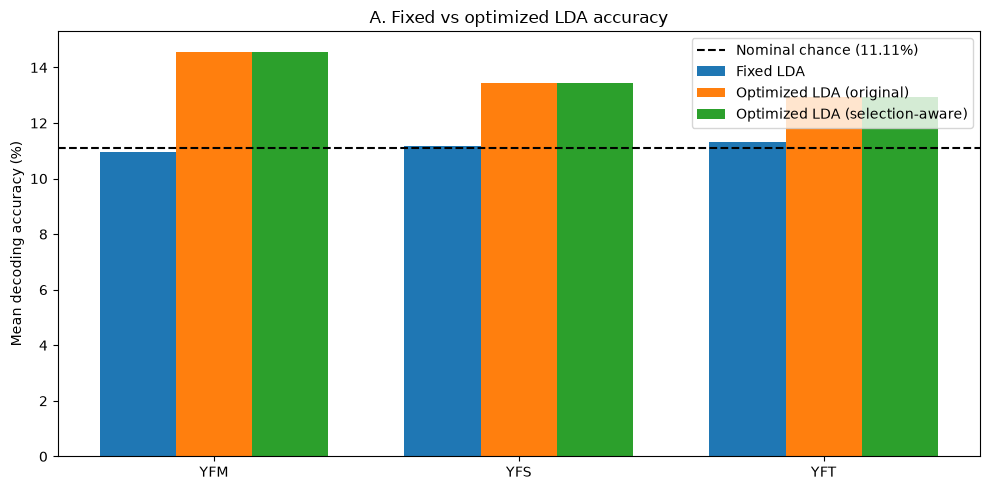

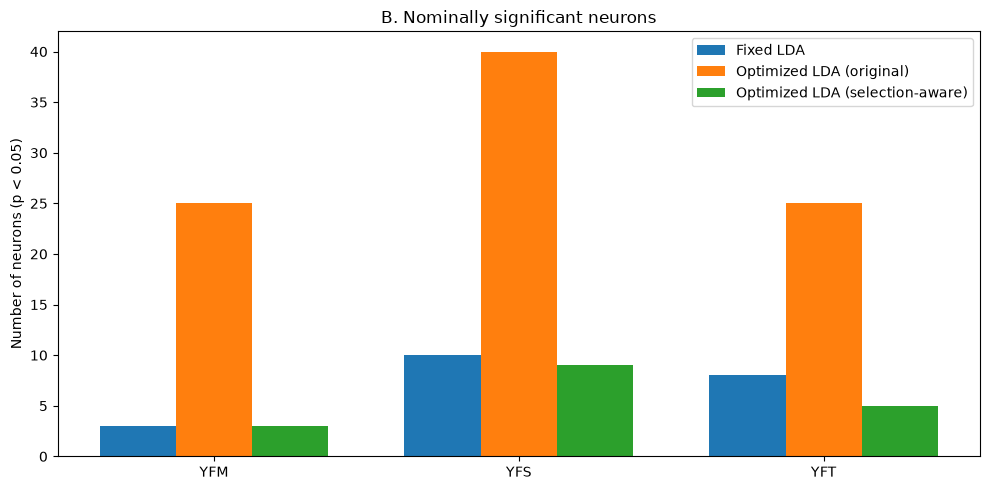

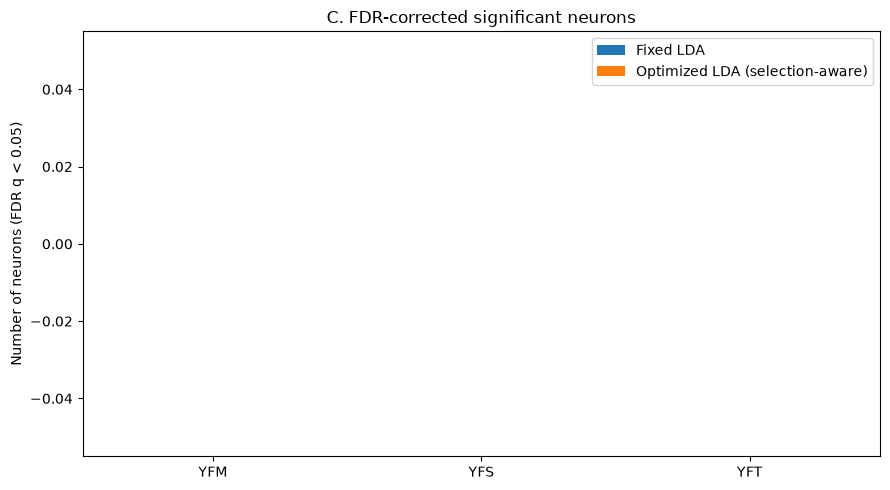


OVERALL RESULTS


,neurons,nominal_significant,fdr_significant
method,,,
Fixed LDA,364,21,0.0
Optimized LDA (original),364,90,NaN
Optimized LDA (selection-aware),364,17,0.0


In [233]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Paths
# ============================================================

repo_root = Path.cwd().parent
fixed_dir = repo_root / "server_lda" / "results_fixed"
aware_dir = repo_root / "server_lda" / "results_selection_aware"

# ============================================================
# 2. Benjamini-Hochberg FDR correction (no statsmodels needed)
# ============================================================

def bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    m = len(p)

    order = np.argsort(p)
    p_sorted = p[order]

    q_sorted = p_sorted * m / np.arange(1, m + 1)
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_sorted = np.clip(q_sorted, 0, 1)

    q = np.empty(m)
    q[order] = q_sorted
    return q

# ============================================================
# 3. Load fixed LDA results
# ============================================================

fixed_rows = []

for file in sorted(fixed_dir.glob("*_neuron_*.npz")):
    with np.load(file) as d:
        fixed_rows.append({
            "subject": str(d["subject"].item()),
            "neuron": int(d["neuron"]),
            "accuracy": float(d["observed"]),
            "p_value": float(d["p_value"])
        })

df_fixed = pd.DataFrame(fixed_rows)
assert len(df_fixed) == 364

df_fixed["q_value"] = bh_fdr(df_fixed["p_value"])

# ============================================================
# 4. Load selection-aware LDA results
# ============================================================

aware_path = aware_dir / "selection_aware_lda_all_neurons.csv"
df_aware = pd.read_csv(aware_path)

assert len(df_aware) == 364

# ============================================================
# 5. Summarize both saved analyses
# ============================================================

fixed_summary = df_fixed.groupby("subject").agg(
    neurons=("neuron", "count"),
    mean_accuracy=("accuracy", "mean"),
    nominal_significant=("p_value", lambda x: (x < 0.05).sum()),
    fdr_significant=("q_value", lambda x: (x < 0.05).sum())
)

aware_summary = df_aware.groupby("subject").agg(
    neurons=("neuron", "count"),
    mean_accuracy=("observed_accuracy", "mean"),
    nominal_significant=("p_value", lambda x: (x < 0.05).sum()),
    fdr_significant=("fdr_q_value", lambda x: (x < 0.05).sum())
)

# ============================================================
# 6. Original optimized LDA (previously reported results)
# ============================================================

original_summary = pd.DataFrame({
    "subject": ["YFM", "YFS", "YFT"],
    "neurons": [129, 144, 91],
    "mean_accuracy": [0.1457, 0.1345, 0.1294],
    "nominal_significant": [25, 40, 25],
    "fdr_significant": [np.nan, np.nan, np.nan]
}).set_index("subject")

# ============================================================
# 7. Combined summary table
# ============================================================

summaries = [
    ("Fixed LDA", fixed_summary),
    ("Optimized LDA (original)", original_summary),
    ("Optimized LDA (selection-aware)", aware_summary)
]

tables = []

for method, summary in summaries:
    temp = summary.reset_index().copy()
    temp["method"] = method
    temp["mean_accuracy"] *= 100
    tables.append(temp)

comparison_table = pd.concat(tables, ignore_index=True)

comparison_table = comparison_table[
    ["subject", "method", "neurons", "mean_accuracy",
     "nominal_significant", "fdr_significant"]
]

print("THREE-METHOD LDA COMPARISON")
display(comparison_table.round(2))

# ============================================================
# 8. Create comparison plots
# ============================================================

subjects = ["YFM", "YFS", "YFT"]
methods = [
    "Fixed LDA",
    "Optimized LDA (original)",
    "Optimized LDA (selection-aware)"
]

plot_df = comparison_table.set_index(["subject", "method"])
x = np.arange(len(subjects))
width = 0.25

# ------------------------------------------------------------
# Plot A: Mean decoding accuracy
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

for i, method in enumerate(methods):
    values = [
        plot_df.loc[(s, method), "mean_accuracy"]
        for s in subjects
    ]
    plt.bar(x + (i - 1) * width, values, width, label=method)

plt.axhline(100 / 9, color="black", linestyle="--",
            label="Nominal chance (11.11%)")

plt.xticks(x, subjects)
plt.ylabel("Mean decoding accuracy (%)")
plt.title("A. Fixed vs optimized LDA accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Plot B: Nominally significant neurons
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

for i, method in enumerate(methods):
    values = [
        plot_df.loc[(s, method), "nominal_significant"]
        for s in subjects
    ]
    plt.bar(x + (i - 1) * width, values, width, label=method)

plt.xticks(x, subjects)
plt.ylabel("Number of neurons (p < 0.05)")
plt.title("B. Nominally significant neurons")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Plot C: FDR significant neurons
# Original optimized LDA omitted because FDR was not verified
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for i, method in enumerate(
    ["Fixed LDA", "Optimized LDA (selection-aware)"]
):
    values = [
        plot_df.loc[(s, method), "fdr_significant"]
        for s in subjects
    ]
    plt.bar(x + (i - 0.5) * 0.35, values, 0.35, label=method)

plt.xticks(x, subjects)
plt.ylabel("Number of neurons (FDR q < 0.05)")
plt.title("C. FDR-corrected significant neurons")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 9. Overall summary
# ============================================================

overall = comparison_table.groupby("method", sort=False).agg(
    neurons=("neurons", "sum"),
    nominal_significant=("nominal_significant", "sum"),
    fdr_significant=("fdr_significant",
                     lambda x: x.sum(min_count=1))
)

print("\nOVERALL RESULTS")
display(overall)


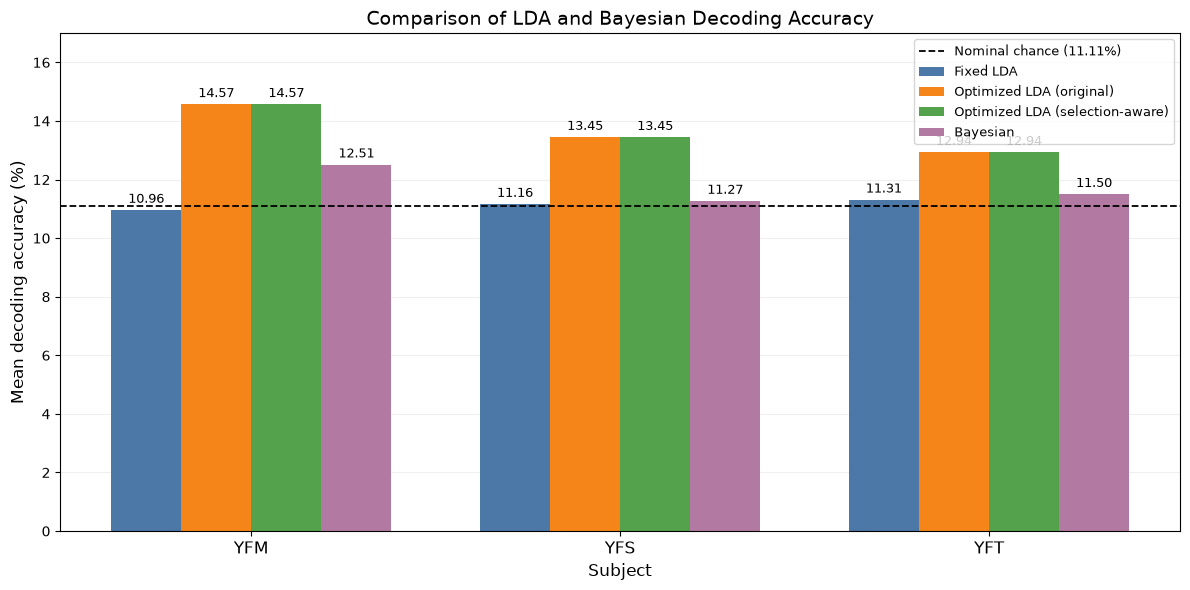

method,Bayesian,Fixed LDA,Optimized LDA (original),Optimized LDA (selection-aware)
subject,,,,
YFM,12.51,10.96,14.57,14.57
YFS,11.27,11.16,13.45,13.45
YFT,11.50,11.31,12.94,12.94


In [234]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Existing LDA comparison table
plot_df = comparison_table.copy()

# Bayesian decoding accuracies from earlier analysis
bayesian_accuracy = {
    "YFM": 12.51,
    "YFS": 11.27,
    "YFT": 11.50
}

bayesian_df = pd.DataFrame({
    "subject": list(bayesian_accuracy.keys()),
    "method": "Bayesian",
    "mean_accuracy": list(bayesian_accuracy.values())
})

# Combine all four methods
accuracy_df = pd.concat(
    [
        plot_df[["subject", "method", "mean_accuracy"]],
        bayesian_df
    ],
    ignore_index=True
)

subjects = ["YFM", "YFS", "YFT"]

methods = [
    "Fixed LDA",
    "Optimized LDA (original)",
    "Optimized LDA (selection-aware)",
    "Bayesian"
]

colors = ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]

x = np.arange(len(subjects))
width = 0.19

fig, ax = plt.subplots(figsize=(12, 6))

for i, method in enumerate(methods):
    values = [
        accuracy_df.loc[
            (accuracy_df["subject"] == subject) &
            (accuracy_df["method"] == method),
            "mean_accuracy"
        ].iloc[0]
        for subject in subjects
    ]

    offset = (i - 1.5) * width

    bars = ax.bar(
        x + offset,
        values,
        width,
        label=method,
        color=colors[i]
    )

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

# Nominal chance for 9 number classes
ax.axhline(
    100 / 9,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label="Nominal chance (11.11%)"
)

ax.set_xticks(x)
ax.set_xticklabels(subjects, fontsize=12)
ax.set_ylabel("Mean decoding accuracy (%)", fontsize=12)
ax.set_xlabel("Subject", fontsize=12)
ax.set_title(
    "Comparison of LDA and Bayesian Decoding Accuracy",
    fontsize=14
)

ax.set_ylim(0, 17)
ax.legend(loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Display numerical table
accuracy_table = accuracy_df.pivot(
    index="subject",
    columns="method",
    values="mean_accuracy"
)

display(accuracy_table.round(2))


In [235]:
from pathlib import Path

repo_root = Path.cwd().parent

keywords = (
    "geometry", "simplex", "centroid",
    "transition", "angle", "lda", "embedding"
)

for path in sorted(repo_root.rglob("*")):
    if (
        path.is_file()
        and path.suffix.lower() in {".csv", ".npy", ".npz"}
        and any(k in path.name.lower() for k in keywords)
        and ".git" not in path.parts
        and ".venv" not in path.parts
        and "results_fixed" not in path.parts
        and "results_selection_aware" not in path.parts
    ):
        print(path.relative_to(repo_root))

notebooks2\tables2\single_neuron_lda_checkpoint.csv
notebooks2\tables2\single_neuron_lda_optimized.csv
notebooks2\tables2\single_neuron_lda_permutation_checkpoint.csv
notebooks2\tables2\single_neuron_lda_permutation_results.csv
tables\arithmetic_population_lda_components_60ms_permutation.csv
tables\arithmetic_population_lda_components_group_null.csv
tables\diagnostic_YFM_neuron63_sparse_lda.csv
tables\figure1G_YFU_hpc43_all_LDA_components.csv
tables\figure1G_YFU_hpc43_LDA_weights.csv
tables\figure1H_YFU_hpc43_gamma08_centroids.csv
tables\figure1H_YFU_hpc43_TC_centroids.csv
tables1\lda_logistic_missing_88_neurons.csv
tables1\YFF_lda_vs_logistic.csv
tables1\YFI_lda_vs_logistic.csv
tables1\YFJ_lda_vs_logistic.csv
tables1\YFK_lda_vs_logistic.csv
tables1\YFL_lda_vs_logistic.csv
tables1\YFM_lda_vs_logistic.csv
tables1\YFP_lda_vs_logistic.csv
tables1\YFR_lda_vs_logistic.csv
tables1\YFS_lda_vs_logistic.csv
tables1\YFT_lda_vs_logistic.csv
tables1\YFU_all_simplex_geometry_comparison.csv
tables1\

In [236]:
import pandas as pd

files = [
    "single_neuron_lda_optimized.csv",
    "single_neuron_lda_permutation_results.csv"
]

for name in files:
    path = repo_root / "notebooks2" / "tables2" / name
    df = pd.read_csv(path)

    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


single_neuron_lda_optimized.csv
Shape: (364, 7)
Columns: ['subject', 'neuron', 'original_neuron_index', 'best_bin_ms', 'best_gamma', 'cv_folds', 'best_accuracy']


,subject,neuron,original_neuron_index,best_bin_ms,best_gamma,cv_folds,best_accuracy
0,YFM,0,0,75,0.8,4,0.166667
1,YFM,1,1,180,0.5,4,0.140351
2,YFM,2,2,60,0.2,4,0.122807



single_neuron_lda_permutation_results.csv
Shape: (364, 13)
Columns: ['subject', 'neuron', 'original_neuron_index', 'best_bin_ms', 'best_gamma', 'observed_accuracy', 'null_mean_accuracy', 'null_95th_percentile', 'p_value', 'significant_p005', 'selected_p0125', 'n_permutations', 'seed']


,subject,neuron,original_neuron_index,best_bin_ms,best_gamma,observed_accuracy,null_mean_accuracy,null_95th_percentile,p_value,significant_p005,selected_p0125,n_permutations,seed
0,YFM,0,0,75,0.8,0.166667,0.118947,0.175877,0.119403,False,True,200,42
1,YFM,1,1,180,0.5,0.140351,0.088026,0.157895,0.104478,False,True,200,42
2,YFM,2,2,60,0.2,0.122807,0.091140,0.149123,0.223881,False,False,200,42


In [237]:
original = pd.read_csv(
    repo_root / "notebooks2" / "tables2"
    / "single_neuron_lda_optimized.csv"
)

aware = pd.read_csv(
    repo_root / "server_lda" / "results_selection_aware"
    / "selection_aware_lda_all_neurons.csv"
)

check = original.merge(
    aware,
    on=["subject", "neuron"],
    suffixes=("_original", "_aware"),
    validate="one_to_one"
)

print("Matched neurons:", len(check))

print(
    "Accuracy differences:",
    np.sum(
        ~np.isclose(
            check["best_accuracy"],
            check["observed_accuracy"]
        )
    )
)

print(
    "Bin-width differences:",
    np.sum(
        check["best_bin_ms_original"]
        != check["best_bin_ms_aware"]
    )
)

print(
    "Shrinkage differences:",
    np.sum(
        ~np.isclose(
            check["best_gamma_original"],
            check["best_gamma_aware"]
        )
    )
)

Matched neurons: 364
Accuracy differences: 0
Bin-width differences: 0
Shrinkage differences: 0


In [238]:
from pathlib import Path

repo_root = Path.cwd().parent

for folder_name in ["server_lda", "notebooks2"]:
    folder = repo_root / folder_name

    print(f"\n--- {folder_name} ---")

    for path in sorted(folder.rglob("*.py")):
        if ".venv" not in path.parts:
            print(path.relative_to(repo_root))


--- server_lda ---
server_lda\fixed_permutations.py
server_lda\lda_core.py
server_lda\preprocessing.py
server_lda\selection_aware_permutations.py

--- notebooks2 ---


In [239]:
from pathlib import Path

path = repo_root / "server_lda" / "lda_core.py"

print(path.read_text(encoding="utf-8"))

import numpy as np
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold


def lda_cv_accuracy(X, y, gamma, n_splits):
    """
    Reproduce the original notebook's single-neuron LDA CV accuracy.

    X: presentations x temporal bins
    y: number labels (1 through 9)
    gamma: LDA shrinkage
    n_splits: number of stratified CV folds
    """
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42,
    )

    predictions = np.full(len(y), -1, dtype=int)

    for train_idx, test_idx in cv.split(X, y):
        X_train = X[train_idx]
        X_test = X[test_idx]
        y_train = y[train_idx]

        within_variance = np.zeros(X.shape[1])

        for number in np.unique(y_train):
            class_X = X_train[y_train == number]
            within_variance += (
                class_X.var(axis=0) * len(class_X)
            )

        keep = within_variance > 0

        if not np

In [240]:
from pathlib import Path

path = repo_root / "server_lda" / "preprocessing.py"

print(path.read_text(encoding="utf-8"))

from pathlib import Path

import h5py
import numpy as np
import pandas as pd
from scipy.sparse import csc_matrix

ROOT = Path(__file__).resolve().parent.parent
DATA = ROOT / "data" / "sorted_data"

SUBJECTS = {
    "YFM": ("spikesArithmetic.mat", "spikesArithmetic"),
    "YFS": ("spikes.mat", "spikes"),
    "YFT": ("spikes.mat", "spikes"),
}

MTL_REGIONS = {"hpc", "ent", "amy", "para-hpc"}
BIN_SIZES = [60, 75, 90, 100, 150, 180, 225, 300, 450, 900]
GAMMAS = [0.2, 0.5, 0.8]


def load_subject(subject):
    filename, spike_key = SUBJECTS[subject]
    folder = DATA / subject / "arithmetic"

    # Reproduce notebook cell 17: presentation selection.
    df = pd.read_csv(folder / "photoBehavEvents.csv")
    df = df[df["toExclude"] == 0].copy()

    if subject in {"YFR", "YFS"}:
        df["operand1_onset"] = df["tCue1"]
        df["operand2_onset"] = df["tCue3"]
    else:
        df["operand1_onset"] = np.where(
            df["operationFirst"] == 1, df["tCue2"], df["tCue1"]
        )
      

In [241]:
from pathlib import Path

path = repo_root / "server_lda" / "preprocessing.py"
source = path.read_text(encoding="utf-8")

print("Total lines:", len(source.splitlines()))

for i, line in enumerate(source.splitlines(), start=1):
    if line.startswith("def "):
        print(f"Line {i}: {line}")

Total lines: 131
Line 22: def load_subject(subject):
Line 99: def temporal_counts(spikes, starts, bin_size):


In [242]:
from pathlib import Path

path = repo_root / "server_lda" / "preprocessing.py"
lines = path.read_text(encoding="utf-8").splitlines()

for i in range(98, len(lines)):
    print(f"{i + 1:3d}: {lines[i]}")

 99: def temporal_counts(spikes, starts, bin_size):
100:     if 900 % bin_size:
101:         raise ValueError("Bin size must divide 900 ms exactly")
102: 
103:     n_bins = 900 // bin_size
104:     X = np.zeros(
105:         (len(starts), spikes.shape[0], n_bins),
106:         dtype=np.int32,
107:     )
108: 
109:     for i, start in enumerate(starts):
110:         for b in range(n_bins):
111:             left = start + b * bin_size
112:             right = left + bin_size
113:             X[i, :, b] = np.asarray(
114:                 spikes[:, left:right].sum(axis=1)
115:             ).ravel()
116: 
117:     return X
118: 
119: 
120: if __name__ == "__main__":
121:     for subject in SUBJECTS:
122:         spikes, starts, y, trials, indices = load_subject(subject)
123:         X = temporal_counts(spikes, starts, 100)
124: 
125:         print(
126:             f"{subject}: presentations={len(y)}, "
127:             f"MTL neurons={len(indices)}, "
128:             f"100ms shape={X.shape

In [243]:
import sys

server_path = str(repo_root / "server_lda")

if server_path not in sys.path:
    sys.path.insert(0, server_path)

from preprocessing import load_subject, temporal_counts

spikes, starts, y, trials, indices = load_subject("YFM")

print("Subject: YFM")
print("Neurons:", spikes.shape[0])
print("Presentations:", len(y))
print("Number labels:", np.unique(y))
print("Unique trials:", len(np.unique(trials)))

Subject: YFM
Neurons: 129
Presentations: 114
Number labels: [1 2 3 4 5 6 7 8 9]
Unique trials: 78


In [244]:
import pandas as pd
import numpy as np

optimized = pd.read_csv(
    repo_root / "notebooks2" / "tables2"
    / "single_neuron_lda_optimized.csv"
)

yfm_params = (
    optimized[optimized["subject"] == "YFM"]
    .sort_values("neuron")
    .reset_index(drop=True)
)

assert len(yfm_params) == 129
assert np.array_equal(yfm_params["neuron"].to_numpy(), np.arange(129))

print("Optimized bin widths:")
print(yfm_params["best_bin_ms"].value_counts().sort_index())

print("\nOptimized shrinkage values:")
print(yfm_params["best_gamma"].value_counts().sort_index())

print("\nNeurons with fewer than 3 temporal bins:")
print(yfm_params.loc[
    900 // yfm_params["best_bin_ms"] < 3,
    ["neuron", "best_bin_ms", "best_gamma"]
])

Optimized bin widths:
best_bin_ms
60     32
75     17
90     16
100    17
150     9
180     7
225     7
300    10
450     4
900    10
Name: count, dtype: int64

Optimized shrinkage values:
best_gamma
0.2    85
0.5    23
0.8    21
Name: count, dtype: int64

Neurons with fewer than 3 temporal bins:
     neuron  best_bin_ms  best_gamma
4         4          900         0.2
9         9          900         0.2
20       20          900         0.2
21       21          900         0.2
26       26          450         0.5
33       33          900         0.2
38       38          450         0.5
59       59          450         0.2
61       61          900         0.2
70       70          900         0.2
77       77          900         0.2
87       87          900         0.2
108     108          900         0.2
110     110          450         0.8


In [245]:
from preprocessing import temporal_counts

component_counts = []
X_cache = {}

for bin_size in sorted(yfm_params["best_bin_ms"].unique()):
    X_cache[int(bin_size)] = temporal_counts(
        spikes, starts, int(bin_size)
    )

for row in yfm_params.itertuples(index=False):
    X = X_cache[int(row.best_bin_ms)][:, int(row.neuron), :]

    within_variance = np.zeros(X.shape[1])

    for number in np.unique(y):
        class_X = X[y == number]
        within_variance += (
            class_X.var(axis=0) * len(class_X)
        )

    n_features = int(np.sum(within_variance > 0))
    n_components = min(n_features, len(np.unique(y)) - 1)

    component_counts.append({
        "neuron": int(row.neuron),
        "bin_ms": int(row.best_bin_ms),
        "usable_features": n_features,
        "max_components": n_components
    })

component_df = pd.DataFrame(component_counts)

print("Available component counts:")
print(component_df["max_components"].value_counts().sort_index())

print("\nNeurons supporting at least 3 components:",
      (component_df["max_components"] >= 3).sum())

print("Neurons supporting LD1:",
      (component_df["max_components"] >= 1).sum())

Available component counts:
max_components
0     3
1    11
2     5
3    12
4     8
5     8
6    10
7     1
8    71
Name: count, dtype: int64

Neurons supporting at least 3 components: 110
Neurons supporting LD1: 126


In [246]:
import scipy
from scipy.linalg import eigh

print("SciPy version:", scipy.__version__)
print("Generalized eigenvalue solver available:", callable(eigh))

print("\nYFM data ready:")
print("Presentations:", len(y))
print("Neurons:", spikes.shape[0])
print("Optimized parameters:", len(yfm_params))
print("Cached bin widths:", sorted(X_cache.keys()))

SciPy version: 1.18.1
Generalized eigenvalue solver available: True

YFM data ready:
Presentations: 114
Neurons: 129
Optimized parameters: 129
Cached bin widths: [60, 75, 90, 100, 150, 180, 225, 300, 450, 900]


In [247]:
from scipy.linalg import eigh
import numpy as np

Z1 = np.zeros((len(y), len(yfm_params)))
Z3 = np.zeros((len(y), 3 * len(yfm_params)))

component_eigenvalues = []
component_status = []

for row in yfm_params.itertuples(index=False):

    neuron = int(row.neuron)
    bin_size = int(row.best_bin_ms)
    gamma = float(row.best_gamma)

    X = X_cache[bin_size][:, neuron, :].astype(float)

    # Same feature-filtering criterion as original LDA
    within_variance = np.zeros(X.shape[1])

    for number in np.unique(y):
        Xk = X[y == number]
        within_variance += len(Xk) * Xk.var(axis=0)

    keep = within_variance > 0
    X = X[:, keep]

    if X.shape[1] == 0:
        component_status.append((neuron, 0))
        continue

    # Class means and global mean
    classes = np.unique(y)
    means = np.array([X[y == k].mean(axis=0) for k in classes])
    counts = np.array([np.sum(y == k) for k in classes])
    global_mean = X.mean(axis=0)

    # Pooled within-class covariance
    Sw = np.zeros((X.shape[1], X.shape[1]))

    for k, mean in zip(classes, means):
        residuals = X[y == k] - mean
        Sw += residuals.T @ residuals

    Sw /= max(len(y) - len(classes), 1)

    # Shrinkage regularization
    Sw = (1 - gamma) * Sw + gamma * np.diag(np.diag(Sw))

    # Between-class covariance
    Sb = np.zeros_like(Sw)

    for nk, mean in zip(counts, means):
        diff = mean - global_mean
        Sb += nk * np.outer(diff, diff)

    Sb /= len(y)

    # Numerical stabilization
    Sw += 1e-8 * np.eye(Sw.shape[0])

    # Generalized eigenvectors
    eigenvalues, eigenvectors = eigh(Sb, Sw)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    n_components = min(3, X.shape[1], len(classes) - 1)

    # Project all presentations
    scores = (X - global_mean) @ eigenvectors[:, :n_components]

    # Consistent sign convention
    for j in range(n_components):
        loading = eigenvectors[:, j]
        pivot = np.argmax(np.abs(loading))
        if loading[pivot] < 0:
            scores[:, j] *= -1

    # LD1
    Z1[:, neuron] = scores[:, 0]

    # LD1–LD3
    Z3[:, 3 * neuron:3 * neuron + n_components] = scores

    component_eigenvalues.append(eigenvalues[:n_components])
    component_status.append((neuron, n_components))

print("LD1 population matrix:", Z1.shape)
print("LD1–LD3 population matrix:", Z3.shape)

print("Nonzero LD1 columns:",
      np.sum(np.any(Z1 != 0, axis=0)))

print("Nonzero LD1–LD3 columns:",
      np.sum(np.any(Z3 != 0, axis=0)))

print("All finite:", np.isfinite(Z1).all(), np.isfinite(Z3).all())

LD1 population matrix: (114, 129)
LD1–LD3 population matrix: (114, 387)
Nonzero LD1 columns: 126
Nonzero LD1–LD3 columns: 351
All finite: True True


In [248]:
import numpy as np
import pandas as pd

numbers = np.arange(1, 10)

# Mean population representation for each number
C1 = np.vstack([
    Z1[y == k].mean(axis=0)
    for k in numbers
])

C3 = np.vstack([
    Z3[y == k].mean(axis=0)
    for k in numbers
])

print("LD1 centroid matrix:", C1.shape)
print("LD1–LD3 centroid matrix:", C3.shape)

print("\nPresentations per number:")
print(pd.Series(y).value_counts().sort_index())

print("\nCentroid matrix checks:")
print("LD1 finite:", np.isfinite(C1).all())
print("LD1–LD3 finite:", np.isfinite(C3).all())

# Center the nine number centroids
C1_centered = C1 - C1.mean(axis=0)
C3_centered = C3 - C3.mean(axis=0)

print("\nCentered centroid ranks:")
print("LD1:", np.linalg.matrix_rank(C1_centered))
print("LD1–LD3:", np.linalg.matrix_rank(C3_centered))

LD1 centroid matrix: (9, 129)
LD1–LD3 centroid matrix: (9, 387)

Presentations per number:
1    19
2    17
3    14
4     4
5    14
6    16
7    10
8    12
9     8
Name: count, dtype: int64

Centroid matrix checks:
LD1 finite: True
LD1–LD3 finite: True

Centered centroid ranks:
LD1: 8
LD1–LD3: 8


In [249]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist

def geometry_metrics(C):
    # Center number centroids
    A = C - C.mean(axis=0)

    # Singular values
    s = np.linalg.svd(A, compute_uv=False)
    s = s[s > 1e-10]

    # Variance proportions
    p = s**2 / np.sum(s**2)

    # Effective rank (entropy-based)
    effective_rank = np.exp(-np.sum(p * np.log(p)))

    # Participation ratio
    participation_ratio = 1 / np.sum(p**2)

    # Sequential transition vectors
    transitions = np.diff(C, axis=0)

    angles = []
    for i in range(len(transitions) - 1):
        u = transitions[i]
        v = transitions[i + 1]

        cosine = np.dot(u, v) / (
            np.linalg.norm(u) * np.linalg.norm(v)
        )

        angles.append(
            np.degrees(np.arccos(np.clip(cosine, -1, 1)))
        )

    # Simplex log-volume (8-dimensional)
    E = C[1:] - C[0]
    singular_edges = np.linalg.svd(E, compute_uv=False)

    log_volume = (
        np.sum(np.log(singular_edges))
        - np.sum(np.log(np.arange(1, 9)))
    )

    distances = pdist(C, metric="euclidean")

    return {
        "Affine rank": np.linalg.matrix_rank(A),
        "Effective rank": effective_rank,
        "Participation ratio": participation_ratio,
        "Mean transition angle (deg)": np.mean(angles),
        "Transition angle SD (deg)": np.std(angles),
        "Log simplex volume": log_volume,
        "Mean pairwise distance": np.mean(distances),
        "Distance CV": np.std(distances) / np.mean(distances)
    }

results = pd.DataFrame({
    "LD1 only": geometry_metrics(C1),
    "LD1–LD3": geometry_metrics(C3)
}).T

display(results.round(4))

,Affine rank,Effective rank,Participation ratio,Mean transition angle (deg),Transition angle SD (deg),Log simplex volume,Mean pairwise distance,Distance CV
LD1 only,8.0,7.0082,6.2647,119.4911,10.3485,4.7614,8.8667,0.1783
LD1–LD3,8.0,7.2808,6.6400,119.3433,8.6881,7.6951,12.5591,0.1556


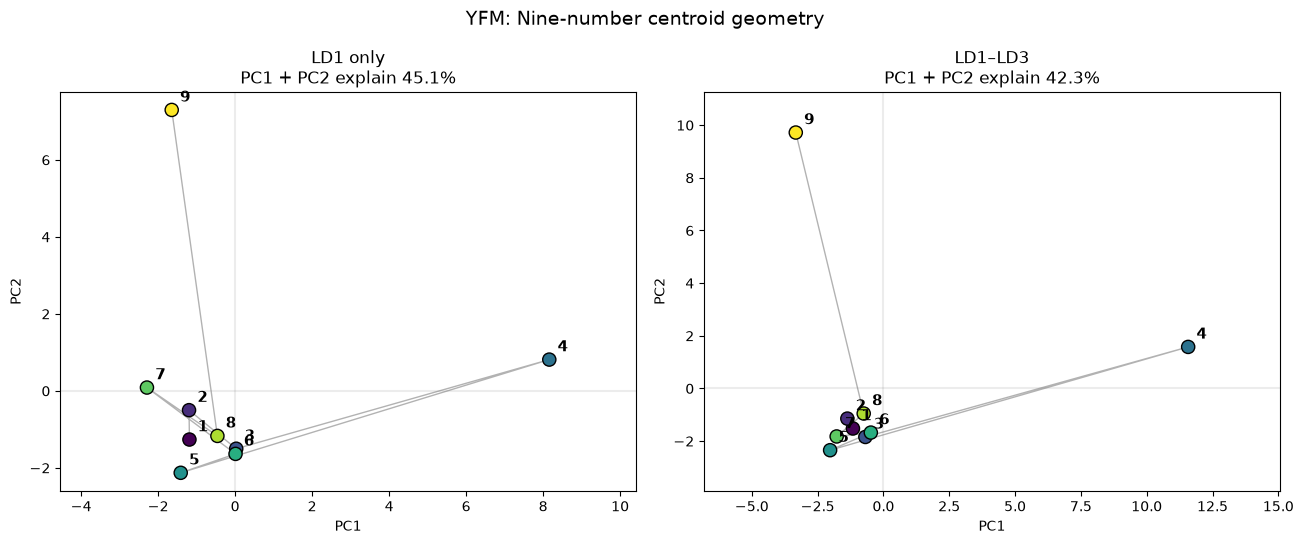

In [250]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, C, title in zip(
    axes,
    [C1, C3],
    ["LD1 only", "LD1–LD3"]
):
    pca = PCA(n_components=2)
    coords = pca.fit_transform(C)

    ax.plot(
        coords[:, 0],
        coords[:, 1],
        color="gray",
        linewidth=1,
        alpha=0.6
    )

    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        s=90,
        c=np.arange(1, 10),
        cmap="viridis",
        edgecolors="black",
        zorder=3
    )

    for number, (x, y_coord) in enumerate(coords, start=1):
        ax.annotate(
            str(number),
            (x, y_coord),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=11,
            fontweight="bold"
        )

    explained = pca.explained_variance_ratio_.sum() * 100

    ax.set_title(
        f"{title}\nPC1 + PC2 explain {explained:.1f}%"
    )
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.axhline(0, color="gray", alpha=0.15)
    ax.axvline(0, color="gray", alpha=0.15)
    ax.set_aspect("equal", adjustable="datalim")

plt.suptitle(
    "YFM: Nine-number centroid geometry",
    fontsize=14
)
plt.tight_layout()
plt.show()

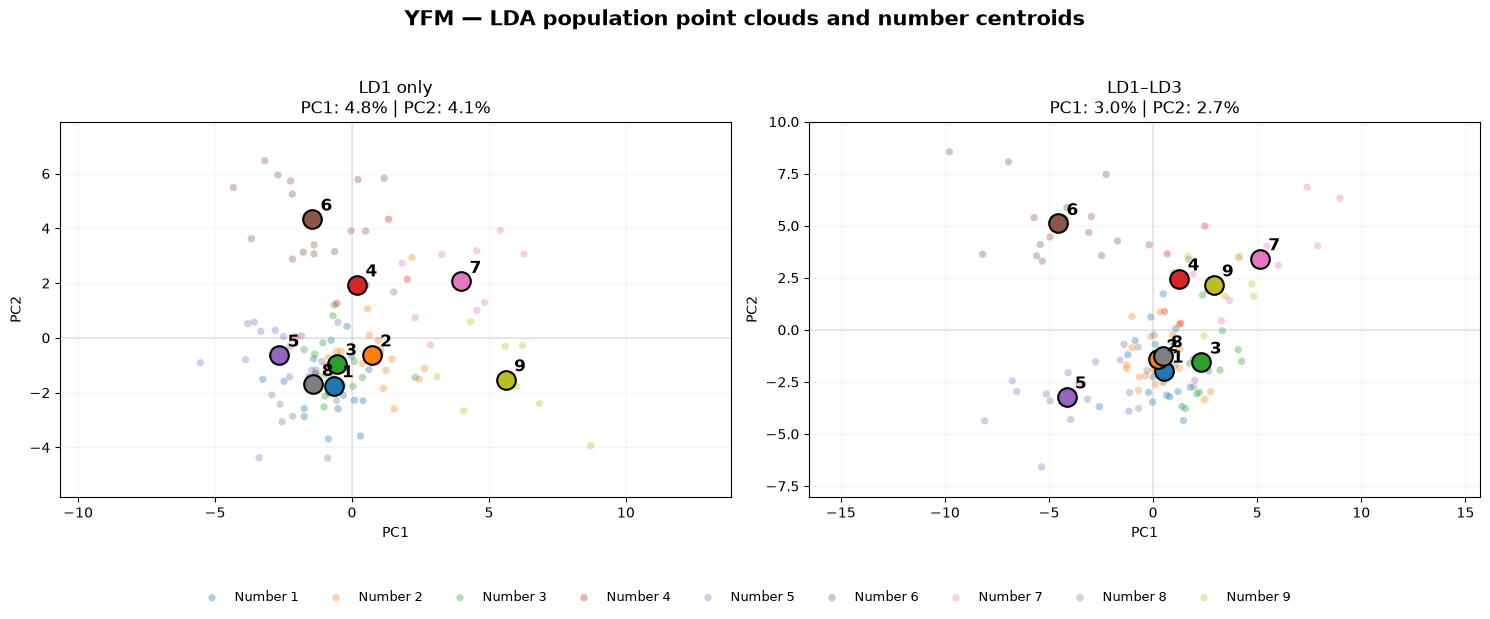

In [251]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

numbers = np.arange(1, 10)
colors = plt.get_cmap("tab10").colors[:9]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, Z, title in zip(
    axes,
    [Z1, Z3],
    ["LD1 only", "LD1–LD3"]
):
    # Fit PCA on all presentation-level population vectors
    pca = PCA(n_components=2)
    cloud_2d = pca.fit_transform(Z)

    # Project the nine centroids using the SAME PCA
    centroids = np.vstack([
        Z[y == k].mean(axis=0)
        for k in numbers
    ])
    centroids_2d = pca.transform(centroids)

    # Plot individual presentations
    for i, number in enumerate(numbers):
        mask = (y == number)

        ax.scatter(
            cloud_2d[mask, 0],
            cloud_2d[mask, 1],
            s=28,
            color=colors[i],
            alpha=0.35,
            edgecolors="none",
            label=f"Number {number}"
        )

    # Plot number centroids
    for i, number in enumerate(numbers):
        cx, cy = centroids_2d[i]

        ax.scatter(
            cx, cy,
            s=180,
            color=colors[i],
            edgecolors="black",
            linewidths=1.5,
            zorder=5
        )

        ax.annotate(
            str(number),
            (cx, cy),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=12,
            fontweight="bold",
            zorder=6
        )

    explained = pca.explained_variance_ratio_ * 100

    ax.set_title(
        f"{title}\n"
        f"PC1: {explained[0]:.1f}% | "
        f"PC2: {explained[1]:.1f}%",
        fontsize=12
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.axhline(0, color="gray", alpha=0.15)
    ax.axvline(0, color="gray", alpha=0.15)
    ax.grid(alpha=0.12)
    ax.set_aspect("equal", adjustable="datalim")

fig.suptitle(
    "YFM — LDA population point clouds and number centroids",
    fontsize=15,
    fontweight="bold"
)

# Shared legend outside the panels
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.03),
    ncol=9,
    frameon=False,
    fontsize=9
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])
plt.show()


In [252]:

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA

numbers = np.arange(1, 10)

colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c",
    "#d62728", "#9467bd", "#8c564b",
    "#e377c2", "#7f7f7f", "#bcbd22"
]

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}]],
    subplot_titles=("LD1 only", "LD1–LD3"),
    horizontal_spacing=0.04
)

for col, (Z, title) in enumerate(
    [(Z1, "LD1 only"), (Z3, "LD1–LD3")],
    start=1
):
    # Fit PCA on the full presentation cloud
    pca = PCA(n_components=3)
    cloud = pca.fit_transform(Z)

    # Calculate centroids in original feature space
    centroids = np.vstack([
        Z[y == k].mean(axis=0)
        for k in numbers
    ])

    # Project centroids into the SAME PCA space
    centers = pca.transform(centroids)

    # Individual presentations
    for i, k in enumerate(numbers):
        mask = y == k

        fig.add_trace(
            go.Scatter3d(
                x=cloud[mask, 0],
                y=cloud[mask, 1],
                z=cloud[mask, 2],
                mode="markers",
                name=f"Number {k}",
                legendgroup=f"number{k}",
                showlegend=(col == 1),
                marker=dict(
                    size=3,
                    color=colors[i],
                    opacity=0.35
                ),
                hovertemplate=(
                    f"Number {k}<br>"
                    "PC1=%{x:.2f}<br>"
                    "PC2=%{y:.2f}<br>"
                    "PC3=%{z:.2f}<extra></extra>"
                )
            ),
            row=1, col=col
        )

    # Centroids
    fig.add_trace(
        go.Scatter3d(
            x=centers[:, 0],
            y=centers[:, 1],
            z=centers[:, 2],
            mode="markers+text",
            text=[str(k) for k in numbers],
            textposition="top center",
            name="Centroids",
            showlegend=(col == 1),
            marker=dict(
                size=9,
                color=colors,
                opacity=1,
                line=dict(color="black", width=3)
            ),
            hovertemplate=(
                "Centroid<br>"
                "PC1=%{x:.2f}<br>"
                "PC2=%{y:.2f}<br>"
                "PC3=%{z:.2f}<extra></extra>"
            )
        ),
        row=1, col=col
    )

    variance = pca.explained_variance_ratio_ * 100

    scene_settings = dict(
        xaxis_title=f"PC1 ({variance[0]:.1f}%)",
        yaxis_title=f"PC2 ({variance[1]:.1f}%)",
        zaxis_title=f"PC3 ({variance[2]:.1f}%)",
        aspectmode="data"
    )

    if col == 1:
        fig.update_layout(scene=scene_settings)
    else:
        fig.update_layout(scene2=scene_settings)

fig.update_layout(
    title="YFM — 3D LDA population clouds and number centroids",
    height=650,
    width=1350,
    template="plotly_white",
    legend=dict(
        orientation="h",
        y=-0.08,
        x=0.5,
        xanchor="center"
    ),
    margin=dict(l=0, r=0, t=90, b=80)
)

fig.show()


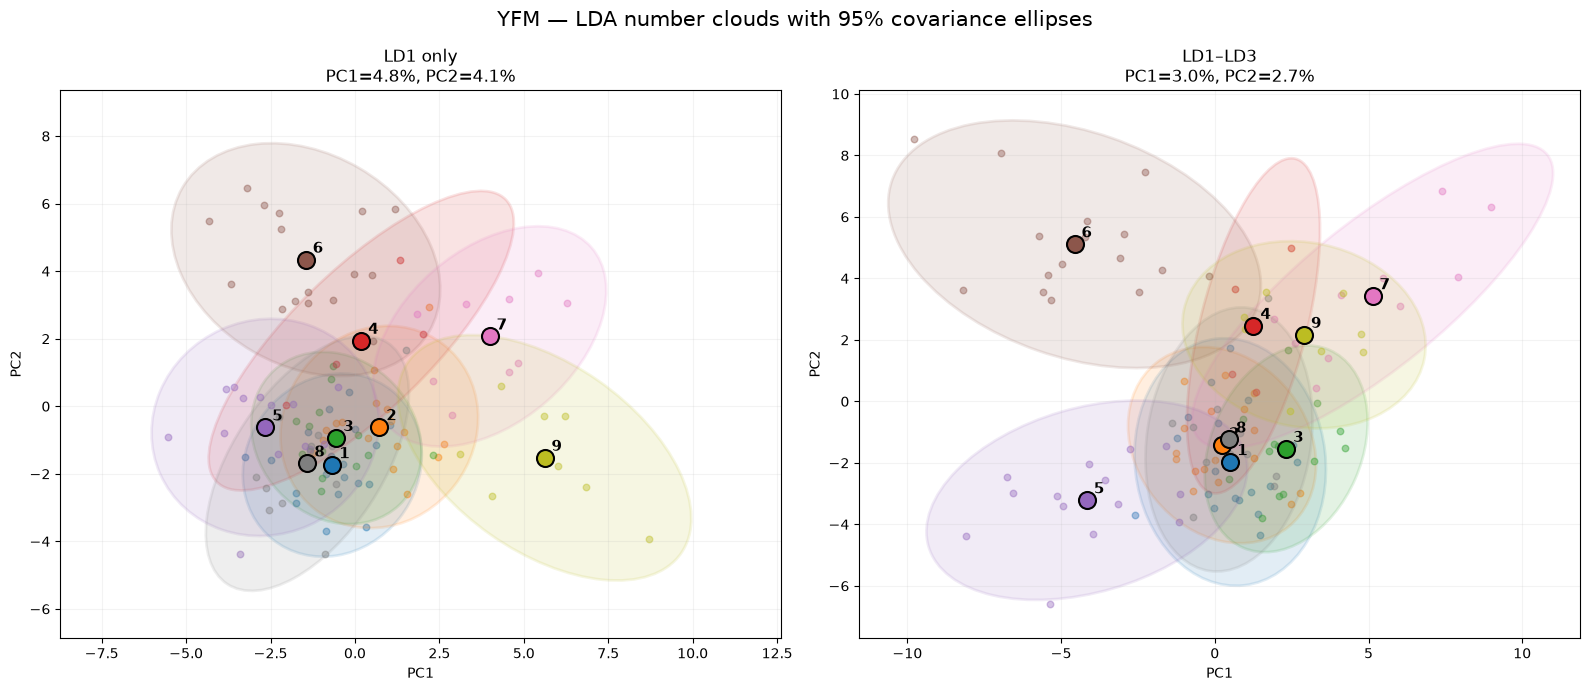

In [253]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.decomposition import PCA
from scipy.stats import chi2

numbers = np.arange(1, 10)
colors = plt.get_cmap("tab10").colors[:9]

def add_covariance_ellipse(ax, points, color, confidence=0.95):
    """Gaussian covariance ellipse enclosing nominal confidence mass."""
    if len(points) < 3:
        return

    mean = points.mean(axis=0)
    covariance = np.cov(points, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]

    eigenvalues = np.maximum(eigenvalues[order], 0)
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
    )

    radius = np.sqrt(chi2.ppf(confidence, df=2))

    ellipse = Ellipse(
        xy=mean,
        width=2 * radius * np.sqrt(eigenvalues[0]),
        height=2 * radius * np.sqrt(eigenvalues[1]),
        angle=angle,
        facecolor=color,
        edgecolor=color,
        alpha=0.13,
        linewidth=2
    )

    ax.add_patch(ellipse)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, Z, title in zip(
    axes,
    [Z1, Z3],
    ["LD1 only", "LD1–LD3"]
):
    pca = PCA(n_components=2)
    cloud = pca.fit_transform(Z)

    for i, k in enumerate(numbers):
        points = cloud[y == k]
        center = points.mean(axis=0)

        # Individual presentations
        ax.scatter(
            points[:, 0],
            points[:, 1],
            s=22,
            color=colors[i],
            alpha=0.4
        )

        # 95% covariance ellipse
        add_covariance_ellipse(
            ax, points, colors[i], confidence=0.95
        )

        # Centroid
        ax.scatter(
            center[0], center[1],
            s=150,
            color=colors[i],
            edgecolors="black",
            linewidth=1.5,
            zorder=5
        )

        ax.annotate(
            str(k), center,
            xytext=(5, 5),
            textcoords="offset points",
            fontweight="bold",
            fontsize=11
        )

    explained = pca.explained_variance_ratio_ * 100

    ax.set_title(
        f"{title}\nPC1={explained[0]:.1f}%, "
        f"PC2={explained[1]:.1f}%"
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.15)

plt.suptitle(
    "YFM — LDA number clouds with 95% covariance ellipses",
    fontsize=15
)
plt.tight_layout()
plt.show()


In [254]:

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA
from scipy.stats import chi2

numbers = np.arange(1, 10)

colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c",
    "#d62728", "#9467bd", "#8c564b",
    "#e377c2", "#7f7f7f", "#bcbd22"
]

def ellipsoid_surface(points, confidence=0.95, resolution=20):
    if len(points) < 4:
        return None

    mean = points.mean(axis=0)
    cov = np.cov(points, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    eigenvalues = np.maximum(eigenvalues, 0)

    radius = np.sqrt(chi2.ppf(confidence, df=3))

    u = np.linspace(0, 2 * np.pi, resolution)
    v = np.linspace(0, np.pi, resolution)

    sphere = np.array([
        np.outer(np.cos(u), np.sin(v)).ravel(),
        np.outer(np.sin(u), np.sin(v)).ravel(),
        np.outer(np.ones_like(u), np.cos(v)).ravel()
    ])

    transformed = (
        eigenvectors @ np.diag(radius * np.sqrt(eigenvalues))
        @ sphere
    ) + mean[:, None]

    shape = (resolution, resolution)

    return (
        transformed[0].reshape(shape),
        transformed[1].reshape(shape),
        transformed[2].reshape(shape)
    )

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}]],
    subplot_titles=("LD1 only", "LD1–LD3")
)

for col, Z in enumerate([Z1, Z3], start=1):
    pca = PCA(n_components=3)
    cloud = pca.fit_transform(Z)

    for i, k in enumerate(numbers):
        points = cloud[y == k]
        center = points.mean(axis=0)

        # Presentation cloud
        fig.add_trace(
            go.Scatter3d(
                x=points[:, 0],
                y=points[:, 1],
                z=points[:, 2],
                mode="markers",
                name=f"Number {k}",
                legendgroup=f"n{k}",
                showlegend=(col == 1),
                marker=dict(
                    size=3,
                    color=colors[i],
                    opacity=0.5
                )
            ),
            row=1, col=col
        )

        # Covariance ellipsoid
        surface = ellipsoid_surface(points)

        if surface is not None:
            sx, sy, sz = surface

            fig.add_trace(
                go.Surface(
                    x=sx, y=sy, z=sz,
                    surfacecolor=np.zeros_like(sx),
                    colorscale=[
                        [0, colors[i]],
                        [1, colors[i]]
                    ],
                    showscale=False,
                    opacity=0.12,
                    hoverinfo="skip",
                    showlegend=False
                ),
                row=1, col=col
            )

        # Centroid
        fig.add_trace(
            go.Scatter3d(
                x=[center[0]],
                y=[center[1]],
                z=[center[2]],
                mode="markers+text",
                text=[str(k)],
                textposition="top center",
                showlegend=False,
                marker=dict(
                    size=8,
                    color=colors[i],
                    line=dict(color="black", width=2)
                )
            ),
            row=1, col=col
        )

fig.update_layout(
    title="YFM — 3D LDA clouds and 95% covariance ellipsoids",
    width=1400,
    height=700,
    template="plotly_white",
    scene=dict(aspectmode="data"),
    scene2=dict(aspectmode="data"),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.05
    )
)

fig.show()


In [255]:

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA

numbers = np.arange(1, 10)

colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c",
    "#d62728", "#9467bd", "#8c564b",
    "#e377c2", "#7f7f7f", "#bcbd22"
]

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}]],
    subplot_titles=("LD1 only", "LD1–LD3"),
    horizontal_spacing=0.04
)

for col, (Z, title) in enumerate(
    [(Z1, "LD1 only"), (Z3, "LD1–LD3")],
    start=1
):
    # PCA of full presentation population vectors
    pca = PCA(n_components=3)
    cloud = pca.fit_transform(Z)

    # Nine centroids in the SAME PCA coordinates
    centers = np.vstack([
        cloud[y == k].mean(axis=0)
        for k in numbers
    ])

    for i, k in enumerate(numbers):
        points = cloud[y == k]

        # Presentation cloud
        fig.add_trace(
            go.Scatter3d(
                x=points[:, 0],
                y=points[:, 1],
                z=points[:, 2],
                mode="markers",
                name=f"Number {k}",
                legendgroup=f"number{k}",
                showlegend=(col == 1),
                marker=dict(
                    size=3,
                    color=colors[i],
                    opacity=0.35
                )
            ),
            row=1, col=col
        )

        # 95% covariance ellipsoid
        surface = ellipsoid_surface(
            points,
            confidence=0.95,
            resolution=20
        )

        if surface is not None:
            sx, sy, sz = surface

            fig.add_trace(
                go.Surface(
                    x=sx, y=sy, z=sz,
                    surfacecolor=np.zeros_like(sx),
                    colorscale=[
                        [0, colors[i]],
                        [1, colors[i]]
                    ],
                    opacity=0.10,
                    showscale=False,
                    hoverinfo="skip"
                ),
                row=1, col=col
            )

    # Connect centroids sequentially
    fig.add_trace(
        go.Scatter3d(
            x=centers[:, 0],
            y=centers[:, 1],
            z=centers[:, 2],
            mode="lines+markers+text",
            text=[str(k) for k in numbers],
            textposition="top center",
            name="Centroid path: 1 → 9",
            showlegend=(col == 1),
            line=dict(
                color="black",
                width=6
            ),
            marker=dict(
                size=9,
                color=colors,
                line=dict(
                    color="black",
                    width=2
                )
            ),
            hovertemplate=(
                "PC1=%{x:.2f}<br>"
                "PC2=%{y:.2f}<br>"
                "PC3=%{z:.2f}<extra></extra>"
            )
        ),
        row=1, col=col
    )

    variance = pca.explained_variance_ratio_ * 100

    scene_settings = dict(
        xaxis_title=f"PC1 ({variance[0]:.1f}%)",
        yaxis_title=f"PC2 ({variance[1]:.1f}%)",
        zaxis_title=f"PC3 ({variance[2]:.1f}%)",
        aspectmode="data"
    )

    if col == 1:
        fig.update_layout(scene=scene_settings)
    else:
        fig.update_layout(scene2=scene_settings)

fig.update_layout(
    title="YFM — 3D LDA clouds, ellipsoids and centroid geometry",
    width=1450,
    height=720,
    template="plotly_white",
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.07
    ),
    margin=dict(l=0, r=0, t=90, b=80)
)

fig.show()


In [ ]:

import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

numbers = np.arange(1, 10)

colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c",
    "#d62728", "#9467bd", "#8c564b",
    "#e377c2", "#7f7f7f", "#bcbd22"
]

def plot_lda_geometry_3d(Z, y, title):

    # PCA of all presentation-level population vectors
    pca = PCA(n_components=3)
    cloud = pca.fit_transform(Z)

    centers = np.vstack([
        cloud[y == k].mean(axis=0)
        for k in numbers
    ])

    fig = go.Figure()

    # ------------------------------------------
    # 1. Presentation clouds and ellipsoids
    # ------------------------------------------
    for i, k in enumerate(numbers):
        points = cloud[y == k]

        fig.add_trace(
            go.Scatter3d(
                x=points[:, 0],
                y=points[:, 1],
                z=points[:, 2],
                mode="markers",
                name=f"Number {k}",
                marker=dict(
                    size=4,
                    color=colors[i],
                    opacity=0.4
                )
            )
        )

        surface = ellipsoid_surface(
            points,
            confidence=0.95,
            resolution=22
        )

        if surface is not None:
            sx, sy, sz = surface

            fig.add_trace(
                go.Surface(
                    x=sx,
                    y=sy,
                    z=sz,
                    surfacecolor=np.zeros_like(sx),
                    colorscale=[
                        [0, colors[i]],
                        [1, colors[i]]
                    ],
                    opacity=0.12,
                    showscale=False,
                    hoverinfo="skip"
                )
            )

    # ------------------------------------------
    # 2. Closed centroid path: 1 -> ... -> 9 -> 1
    # ------------------------------------------
    closed_centers = np.vstack([centers, centers[0]])

    fig.add_trace(
        go.Scatter3d(
            x=closed_centers[:, 0],
            y=closed_centers[:, 1],
            z=closed_centers[:, 2],
            mode="lines",
            name="Closed centroid path",
            line=dict(
                color="black",
                width=7
            )
        )
    )

    # ------------------------------------------
    # 3. Number centroids
    # ------------------------------------------
    fig.add_trace(
        go.Scatter3d(
            x=centers[:, 0],
            y=centers[:, 1],
            z=centers[:, 2],
            mode="markers+text",
            text=[str(k) for k in numbers],
            textposition="top center",
            name="Number centroids",
            marker=dict(
                size=10,
                color=colors,
                line=dict(
                    color="black",
                    width=2
                )
            )
        )
    )

    variance = pca.explained_variance_ratio_ * 100

    fig.update_layout(
        title=title,
        width=1000,
        height=750,
        template="plotly_white",
        scene=dict(
            xaxis_title=f"PC1 ({variance[0]:.1f}%)",
            yaxis_title=f"PC2 ({variance[1]:.1f}%)",
            zaxis_title=f"PC3 ({variance[2]:.1f}%)",
            aspectmode="data"
        ),
        legend=dict(
            orientation="h",
            x=0.5,
            xanchor="center",
            y=-0.08
        ),
        margin=dict(l=0, r=0, t=70, b=100)
    )

    fig.show()

# ==========================================
# FIGURE 1: LD1 ONLY
# ==========================================

plot_lda_geometry_3d(
    Z1,
    y,
    "YFM — LD1 population geometry (closed centroid path)"
)

# ==========================================
# FIGURE 2: LD1–LD3
# ==========================================

plot_lda_geometry_3d(
    Z3,
    y,
    "YFM — LD1–LD3 population geometry (closed centroid path)"
)


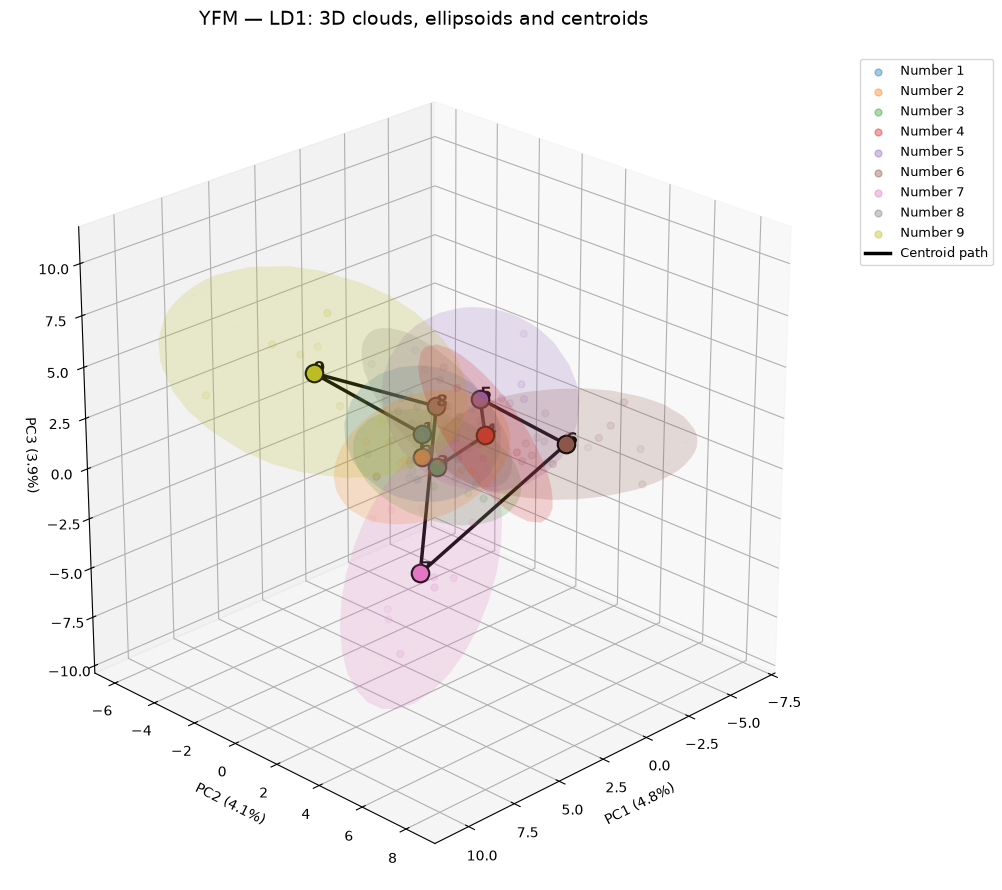

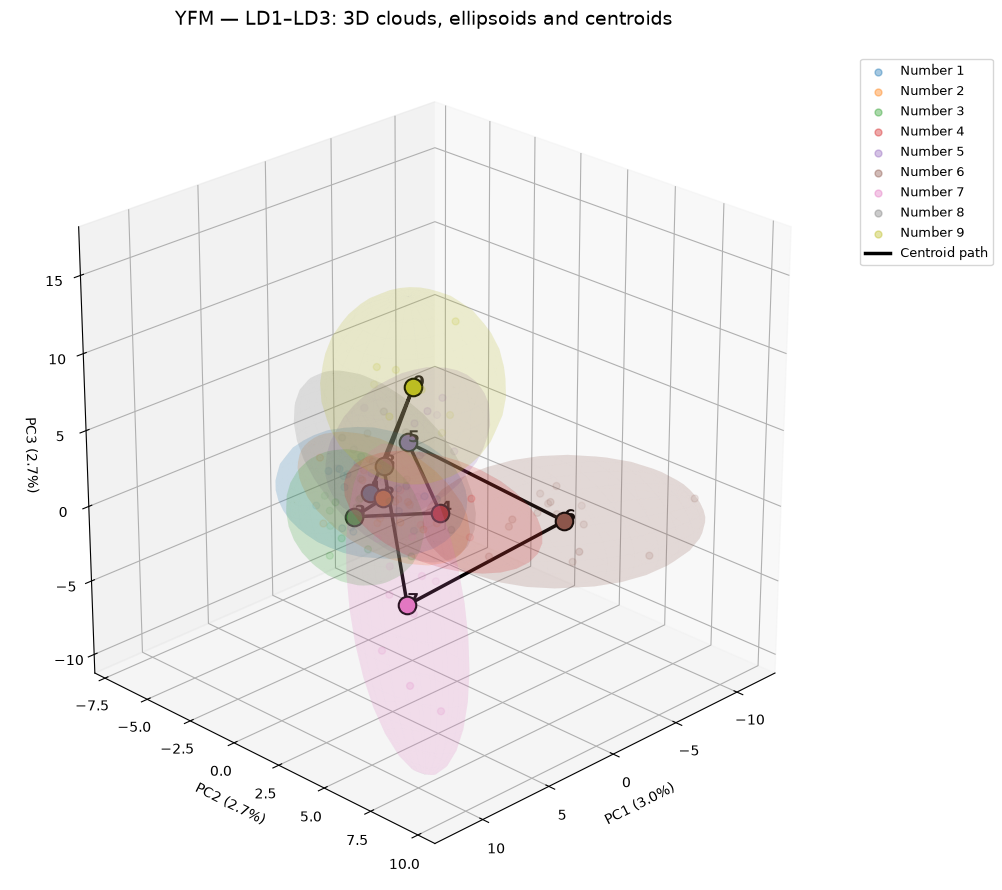

In [257]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import chi2

numbers = np.arange(1, 10)
colors = plt.get_cmap("tab10").colors[:9]

def draw_ellipsoid(ax, points, color, confidence=0.95):
    """Draw a 3D Gaussian covariance ellipsoid."""
    if len(points) < 4:
        return

    center = points.mean(axis=0)
    cov = np.cov(points, rowvar=False)

    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    eigenvalues = np.maximum(eigenvalues, 0)

    radius = np.sqrt(chi2.ppf(confidence, df=3))

    u = np.linspace(0, 2 * np.pi, 24)
    v = np.linspace(0, np.pi, 16)

    sphere = np.array([
        np.outer(np.cos(u), np.sin(v)).ravel(),
        np.outer(np.sin(u), np.sin(v)).ravel(),
        np.outer(np.ones_like(u), np.cos(v)).ravel()
    ])

    surface = (
        eigenvectors
        @ np.diag(radius * np.sqrt(eigenvalues))
        @ sphere
    ) + center[:, None]

    shape = (len(u), len(v))

    ax.plot_surface(
        surface[0].reshape(shape),
        surface[1].reshape(shape),
        surface[2].reshape(shape),
        color=color,
        alpha=0.10,
        linewidth=0,
        shade=False
    )

def plot_static_lda_geometry(Z, y, title):
    # PCA on all presentation-level population vectors
    pca = PCA(n_components=3)
    cloud = pca.fit_transform(Z)

    centers = np.vstack([
        cloud[y == k].mean(axis=0)
        for k in numbers
    ])

    fig = plt.figure(figsize=(11, 9))
    ax = fig.add_subplot(111, projection="3d")

    # Presentation clouds and ellipsoids
    for i, k in enumerate(numbers):
        points = cloud[y == k]

        ax.scatter(
            points[:, 0],
            points[:, 1],
            points[:, 2],
            color=colors[i],
            s=25,
            alpha=0.40,
            label=f"Number {k}"
        )

        draw_ellipsoid(ax, points, colors[i])

    # Closed path: 1 -> 2 -> ... -> 9 -> 1
    closed = np.vstack([centers, centers[0]])

    ax.plot(
        closed[:, 0],
        closed[:, 1],
        closed[:, 2],
        color="black",
        linewidth=2.5,
        label="Centroid path"
    )

    # Centroids and number labels
    for i, k in enumerate(numbers):
        ax.scatter(
            *centers[i],
            color=colors[i],
            s=160,
            edgecolors="black",
            linewidth=1.5,
            depthshade=False
        )

        ax.text(
            *centers[i],
            str(k),
            fontsize=12,
            fontweight="bold"
        )

    variance = pca.explained_variance_ratio_ * 100

    ax.set_xlabel(f"PC1 ({variance[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({variance[1]:.1f}%)")
    ax.set_zlabel(f"PC3 ({variance[2]:.1f}%)")

    ax.set_title(title, fontsize=14, pad=20)

    ax.view_init(elev=25, azim=45)
    ax.set_box_aspect((1, 1, 1))

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        fontsize=9
    )

    plt.tight_layout()
    plt.show()


# FIGURE 1 — LD1 only
plot_static_lda_geometry(
    Z1, y,
    "YFM — LD1: 3D clouds, ellipsoids and centroids"
)

# FIGURE 2 — LD1–LD3
plot_static_lda_geometry(
    Z3, y,
    "YFM — LD1–LD3: 3D clouds, ellipsoids and centroids"
)


Selected neurons: 47
LD1 shape: (114, 47)
LD1-LD3 shape: (114, 141)
Number of dichotomies: 255

Running LD1 ...
Dichotomies evaluated: 255
Mean SSD: 0.7287
Median: 0.734
SD: 0.0668

Running LD1-LD3 ...
Dichotomies evaluated: 255
Mean SSD: 0.7891
Median: 0.7874
SD: 0.0515


,Representation,Split,Dichotomies,Mean accuracy,Valid dichotomies
0,LD1,1 vs 8,9,0.7982,9
1,LD1,2 vs 7,36,0.7443,36
2,LD1,3 vs 6,84,0.7291,84
3,LD1,4 vs 5,126,0.7190,126
4,LD1-LD3,1 vs 8,9,0.8178,9
5,LD1-LD3,2 vs 7,36,0.8065,36
6,LD1-LD3,3 vs 6,84,0.7897,84
7,LD1-LD3,4 vs 5,126,0.7816,126


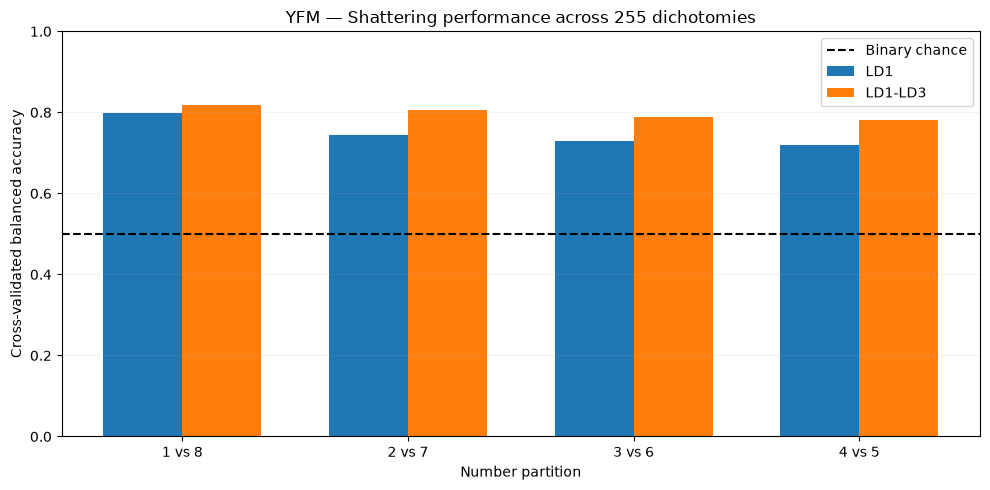

In [258]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import balanced_accuracy_score

# ===================================================
# 1. Original paper-style neuron selection
# ===================================================

original_perm = pd.read_csv(
    repo_root / "notebooks2" / "tables2"
    / "single_neuron_lda_permutation_results.csv"
)

selected = (
    original_perm.loc[
        (original_perm["subject"] == "YFM")
        & (original_perm["p_value"] <= 0.125),
        "neuron"
    ]
    .astype(int)
    .sort_values()
    .to_numpy()
)

assert len(selected) > 0

# Extract the corresponding 3-feature blocks
idx3 = (
    3 * selected[:, None] + np.arange(3)
).ravel()

representations = {
    "LD1": Z1[:, selected],
    "LD1-LD3": Z3[:, idx3]
}

print("Selected neurons:", len(selected))
for name, X in representations.items():
    print(name, "shape:", X.shape)

# ===================================================
# 2. All 255 unique number dichotomies
# ===================================================

numbers = np.arange(1, 10)

dichotomies = [
    (tuple(side), size)
    for size in range(1, 5)
    for side in combinations(numbers, size)
]

assert len(dichotomies) == 255

print("Number of dichotomies:", len(dichotomies))

# ===================================================
# 3. Trial-grouped binary decoding
# ===================================================

def shattering_scores(X, y, trials):
    records = []

    for side, split_size in dichotomies:

        binary_y = np.isin(y, side).astype(int)

        cv = StratifiedGroupKFold(
            n_splits=3,
            shuffle=True,
            random_state=42
        )

        fold_scores = []

        for train_idx, test_idx in cv.split(
            X, binary_y, groups=trials
        ):
            train_y = binary_y[train_idx]
            test_y = binary_y[test_idx]

            # Both classes must be represented
            if (
                len(np.unique(train_y)) < 2
                or len(np.unique(test_y)) < 2
            ):
                continue

            model = make_pipeline(
                StandardScaler(),
                LinearSVC(
                    C=1.0,
                    class_weight="balanced",
                    dual="auto",
                    max_iter=5000,
                    random_state=42
                )
            )

            model.fit(X[train_idx], train_y)
            prediction = model.predict(X[test_idx])

            fold_scores.append(
                balanced_accuracy_score(
                    test_y, prediction
                )
            )

        records.append({
            "split": str(side),
            "split_size": split_size,
            "accuracy": (
                np.mean(fold_scores)
                if fold_scores else np.nan
            ),
            "valid_folds": len(fold_scores)
        })

    return pd.DataFrame(records)

# ===================================================
# 4. Run LD1 and LD1-LD3
# ===================================================

results_ssd = {}

for name, X in representations.items():

    print(f"\nRunning {name} ...")

    results_ssd[name] = shattering_scores(
        X, y, trials
    )

    scores = results_ssd[name]["accuracy"]

    print("Dichotomies evaluated:", scores.notna().sum())
    print("Mean SSD:", round(scores.mean(), 4))
    print("Median:", round(scores.median(), 4))
    print("SD:", round(scores.std(), 4))

# ===================================================
# 5. Summary by split size
# ===================================================

summary_rows = []

for name, df in results_ssd.items():
    for split_size, group in df.groupby("split_size"):
        summary_rows.append({
            "Representation": name,
            "Split": f"{split_size} vs {9-split_size}",
            "Dichotomies": len(group),
            "Mean accuracy": group["accuracy"].mean(),
            "Valid dichotomies": group["accuracy"].notna().sum()
        })

ssd_summary = pd.DataFrame(summary_rows)

display(ssd_summary.round(4))

# ===================================================
# 6. Static comparison plot
# ===================================================

fig, ax = plt.subplots(figsize=(10, 5))

split_labels = ["1 vs 8", "2 vs 7", "3 vs 6", "4 vs 5"]
x = np.arange(len(split_labels))
width = 0.35

for i, name in enumerate(["LD1", "LD1-LD3"]):

    values = (
        ssd_summary[
            ssd_summary["Representation"] == name
        ]["Mean accuracy"].to_numpy()
    )

    ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=name
    )

ax.axhline(
    0.5,
    color="black",
    linestyle="--",
    label="Binary chance"
)

ax.set_xticks(x)
ax.set_xticklabels(split_labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Cross-validated balanced accuracy")
ax.set_xlabel("Number partition")
ax.set_title("YFM — Shattering performance across 255 dichotomies")
ax.legend()
ax.grid(axis="y", alpha=0.15)

plt.tight_layout()
plt.show()


In [ ]:
 x